### **Model Logging**

In [1]:
"""
parse_model_logs.py — Parser for model-level simulation logs.
==============================================================
Produces two structured CSVs per versioned run:

  1. model_state_{v}.csv      — one row per step with all model state metrics
  2. defection_events_{v}.csv — one row per defection event with threshold,
                                 defection_level (high/medium/low), and rank

Directory layout
────────────────
INPUT  (flat — all runs in one folder, one file per run):
    <PROJECT_ROOT>/SimulationLogs/gemini_flash/ZeroShot/stateful/vision-4/
        ModelLogging/unstructured-logs/
            model_simulation_log_v1.txt
            …

OUTPUT (flat):
    <PROJECT_ROOT>/SimulationLogs/gemini_flash/ZeroShot/stateful/vision-4/
        ModelLogging/structured/
            model_state_v1.csv
            defection_events_v1.csv
            …

Usage
─────
    python parse_model_logs.py
"""

from __future__ import annotations

import csv
import glob
import json
import re
from collections import Counter
from pathlib import Path

# ─────────────────────────────────────────────────────────────────────────────
# DIRECTORY CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent
# PROVIDER = "llama3.1-8B-Instruct_ZeroShot"
# PROVIDER = "llama3.1-70B-Instruct-AWQ_CoT"
# PROVIDER = "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot"
PROVIDER = "qwen3-8B_ZeroShot"

# PROMPT_TYPE = "CoT"
PROMPT_TYPE = "ZeroShot"

_LOGS_BASE = (
    PROJECT_ROOT
    / "SimulationLogs" / PROVIDER /PROMPT_TYPE
    / "stateful"       / "vision-4"
    / "ModelLogging"
)

DIRS = {
    "model_dir":        _LOGS_BASE / "unstructured-logs",
    "model_output_dir": _LOGS_BASE / "structured",
}

OUTPUT_STATE_TPL     = "ModelLogs/model_state_{v}.csv"
OUTPUT_DEFECTION_TPL = "DefectionLogs/defection_events_{v}.csv"


# ─────────────────────────────────────────────────────────────────────────────
# REGEX PATTERNS
# ─────────────────────────────────────────────────────────────────────────────

STEP_HEADER    = re.compile(r"^\[Step\s+(\d+)\]\s+\[MODEL\]")
KV_PATTERN     = re.compile(r"(\w+)=([^\s]+)")
INIT_PILLARS   = re.compile(r"\[INIT\]\s+PILLAR_TYPE_COUNTS:\s+(\{.*\})")
DEFECTED_INST  = re.compile(r"defected_institutions=(.+?)(?:\s+\w+=|$)")
INSTITUTION_RE = re.compile(r"institution=(.+?)\s+threshold=")


# ─────────────────────────────────────────────────────────────────────────────
# PARSER
# ─────────────────────────────────────────────────────────────────────────────

def _parse_kv(line: str) -> dict[str, str]:
    return {m.group(1): m.group(2) for m in KV_PATTERN.finditer(line)}


def parse_model_log(filepath: Path) -> tuple[dict, list[dict]]:
    """
    Parse a single model log file.

    Collects:
      - init_info  : PILLAR_TYPE_COUNTS, q33/q66 from step-0 defect_levels,
                     and institution→threshold map from FIRST_DEFECTION lines
      - state_rows : one row per model_state event

    Returns
    -------
    init_info  : dict
    state_rows : list[dict]
    """
    # ── Define NAVCO-style Tiers ──────────────────────────────────────────
    # Logic: Rate = 0.001% relative to a large population
    def get_navco_tier(size):
        # if size < 2:   return -1 # Not a movement yet
        if size <= 2:  return 0  # Tier 0: 1-2 agents
        if size <= 6:  return 1  # Tier 1: 3-6 agents
        if size <= 16: return 2  # Tier 2: 7-16 agents
        if size <= 80: return 3  # Tier 3: 17-80 agents
        if size <= 160:return 4  # Tier 4: 81-160 agents
        return 5                 # Tier 5: > 160 agents


    init_info:  dict       = {
        "pillar_type_counts": {},
        "total_pillars": 0,
        "q33": None,        # defection-level quantile cutoffs from step 0
        "q66": None,
        "thresholds": {},   # institution -> threshold (from FIRST_DEFECTION lines)
    }
    state_rows: list[dict] = []

    with open(filepath, "r", encoding="utf-8", errors="replace") as fh:
        for raw_line in fh:
            line = raw_line.strip()
            if not line:
                continue

            # ── [INIT] PILLAR_TYPE_COUNTS ─────────────────────────────────
            m = INIT_PILLARS.search(line)
            if m:
                try:
                    init_info["pillar_type_counts"] = json.loads(m.group(1))
                    init_info["total_pillars"] = sum(
                        init_info["pillar_type_counts"].values()
                    )
                except json.JSONDecodeError:
                    init_info["pillar_type_counts_raw"] = m.group(1)
                continue

            # ── Lines with a [Step N] header ──────────────────────────────
            step_match = STEP_HEADER.match(line)
            if not step_match:
                continue
            step = int(step_match.group(1))

            # ── defect_levels (step 0) → q33/q66 cutoffs ─────────────────
            if "event=defect_levels" in line:
                kv = _parse_kv(line)
                # Only capture once — step 0 values are the initial distribution
                if init_info["q33"] is None:
                    try:
                        init_info["q33"] = float(kv.get("q33", 0))
                        init_info["q66"] = float(kv.get("q66", 0))
                    except (ValueError, TypeError):
                        pass
                continue

            # ── FIRST_DEFECTION → institution threshold map ───────────────
            if "event=FIRST_DEFECTION" in line:
                kv = _parse_kv(line)
                inst_m = INSTITUTION_RE.search(line)
                institution = inst_m.group(1).strip() if inst_m else kv.get("institution", "")
                try:
                    threshold = float(kv.get("threshold", 0))
                except (ValueError, TypeError):
                    threshold = None
                # Only store the first threshold seen per institution
                # (subsequent instances will have higher thresholds by design)
                if institution and institution not in init_info["thresholds"]:
                    init_info["thresholds"][institution] = threshold
                continue

            # ── model_state ───────────────────────────────────────────────
            if "event=model_state" in line:
                kv = _parse_kv(line)

                di_match = DEFECTED_INST.search(line)
                defected_raw = di_match.group(1).strip() if di_match else "none"
                if defected_raw.lower() == "none" or defected_raw == "":
                    defected_list = []
                else:
                    defected_list = [s.strip() for s in defected_raw.split(",")]

                state_rows.append({
                    "step":                step,
                    "elapsed_s":           kv.get("elapsed", "").rstrip("s"),
                    "legitimacy":          kv.get("legitimacy", ""),
                    "nvCitizen":           kv.get("nvCitizen", ""),
                    "protestingCitizen":   kv.get("protestingCitizen", ""),
                    "protestingActivists": kv.get("protestingActivists", ""),
                    # "resistanceSize":      int(kv.get("protestingCitizen", 0)),
                    # "campSize":            get_navco_tier(int(kv.get("protestingCitizen", 0))),
                    "resistanceSize":      int(kv.get("protestingCitizen", 0)) + int(kv.get("protestingActivists", 0)),
                    "campSize":            get_navco_tier(int(kv.get("protestingCitizen", 0)) + int(kv.get("protestingActivists", 0))),
                    "jailedActivists":     kv.get("jailedActivists", ""),
                    "activists":           kv.get("activists", ""),
                    "police":              kv.get("police", ""),
                    "pillars":             kv.get("pillars", ""),
                    "victory":             kv.get("victory", ""),
                    "defected_count":      len(defected_list),
                    "defected_institutions": "|".join(defected_list),
                    "GrievanceLow":        kv.get("GrievanceLow", ""),
                    "GrievanceMedium":     kv.get("GrievanceMedium", ""),
                    "GrievanceHigh":       kv.get("GrievanceHigh", ""),
                    "q33":                 kv.get("q33", ""),
                    "q66":                 kv.get("q66", ""),
                })

    return init_info, state_rows


# ─────────────────────────────────────────────────────────────────────────────
# DEFECTION LEVEL + RANK HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def _defection_level(threshold: float | None, q33: float | None, q66: float | None) -> str:
    """
    Assign defection propensity level based on where the threshold falls
    relative to the population quantiles logged at step 0.

      threshold <= q33  →  "high"    (low threshold = defects early/easily)
      threshold <= q66  →  "medium"
      threshold >  q66  →  "low"     (high threshold = defects late/rarely)

    Returns "" if any value is missing.
    """
    if threshold is None or q33 is None or q66 is None:
        return ""
    if threshold <= q33:
        return "high"
    if threshold <= q66:
        return "medium"
    return "low"


def _institution_rank(institution: str, pillar_type_counts: dict) -> int:
    """
    Derive the ordinal rank of an institution type based on the sorted
    PILLAR_TYPE_COUNTS order (lower rank = lower threshold = defects earlier).

    Institutions are ordered by their position in the counts dict, which
    preserves insertion order (Python 3.7+) and reflects the NAVCO frequency
    ordering used when building PILLAR_ASSIGNMENT_LIST.

    Returns 0-based rank, or -1 if not found.
    """
    for rank, inst in enumerate(pillar_type_counts.keys()):
        if inst == institution:
            return rank + 1
    return -1


# ─────────────────────────────────────────────────────────────────────────────
# DERIVE DEFECTION EVENTS FROM STATE
# ─────────────────────────────────────────────────────────────────────────────

def extract_defections_from_state(
    state_rows: list[dict],
    init_info: dict,
) -> list[dict]:
    """
    Derive defection events by watching defected_institutions grow across steps.

    Uses Counter so duplicate institution names are handled correctly —
    each additional occurrence is a separate defection event.

    Enriches each event with:
      threshold        — from FIRST_DEFECTION log lines (init_info["thresholds"])
      defection_level  — high / medium / low based on q33/q66 cutoffs
      rank             — ordinal position of institution type (0 = earliest defector)
    """
    defect_rows:  list[dict] = []
    prev_counter: Counter    = Counter()

    q33 = init_info.get("q33")
    q66 = init_info.get("q66")
    thresholds      = init_info.get("thresholds", {})
    pillar_counts   = init_info.get("pillar_type_counts", {})

    for row in state_rows:
        raw = row.get("defected_institutions", "")
        if raw and raw.lower() != "none":
            entries = [s.strip() for s in raw.split("|") if s.strip()]
            current_counter: Counter = Counter(entries)
        else:
            current_counter = Counter()

        all_institutions = set(current_counter) | set(prev_counter)
        for institution in sorted(all_institutions):
            increase = current_counter[institution] - prev_counter[institution]
            for _ in range(increase):
                threshold = thresholds.get(institution)
                defect_rows.append({
                    "step":            row["step"],
                    "institution":     institution,
                    "defected_total":  sum(current_counter.values()),
                    "threshold":       threshold if threshold is not None else "",
                    # "defection_level": _defection_level(threshold, q33, q66),
                    "rank":            _institution_rank(institution, pillar_counts),
                })

        prev_counter = current_counter

    return sorted(defect_rows, key=lambda r: r["step"])


# ─────────────────────────────────────────────────────────────────────────────
# CSV WRITERS
# ─────────────────────────────────────────────────────────────────────────────

STATE_COLUMNS = [
    "step", "elapsed_s", "legitimacy",
    "nvCitizen", "protestingCitizen", "protestingActivists",
    "resistanceSize", "campSize",
    "jailedActivists", "activists", "police", "pillars",
    "victory", "defected_count", "defected_institutions",
    "GrievanceLow", "GrievanceMedium", "GrievanceHigh",
    "q33", "q66",
]

DEFECTION_COLUMNS = [
    "step", "institution", "defected_total",
    "threshold", "rank",
]


def write_csv(rows: list[dict], columns: list[str], output_path: Path):
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, "w", newline="", encoding="utf-8") as fh:
        writer = csv.DictWriter(fh, fieldnames=columns, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)
    print(f"  -> {output_path}  ({len(rows)} rows)")


# ─────────────────────────────────────────────────────────────────────────────
# DISCOVER RUNS
# ─────────────────────────────────────────────────────────────────────────────

def _version_num(p: str) -> int:
    m = re.search(r"_v(\d+)\.txt$", p, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def discover_versions() -> list[tuple[Path, Path, str]]:
    input_base  = DIRS["model_dir"]
    output_base = DIRS["model_output_dir"]

    log_files = sorted(
        glob.glob(str(input_base / "model_simulation_log_v*.txt")),
        key=_version_num,
    )

    if not log_files:
        raise FileNotFoundError(
            f"No model_simulation_log_v*.txt files found in:\n  {input_base}\n"
            "Check that PROJECT_ROOT points to the right place."
        )

    return [
        (Path(fp), output_base, f"v{_version_num(fp)}")
        for fp in log_files
    ]


# ─────────────────────────────────────────────────────────────────────────────
# SUMMARY
# ─────────────────────────────────────────────────────────────────────────────

def print_summary(
    version_label: str,
    init_info: dict,
    state_rows: list[dict],
    defect_rows: list[dict],
):
    print(f"\n  {'─'*65}")
    print(f"  Summary [{version_label}]")
    print(f"  {'─'*65}")

    if init_info.get("pillar_type_counts"):
        print("  Initial pillar counts:")
        for inst, count in init_info["pillar_type_counts"].items():
            print(f"    {inst:<35} {count}")
        print(f"    {'TOTAL':<35} {init_info.get('total_pillars', '?')}")

    if init_info.get("q33") is not None:
        print(f"\n  Defection level cutoffs:  q33={init_info['q33']}  q66={init_info['q66']}")

    print(f"\n  Steps parsed    : {len(state_rows)}")
    if state_rows:
        final = state_rows[-1]
        print(f"  Final step      : {final['step']}")
        print(f"  Final victory   : {final['victory']}")
        print(f"  Final legitimacy: {final['legitimacy']}")
        print(f"  Final defections: {final['defected_count']}  "
              f"({final['defected_institutions']})")

    print(f"\n  Defection events: {len(defect_rows)}")
    if defect_rows:
        print(f"  {'Institution':<35} {'Step':>5}  {'Threshold':>10}  {'Level':>8}  {'Rank':>5}  {'Total':>6}")
        for r in defect_rows:
            print(
                f"    {r['institution']:<35} {r['step']:>5}  "
                f"{str(r['threshold']):>10}  " 
                # {r['defection_level']:>8}  "
                f"{r['rank']:>5}  {r['defected_total']:>6}"
            )


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────

def process_version(log_file: Path, output_dir: Path, version_label: str):
    print(f"\n{'─'*60}")
    print(f"  Run   : {version_label}")
    print(f"  Input : {log_file}")
    print(f"  Output: {output_dir}")
    print(f"{'─'*60}")

    init_info, state_rows = parse_model_log(log_file)
    defect_rows = extract_defections_from_state(state_rows, init_info)

    write_csv(state_rows,  STATE_COLUMNS,     output_dir / OUTPUT_STATE_TPL.format(v=version_label))
    write_csv(defect_rows, DEFECTION_COLUMNS, output_dir / OUTPUT_DEFECTION_TPL.format(v=version_label))

    print_summary(version_label, init_info, state_rows, defect_rows)


if __name__ == "__main__":
    runs = discover_versions()
    print(f"Discovered {len(runs)} run(s): "
          f"{', '.join(v for _, _, v in runs)}")

    for log_file, output_dir, version_label in runs:
        process_version(log_file, output_dir, version_label)

    print("\n✓ All model log runs processed.")

    # 9, 21, 22, 25, 30, 31,32,33,35,36,37,38,39,40
    86-9, 87-21, 88-22, 89-25, 90-30, 94-5

Discovered 100 run(s): v1, v2, v3, v4, v5, v6, v7, v8, v9, v10, v11, v12, v13, v14, v15, v16, v17, v18, v19, v20, v21, v22, v23, v24, v25, v26, v27, v28, v29, v30, v31, v32, v33, v34, v35, v36, v37, v38, v39, v40, v41, v42, v43, v44, v45, v46, v47, v48, v49, v50, v51, v52, v53, v54, v55, v56, v57, v58, v59, v60, v61, v62, v63, v64, v65, v66, v67, v68, v69, v70, v71, v72, v73, v74, v75, v76, v77, v78, v79, v80, v81, v82, v83, v84, v85, v86, v87, v88, v89, v90, v91, v92, v93, v94, v95, v96, v97, v98, v99, v100

────────────────────────────────────────────────────────────
  Run   : v1
  Input : c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\qwen3-8B_ZeroShot\ZeroShot\stateful\vision-4\ModelLogging\unstructured-logs\model_simulation_log_v1.txt
  Output: c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\qwen3-8B_ZeroShot\ZeroShot\stateful\vision-4\ModelLogging\structured
────────────────────────────────────────────────────────────
  -> 

### **Defection Order**

In [2]:
"""
defection_order_plot.py
=======================
Reads defection_events_v*.csv files (one per run) and plots:

  For each defection position (1st, 2nd, 3rd):
    → % of runs where each institution held that position

Output
------
    defection_order_breakdown.png   — grouped bar chart (1 group per position)
    defection_order_breakdown.csv   — raw percentages table
"""

from __future__ import annotations

import csv
import glob
import re
from collections import defaultdict
from pathlib import Path

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent
_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / PROVIDER / PROMPT_TYPE
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

INPUT_GLOB   = str(_STRUCTURED / "DefectionLogs" / "defection_events_v*.csv")
OUTPUT_PLOT  = _STRUCTURED / "DefectionAnalysis" / "defection_order_breakdown.png"
OUTPUT_CSV   = _STRUCTURED / "DefectionAnalysis" / "defection_order_breakdown.csv"

# How many ordinal positions to analyse (1st, 2nd, 3rd)
N_POSITIONS  = 3
POSITION_LABELS = {1: "1st Defector", 2: "2nd Defector", 3: "3rd Defector"}

# Canonical institution order — x-axis always shows all pillars in this order.
# Institutions that never defected in any run will appear with 0% bars.
UNIQUE_PILLAR_TYPES = [
    "Educational System",
    "Trade Unions",
    "Religious Institutions",
    "Professional Associations",
    "Independent Media",
    "Business Community",
    "Civil Service",
    "Local Government",
    "Parliament",
    "Supreme Court",
    "State Media",
]


# ─────────────────────────────────────────────────────────────────────────────
# LOAD & PARSE
# ─────────────────────────────────────────────────────────────────────────────

def _version_num(p: str) -> int:
    m = re.search(r"_v(\d+)\.csv$", p, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def load_all_runs(glob_pattern: str) -> dict[str, list[dict]]:
    """
    Returns {version_label: [row, row, …]} sorted by step ascending.
    Each row is a dict from the CSV.
    """
    files = sorted(glob.glob(glob_pattern), key=_version_num)
    if not files:
        raise FileNotFoundError(f"No files matched:\n  {glob_pattern}")

    runs = {}
    for fp in files:
        label = f"v{_version_num(fp)}"
        with open(fp, newline="", encoding="utf-8") as fh:
            rows = list(csv.DictReader(fh))
        # Sort by step so position 0 = first defection in that run
        rows.sort(key=lambda r: int(r.get("step", 0)))
        runs[label] = rows

    print(f"Loaded {len(runs)} run(s): {list(runs.keys())}")
    return runs


# ─────────────────────────────────────────────────────────────────────────────
# COMPUTE POSITION PERCENTAGES
# ─────────────────────────────────────────────────────────────────────────────

def compute_position_counts(
    runs: dict[str, list[dict]],
    n_positions: int = 3,
) -> tuple[dict[int, dict[str, int]], int]:
    """
    For each ordinal position 1..n_positions, count how many runs each
    institution occupied that position.

    Returns
    -------
    position_counts : {position: {institution: count}}
    total_runs      : total number of runs loaded (denominator for %)
    """
    # {position (1-based): {institution: count}}
    position_counts: dict[int, dict[str, int]] = {
        pos: defaultdict(int) for pos in range(1, n_positions + 1)
    }

    for version, rows in runs.items():
        for pos in range(1, n_positions + 1):
            idx = pos - 1
            if idx < len(rows):
                institution = rows[idx].get("institution", "").strip()
                if institution:
                    position_counts[pos][institution] += 1
            # If run has fewer than pos defections — skip (don't count)

    return position_counts, len(runs)


def to_percentages(
    position_counts: dict[int, dict[str, int]],
    total_runs: int,
) -> dict[int, dict[str, float]]:
    """Convert raw counts to percentages of total_runs."""
    return {
        pos: {inst: round(cnt / total_runs * 100, 1)
              for inst, cnt in sorted(inst_counts.items(),
                                      key=lambda x: -x[1])}
        for pos, inst_counts in position_counts.items()
    }


# ─────────────────────────────────────────────────────────────────────────────
# CSV EXPORT
# ─────────────────────────────────────────────────────────────────────────────

def save_csv(
    pct: dict[int, dict[str, float]],
    total_runs: int,
    output_path: Path,
):
    """
    Wide format:
        institution | 1st_defector_pct | 2nd_defector_pct | 3rd_defector_pct
    """
    # Use canonical order so every institution appears even if never defected
    all_insts = UNIQUE_PILLAR_TYPES

    output_path.parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, "w", newline="", encoding="utf-8") as fh:
        cols = ["institution"] + [
            f"pos_{pos}_pct" for pos in sorted(pct)
        ] + ["total_runs"]
        writer = csv.DictWriter(fh, fieldnames=cols)
        writer.writeheader()
        for inst in all_insts:
            row = {"institution": inst, "total_runs": total_runs}
            for pos in sorted(pct):
                row[f"pos_{pos}_pct"] = pct[pos].get(inst, 0.0)
            writer.writerow(row)

    print(f"  CSV  → {output_path}")


# ─────────────────────────────────────────────────────────────────────────────
# PLOT
# ─────────────────────────────────────────────────────────────────────────────

def plot_defection_order(
    pct: dict[int, dict[str, float]],
    total_runs: int,
    output_path: Path,
):
    try:
        import matplotlib.pyplot as plt
        import matplotlib.ticker as ticker
        import numpy as np
    except ImportError:
        print("  matplotlib / numpy not installed — pip install matplotlib numpy")
        return

    # Use canonical order — includes all pillars even if never defected (shows 0%)
    all_insts = UNIQUE_PILLAR_TYPES

    positions  = sorted(pct)
    n_insts    = len(all_insts)
    n_pos      = len(positions)
    x          = np.arange(n_insts)       # one group per institution
    bar_width  = 0.75 / max(n_pos, 1)

    plt.style.use("seaborn-v0_8-whitegrid")

    fig, ax = plt.subplots(figsize=(max(14, n_insts * 1.4), 7))
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    # Clean spine styling
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")
    ax.tick_params(colors="#333333", labelsize=9, length=3)

    # Professional colour palette — distinct but muted
    pos_colours = {1: "#2166ac", 2: "#f4a261", 3: "#e63946"}

    for i, pos in enumerate(positions):
        offsets = x + (i - n_pos / 2 + 0.5) * bar_width
        values  = [pct.get(pos, {}).get(inst, 0.0) for inst in all_insts]
        colour  = pos_colours.get(pos, "#999999")
        bars    = ax.bar(
            offsets, values,
            width=bar_width * 0.9,
            label=POSITION_LABELS.get(pos, f"Position {pos}"),
            color=colour,
            alpha=0.85,
            edgecolor="white",
            linewidth=0.6,
        )
        # % label on bars tall enough to fit
        for bar, val in zip(bars, values):
            if val >= 0.1:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.8,
                    f"{val:.0f}%",
                    ha="center", va="bottom",
                    color="#222222", fontsize=7.5, fontweight="600",
                )

    ax.set_xticks(x)
    ax.set_xticklabels(all_insts, color="#333333", fontsize=9,
                       rotation=35, ha="right")
    ax.set_ylabel("Probability of Defection", color="#333333", fontsize=11, labelpad=8)
    ax.set_xlabel("Regime Pillars of Support", color="#333333", fontsize=11, labelpad=10)
    ax.set_title(
        f"Pillar Defection Probability by Position  (n={total_runs} runs)",
        color="#111111", fontsize=14, fontweight="bold", pad=16, loc="left",
    )
    ax.text(
        0, 1.01,
        "% of runs each institution was the 1st / 2nd / 3rd pillar to defect",
        transform=ax.transAxes, fontsize=9, color="#666666",
    )
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.set_ylim(0, 50)
    ax.yaxis.grid(True, color="#e5e5e5", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.legend(
        loc="upper right", framealpha=1.0,
        facecolor="white", edgecolor="#cccccc",
        fontsize=10, title="Defection Position",
        title_fontsize=9,
    )

    plt.tight_layout()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_path, dpi=150, bbox_inches="tight",
                facecolor="white")
    plt.close(fig)
    print(f"  Plot → {output_path}")


# ─────────────────────────────────────────────────────────────────────────────
# SUMMARY PRINT
# ─────────────────────────────────────────────────────────────────────────────

def print_summary(pct: dict[int, dict[str, float]], total_runs: int):
    print(f"\n  Total runs: {total_runs}")
    for pos in sorted(pct):
        label = POSITION_LABELS.get(pos, f"Position {pos}")
        print(f"\n  {label}")
        print(f"  {'Institution':<35} {'% of Runs':>10}")
        for inst, p in pct[pos].items():
            bar = "█" * int(p / 5)
            print(f"    {inst:<35} {p:>8.1f}%  {bar}")


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == "__main__":
    runs           = load_all_runs(INPUT_GLOB)
    pos_counts, n  = compute_position_counts(runs, N_POSITIONS)
    pct            = to_percentages(pos_counts, n)

    print_summary(pct, n)
    save_csv(pct, n, OUTPUT_CSV)
    plot_defection_order(pct, n, OUTPUT_PLOT)

    print("\n✓ Done.")

Loaded 100 run(s): ['v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7', 'v8', 'v9', 'v10', 'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 'v18', 'v19', 'v20', 'v21', 'v22', 'v23', 'v24', 'v25', 'v26', 'v27', 'v28', 'v29', 'v30', 'v31', 'v32', 'v33', 'v34', 'v35', 'v36', 'v37', 'v38', 'v39', 'v40', 'v41', 'v42', 'v43', 'v44', 'v45', 'v46', 'v47', 'v48', 'v49', 'v50', 'v51', 'v52', 'v53', 'v54', 'v55', 'v56', 'v57', 'v58', 'v59', 'v60', 'v61', 'v62', 'v63', 'v64', 'v65', 'v66', 'v67', 'v68', 'v69', 'v70', 'v71', 'v72', 'v73', 'v74', 'v75', 'v76', 'v77', 'v78', 'v79', 'v80', 'v81', 'v82', 'v83', 'v84', 'v85', 'v86', 'v87', 'v88', 'v89', 'v90', 'v91', 'v92', 'v93', 'v94', 'v95', 'v96', 'v97', 'v98', 'v99', 'v100']

  Total runs: 100

  1st Defector
  Institution                          % of Runs
    Educational System                      23.0%  ████
    Trade Unions                            16.0%  ███
    Business Community                      11.0%  ██
    Professional Associations          

### **Probability of Sucess vs Participation Size**

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# ── Global RC Settings (put at top of your script) ───────────────────────────
mpl.rcParams.update({

    # Font
    "font.family":        "serif",          # Springer uses serif (Times-like)
    "font.serif":         ["Times New Roman", "DejaVu Serif"],
    "font.size":          9,                # Base font size

    # Axes title (e.g. "Outmigrated", "Urban")
    "axes.titlesize":     10,
    "axes.titleweight":   "normal",         # NOT bold — all sample titles are normal weight
    "axes.titlepad":      6,

    # Axis labels
    "axes.labelsize":     12,
    "axes.labelpad":      5,

    # Tick labels
    "xtick.labelsize":    12,
    "ytick.labelsize":    12,
    "xtick.direction":    "out",
    "ytick.direction":    "out",
    "xtick.major.size":   3,
    "ytick.major.size":   3,

    # Legend
    "legend.fontsize":    20,
    "legend.frameon":     True,
    "legend.framealpha":  1.0,              # Fully opaque white box
    "legend.edgecolor":   "black",          # Thin black border (visible in all 3)
    "legend.borderpad":   0.4,
    "legend.labelspacing": 0.3,

    # Grid — very faint, light gray (matches all 3 figures)
    "axes.grid":          True,
    "grid.color":         "#cccccc",        # Light gray
    "grid.linestyle":     "--",
    "grid.linewidth":     0.5,
    "grid.alpha":         0.5,

    # Background — pure white, no colored axes face
    "axes.facecolor":     "white",
    "figure.facecolor":   "white",
    "axes.edgecolor":     "black",
    "axes.linewidth":     0.8,

    # Lines
    "lines.linewidth":    1.5,              # Main lines ~1.5pt as seen
    "lines.dashed_pattern": [4, 2],         # Dashed style for model/CI lines

    # Figure size — single column Springer
    "figure.figsize":     (10.8, 7.2),       # inches; ~122mm wide

    # Save
    "savefig.dpi":        1200,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.05,
    "savefig.format":     "pdf",
})


mpl.rcParams.update({
    "legend.fontsize":      12,    # entry text
    "legend.title_fontsize": 14,   # title (if you have one)
    "legend.handlelength":  2.5,   # length of the line sample
    "legend.handleheight":  1.5,   # height of the line sample
    "legend.handletextpad": 0.8,   # gap between line and text
    "legend.labelspacing":  0.6,   # vertical gap between entries
    "legend.borderpad":     0.8,   # padding inside the box
    "legend.markerscale":   1.5,   # scale up any markers
})

# ── Color Palette (matches samples exactly) ───────────────────────────────────
COLORS = {
    "low":    "#1f77b4",   # Blue
    "middle": "#ff7f0e",   # Orange
    "high":   "#2ca02c",   # Green
}

# ── Line Style Convention (Data = solid, Model/CI = dashed) ──────────────────
LINESTYLES = {
    "data":  "-",          # Solid  — observed/historical
    "model": "--",         # Dashed — simulated/model
    "ci":    ":",          # Dotted — confidence intervals
}

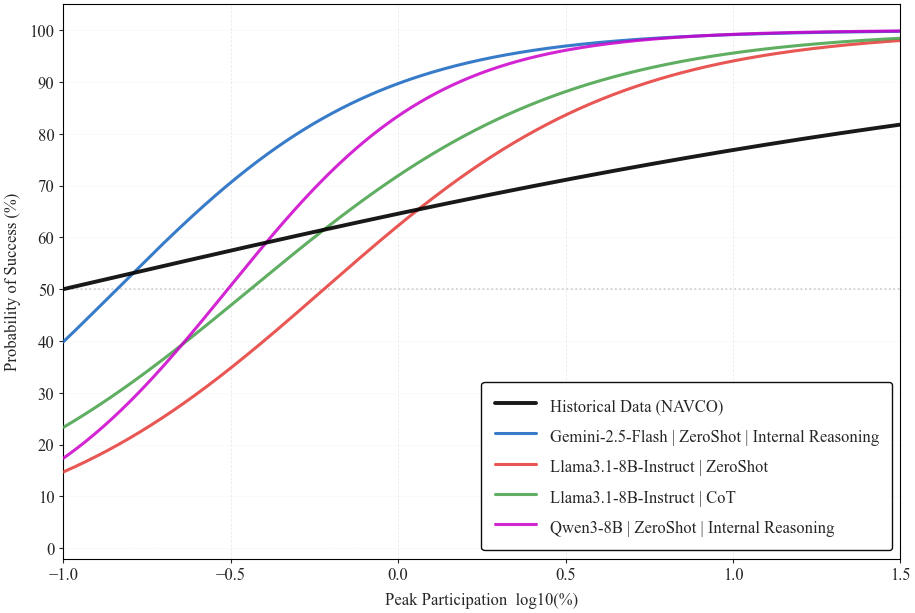

In [4]:
from probablity_win_analysis import plot_success_curves_vs_historical, plot_error_metrics_table, plot_error_curves, plot_success_curves_vs_historical_table
from pathlib import Path

plot_success_curves_vs_historical(
    # output_dir     = Path("Analysis/vllm/plots"),
    # sim_population = 1217,
    # version_start  = 1,
    # version_end    = 100,
)


In [5]:
plot_success_curves_vs_historical_table()

Processing: Gemini-2.5-Flash | ZeroShot | Internal Reasoning
Processing: Llama3.1-8B-Instruct | ZeroShot
Processing: Llama3.1-8B-Instruct | CoT
Processing: Qwen3-8B | ZeroShot | Internal Reasoning

                                           Model N Runs Victories Win Rate (%)  P(min) (%) P(min) 95% CI  P(max) (%) P(max) 95% CI
                              Historical (NAVCO)    ---       ---          ---        50.0  [41.3, 58.7]        81.8  [76.0, 86.4]
Gemini-2.5-Flash | ZeroShot | Internal Reasoning     99        75         75.8        39.7  [30.8, 49.4]        99.7  [99.6, 99.8]
                 Llama3.1-8B-Instruct | ZeroShot    100        42         42.0        15.0  [10.7, 20.7]        98.0  [97.1, 98.6]
                      Llama3.1-8B-Instruct | CoT    100        52         52.0        23.5  [17.2, 31.3]        98.3  [97.5, 98.8]
        Qwen3-8B | ZeroShot | Internal Reasoning    100        60         60.0        17.4  [12.4, 23.7]        99.8  [99.7, 99.9]

  Saved: table_

Computing errors: Gemini-2.5-Flash | ZeroShot | Internal Reasoning
Computing errors: Llama3.1-8B-Instruct | ZeroShot
Computing errors: Llama3.1-8B-Instruct | CoT
Computing errors: Qwen3-8B | ZeroShot | Internal Reasoning

ERROR METRICS vs NAVCO HISTORICAL BASELINE
                                           Model  MAE (%)  RMSE (%)  Max Error (%)  Max Error at x  AUC Diff (%)  Bias (%)
Gemini-2.5-Flash | ZeroShot | Internal Reasoning    19.27     20.64          26.27           0.284         18.40     18.39
                 Llama3.1-8B-Instruct | ZeroShot    16.17     18.25          34.98          -1.000         -0.59     -0.60
                      Llama3.1-8B-Instruct | CoT    14.39     15.63          26.48          -1.000          5.45      5.44
        Qwen3-8B | ZeroShot | Internal Reasoning    19.53     20.74          32.63          -1.000         10.76     10.74

Note:
  MAE / RMSE  — lower is better (closer to NAVCO)
  Bias > 0    — model overestimates success probability vs NAVC

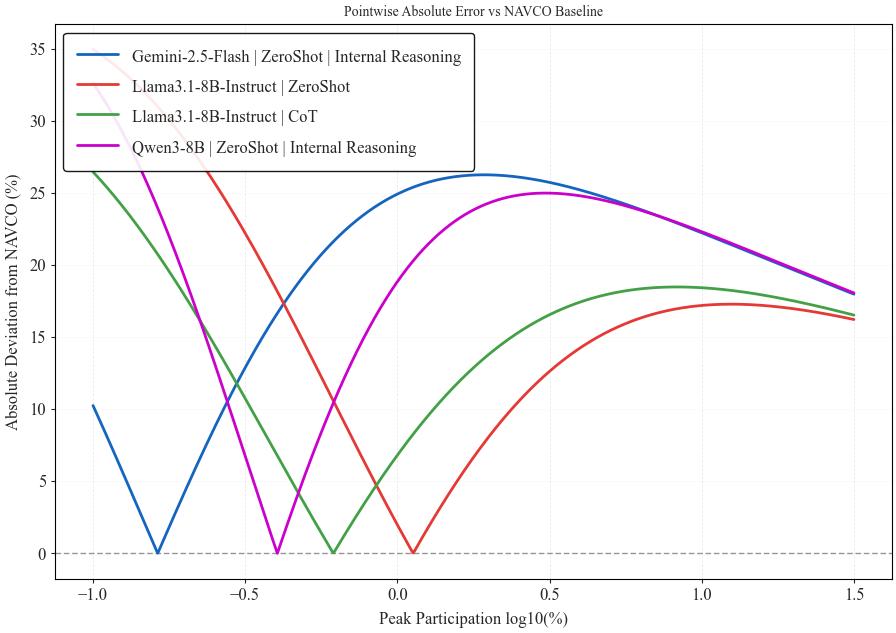

  Saved: c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\Analysis\plots\error_curves.pdf


In [6]:

# plot_success_curves_vs_historical_table()

# ── New error analysis ────────────────────────────────────────────────────
error_df = plot_error_metrics_table()
plot_error_curves()

## **Time Analysis For Individual Run**

Series([], Name: run_id, dtype: int64)


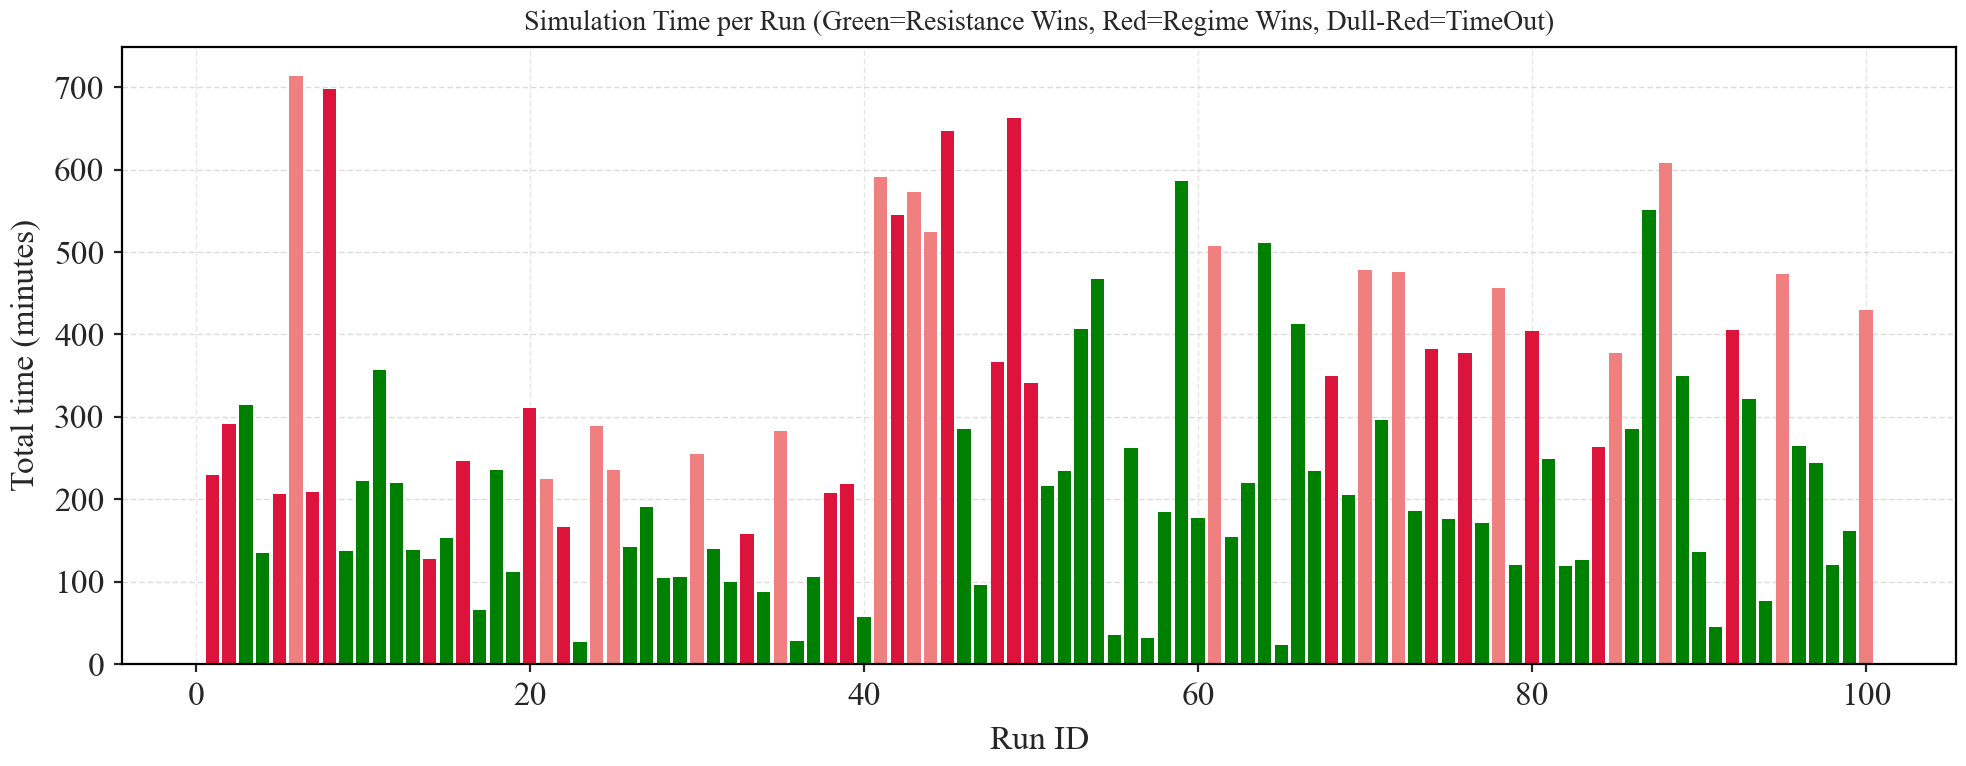

In [28]:
import pandas as pd 
import matplotlib.pyplot as plt
import glob
import re
from pathlib import Path

# Use the existing Path object logic
PROJECT_ROOT = Path.cwd().parent
# PROVIDER = "Qwen2.5-32B-Instruct-AWQ_ZeroShot"
# PROVIDER = "llama3.1-8B-Instruct_CoT-v1"
PROVIDER = "llama3.1-70B-Instruct-AWQ_CoT"
PROVIDER = "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot"
# PROVIDER = "qwen3-8B_ZeroShot_0-50"
# PROVIDER = "qwen3-8B_ZeroShot_41-87"
# PROVIDER = "qwen3-8B_ZeroShot"
PROVIDER = "qwen3-8B_ZeroShot"

PROMPT_TYPE = "ZeroShot"
_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / PROVIDER / PROMPT_TYPE
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

# 1. Define the pattern
INPUT_PATTERN = str(_STRUCTURED / "ModelLogs" / "model_state_v*.csv")

records = []

# 2. Use glob.glob to actually find the files on disk
files = glob.glob(INPUT_PATTERN)

if not files:
    print(f"No files found matching: {INPUT_PATTERN}")
else:
    for path_str in sorted(files):
        path = Path(path_str)
        df = pd.read_csv(path)
        
        # 3. Robust extraction of the version/run number
        # Looks for 'v' followed by digits (e.g., model_state_v1.csv -> 1)
        match = re.search(r'v(\d+)', path.name)
        run_id = int(match.group(1)) if match else 0
        
        # 4. Handle possible empty DataFrames safely
        if not df.empty and "elapsed_s" in df.columns:
            records.append({
                "run_id":      run_id,
                "total_min":    df["elapsed_s"].sum() / 60,
                "mean_step_s":  df["elapsed_s"].mean(),
                "n_steps":      len(df),
                "victory":      df["victory"].iloc[-1] if "victory" in df.columns else 0,
            })

if records:
    summary = pd.DataFrame(records).sort_values("run_id")
    print(summary[summary["victory"]== 0 ]["run_id"])
    # 5. Plotting with better color handling
    plt.figure(figsize=(10, 4))
    
    # Map colors: 1=Regime (Crimson), 2=Resistance (Seagreen), 3=Draw (Gray)
    colors = summary["victory"].map({1: "#DC143C", 2: "#008000", 3: "#F08080"}).fillna("blue")
        # colors = {1: "#2166ac", 2: "#f4a261", 3: "#e63946"}

    
    plt.bar(summary["run_id"], summary["total_min"], color=colors)
    plt.xlabel("Run ID")
    plt.ylabel("Total time (minutes)")
    plt.title("Simulation Time per Run (Green=Resistance Wins, Red=Regime Wins, Dull-Red=TimeOut)")
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
else:
    print("No records processed. Check if the CSV files contain 'elapsed_s' and 'victory' columns.")
    

# 89, 91, 93, 94, 97 (not useful)
# 62, 79, 91, 94, 97, 98, 100


# 5, 9, 21, 22, 25, 30, 31, 32, 33, 35, 36, 37, 38, 39, 40, 41 -- 50
# 26 false runs 0_50 qwen


# 76, 78, 79, 80, 82, 83, 84, 85, 86, 87, qwen 41-87 (10 false runs)

# 24 + 37 + 25 => 86 good runs



# 101-76, 102-78, 103-79, 81-80 (mapping from 25runs)

### **Time Distribution Analysis**:

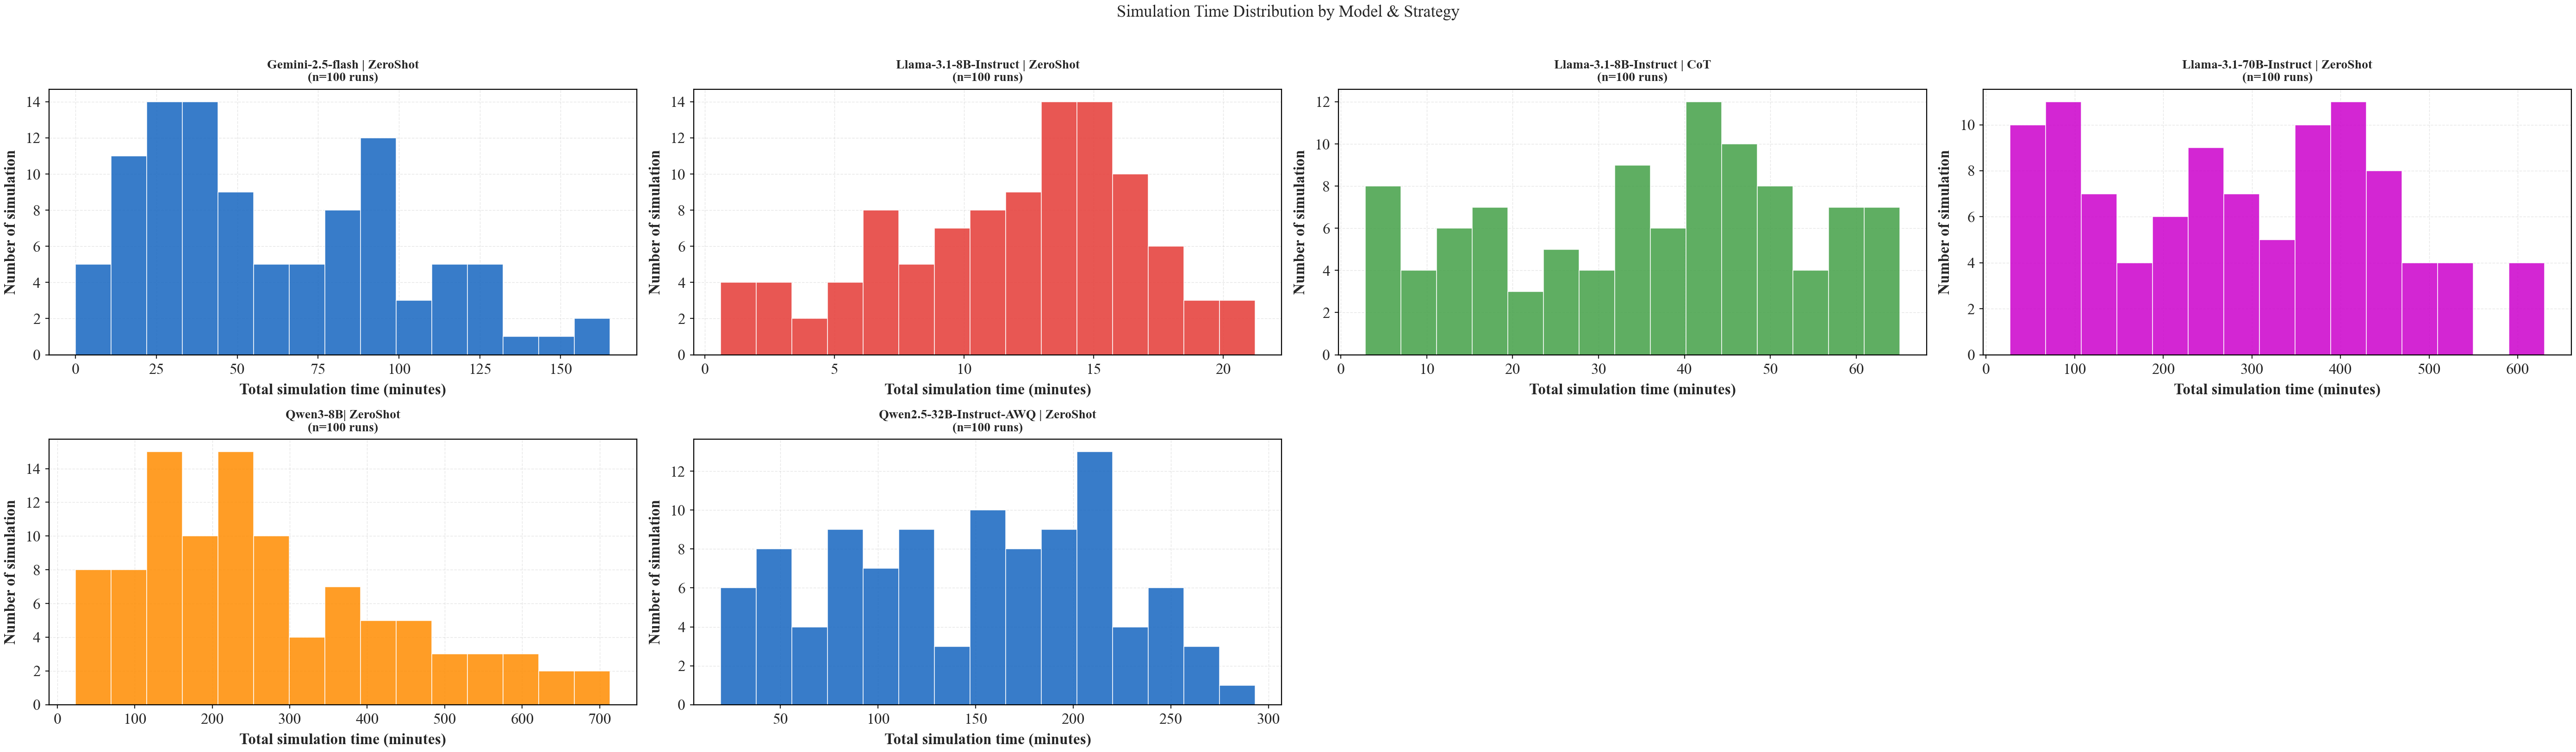

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import re
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

CONFIGS = [
    {
        "label":   "Gemini-2.5-flash | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | CoT",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT-v1" / "CoT"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-70B-Instruct | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Qwen3-8B| ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Qwen2.5-32B-Instruct-AWQ | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
]

SIM_COLORS = ["#1565C0", "#E53935", "#43A047", "#CC00CC", "#FF8C00"]

# ── Layout ───────────────────────────────────────────────────────────────────
COLS = 4
n    = len(CONFIGS)
rows = (n + COLS - 1) // COLS          # ceil division → enough rows

fig, axes = plt.subplots(rows, COLS, figsize=(7 * COLS, 4 * rows))
axes = axes.flatten()                  # always a flat list, easy to index

# ── Per-config histogram ──────────────────────────────────────────────────────
for i, cfg in enumerate(CONFIGS):
    ax    = axes[i]
    color = SIM_COLORS[i % len(SIM_COLORS)]

    pattern = str(cfg["csv_dir"] / "model_state_v*.csv")
    files   = sorted(glob.glob(pattern))

    total_mins = []
    for path_str in files:
        df = pd.read_csv(path_str)
        if not df.empty and "elapsed_s" in df.columns:
            total_mins.append(df["elapsed_s"].sum() / 60)

    if total_mins:
        ax.hist(total_mins, bins=15, color=color, edgecolor="white",
                linewidth=0.6, alpha=0.85)
        # ax.set_title(f"{cfg['label']}\n(n={len(total_mins)} runs)", fontsize=10)
        ax.set_title(f"{cfg['label']}\n(n=100 runs)", fontsize=10, weight="bold")

    else:
        ax.text(0.5, 0.5, "No data found", ha="center", va="center",
                transform=ax.transAxes, color="gray", fontsize=11)
        ax.set_title(cfg["label"], fontsize=10, weight="bold")

    ax.set_xlabel("Total simulation time (minutes)", weight="bold")
    ax.set_ylabel("Number of simulation", weight="bold")
    ax.grid(axis='y', linestyle='--', alpha=0.5)

# ── Hide any leftover empty subplots ─────────────────────────────────────────
for j in range(n, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Simulation Time Distribution by Model & Strategy", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


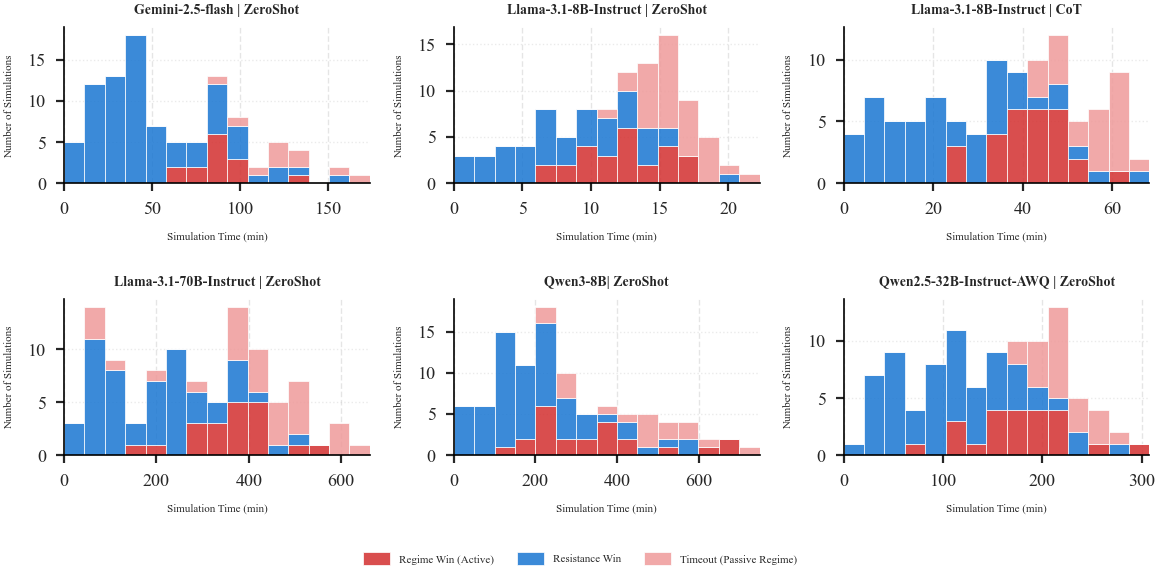

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import numpy as np
from pathlib import Path
from matplotlib import rcParams

# ── Phase 1: Springer Publication Standards ──────────────────────────────────
rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 8,            # Standard for single-column papers
    "axes.linewidth": 0.6,
    "figure.dpi": 200,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

# Outcome Mapping based on your simulation logic
OUTCOME_LABELS = {1: "Regime Win", 2: "Resistance Win", 3: "Timeout"}
OUTCOME_COLORS = ["#D32F2F", "#1976D2", "#757575"]  # Red, Blue, Grey

# Updated Outcome Mapping
# 1 & 3 are now visually linked as 'Regime-leaning' outcomes
OUTCOME_LABELS = {
    1: "Regime Win (Active)", 
    2: "Resistance Win", 
    3: "Timeout (Passive Regime)"
}

# ── Updated Palette ──────────────────────────────────────────────────────────
# [0] Dark Red for Active Win
# [1] Blue for Resistance
# [2] Muted Red/Coral for Timeout (The 'passive' version of Red)
OUTCOME_COLORS = ["#D32F2F", "#1976D2", "#EF9A9A"]

# ── Phase 2: Data Loader with Outcome Categorization ────────────────────────
def load_categorized_data(csv_dir: Path):
    pattern = str(csv_dir / "model_state_v*.csv")
    files = sorted(glob.glob(pattern))
    
    # Store time distributions for each outcome
    regime_times, resistance_times, timeout_times = [], [], []

    for path_str in files:
        df = pd.read_csv(path_str)
        if df.empty or "elapsed_s" not in df.columns or "victory" not in df.columns:
            continue
            
        total_time_min = df["elapsed_s"].sum() / 60
        final_outcome = df["victory"].iloc[-1] 
        
        if final_outcome == 1:
            regime_times.append(total_time_min)
        elif final_outcome == 2:
            resistance_times.append(total_time_min)
        else:
            timeout_times.append(total_time_min)
            
    return [regime_times, resistance_times, timeout_times]

# ── Phase 3: Plotting Loop with Dynamic X-Axes ───────────────────────────────
COLS = 3  # 2 columns is optimal for single-column readability
n = len(CONFIGS)
rows = (n + COLS - 1) // COLS

fig, axes = plt.subplots(rows, COLS, figsize=(6, 1.5 * rows), sharex=False)
axes = axes.flatten()

for i, cfg in enumerate(CONFIGS):
    ax = axes[i]
    data_by_outcome = load_categorized_data(cfg["csv_dir"])
    
    if any(len(d) > 0 for d in data_by_outcome):
        # 1. Dynamic scale calculation per model
        all_times = [t for sublist in data_by_outcome for t in sublist]
        max_val = max(all_times) if all_times else 10
        
        # 2. Plotting Stacked Histogram
        ax.hist(data_by_outcome, 
                bins=15, 
                stacked=True, 
                range=(0, max_val * 1.05),
                color=OUTCOME_COLORS, 
                label=list(OUTCOME_LABELS.values()),
                edgecolor="white", 
                linewidth=0.3, 
                alpha=0.85)
        
        # 3. Styling
        ax.set_title(cfg["label"], fontsize=5, fontweight="bold", pad=5)
        ax.set_xlim(0, max_val * 1.05)
    else:
        ax.text(0.5, 0.5, "No Data", ha="center", va="center", transform=ax.transAxes)

    ax.set_xlabel("Simulation Time (min)", fontsize=4)
    ax.set_ylabel("Number of Simulations", fontsize=4)
    ax.tick_params(labelsize=6.5)
    ax.grid(axis='y', linestyle=':', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hide leftover subplots
for j in range(n, len(axes)):
    axes[j].set_visible(False)

# ── Phase 4: Global Legend & Layout ──────────────────────────────────────────
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, 
           bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=4)

plt.tight_layout(rect=[0, 0.05, 1, 0.98], h_pad=1.5)
plt.savefig("victory_time_distribution.pdf", format='pdf')
plt.show()

In [31]:
# import pandas as pd
# import matplotlib.pyplot as plt
# import glob
# import re
# from pathlib import Path
# from scipy.stats import gaussian_kde
# import numpy as np

# PROJECT_ROOT = Path.cwd().parent

# CONFIGS = [
#     {
#         "label":   "Gemini-2.5-flash | ZeroShot | Stateful",
#         "csv_dir": PROJECT_ROOT / "SimulationLogs" / "gemini_flash" / "ZeroShot"
#                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     },
#     {
#         "label":   "Llama-3.1-8B-Instruct | ZeroShot | Stateful",
#         "csv_dir": PROJECT_ROOT / "SimulationLogs" / "vllm-8B-zeroshot" / "ZeroShot"
#                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     },
#     # {
#     #     "label":   "Llama (8B) | CoT | Stateful",
#     #     "csv_dir": PROJECT_ROOT / "SimulationLogs" / "vllm-8B-CoT" / "CoT"
#     #                / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     # },
#     {
#         "label":   "/Qwen2.5-32B-Instruct-AWQ | ZeroShot | Stateful",
#         "csv_dir": PROJECT_ROOT / "SimulationLogs" / "vllm-32B_ZeroShot" / "ZeroShot"
#                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     },
# ]


# SIM_COLORS  = ["#1565C0", "#E53935", "#43A047", "#CC00CC", "#FF8C00"]
# SIM_MARKERS = ["o", "s", "^", "D", "v"]

# # ── Layout ────────────────────────────────────────────────────────────────────
# COLS = 2
# n    = len(CONFIGS)
# rows = (n + COLS - 1) // COLS

# fig, axes = plt.subplots(rows, COLS, figsize=(7 * COLS, 4 * rows))
# axes = axes.flatten()

# # ── Per-config KDE line plot ──────────────────────────────────────────────────
# for i, cfg in enumerate(CONFIGS):
#     ax    = axes[i]
#     color = SIM_COLORS[i % len(SIM_COLORS)]

#     pattern = str(cfg["csv_dir"] / "model_state_v*.csv")
#     files   = sorted(glob.glob(pattern))

#     total_mins = []
#     for path_str in files:
#         df = pd.read_csv(path_str)
#         if not df.empty and "elapsed_s" in df.columns:
#             total_mins.append(df["elapsed_s"].sum() / 60)

#     if len(total_mins) >= 2:          # KDE needs at least 2 points
#         data = np.array(total_mins)

#         # KDE curve
#         kde  = gaussian_kde(data, bw_method="scott")
#         x    = np.linspace(data.min() - 1, data.max() + 1, 300)
#         y    = kde(x)

#         # Legend entries
#         mean_val   = data.mean()
#         median_val = np.median(data)
#         std_val    = data.std()

#         ax.plot(x, y, color=color, linewidth=2,
#                 label=f"KDE  (n={len(data)})")
#         ax.axvline(mean_val,   color=color, linestyle="--", linewidth=1.4,
#                    label=f"Mean   {mean_val:.1f} min")
#         ax.axvline(median_val, color=color, linestyle=":",  linewidth=1.4,
#                    label=f"Median {median_val:.1f} min")

#         # Shaded ±1 std band
#         ax.fill_between(x, y, where=(x >= mean_val - std_val) & (x <= mean_val + std_val),
#                         color=color, alpha=0.12,
#                         label=f"±1 std  ({std_val:.1f} min)")

#         # Rug plot — tick marks for each individual run
#         ax.plot(data, np.full_like(data, -0.002), "|", color=color,
#                 alpha=0.6, markersize=8)

#         ax.set_ylim(bottom=-0.005)
#         ax.legend(fontsize=8, framealpha=0.85)

#     elif len(total_mins) == 1:
#         ax.axvline(total_mins[0], color=color, linewidth=2,
#                    label=f"Single run: {total_mins[0]:.1f} min")
#         ax.legend(fontsize=8)

#     else:
#         ax.text(0.5, 0.5, "No data found", ha="center", va="center",
#                 transform=ax.transAxes, color="gray", fontsize=11)

#     ax.set_title(f"{cfg['label']}", fontsize=10, fontweight="bold")
#     ax.set_xlabel("Total simulation time (minutes)")
#     ax.set_ylabel("Density")
#     ax.grid(axis='both', linestyle='--', alpha=0.4)

# # ── Hide leftover empty subplots ──────────────────────────────────────────────
# for j in range(n, len(axes)):
#     axes[j].set_visible(False)

# fig.suptitle("Simulation Time Distribution by Model & Strategy", fontsize=13, fontweight="bold")
# plt.tight_layout()
# plt.show()

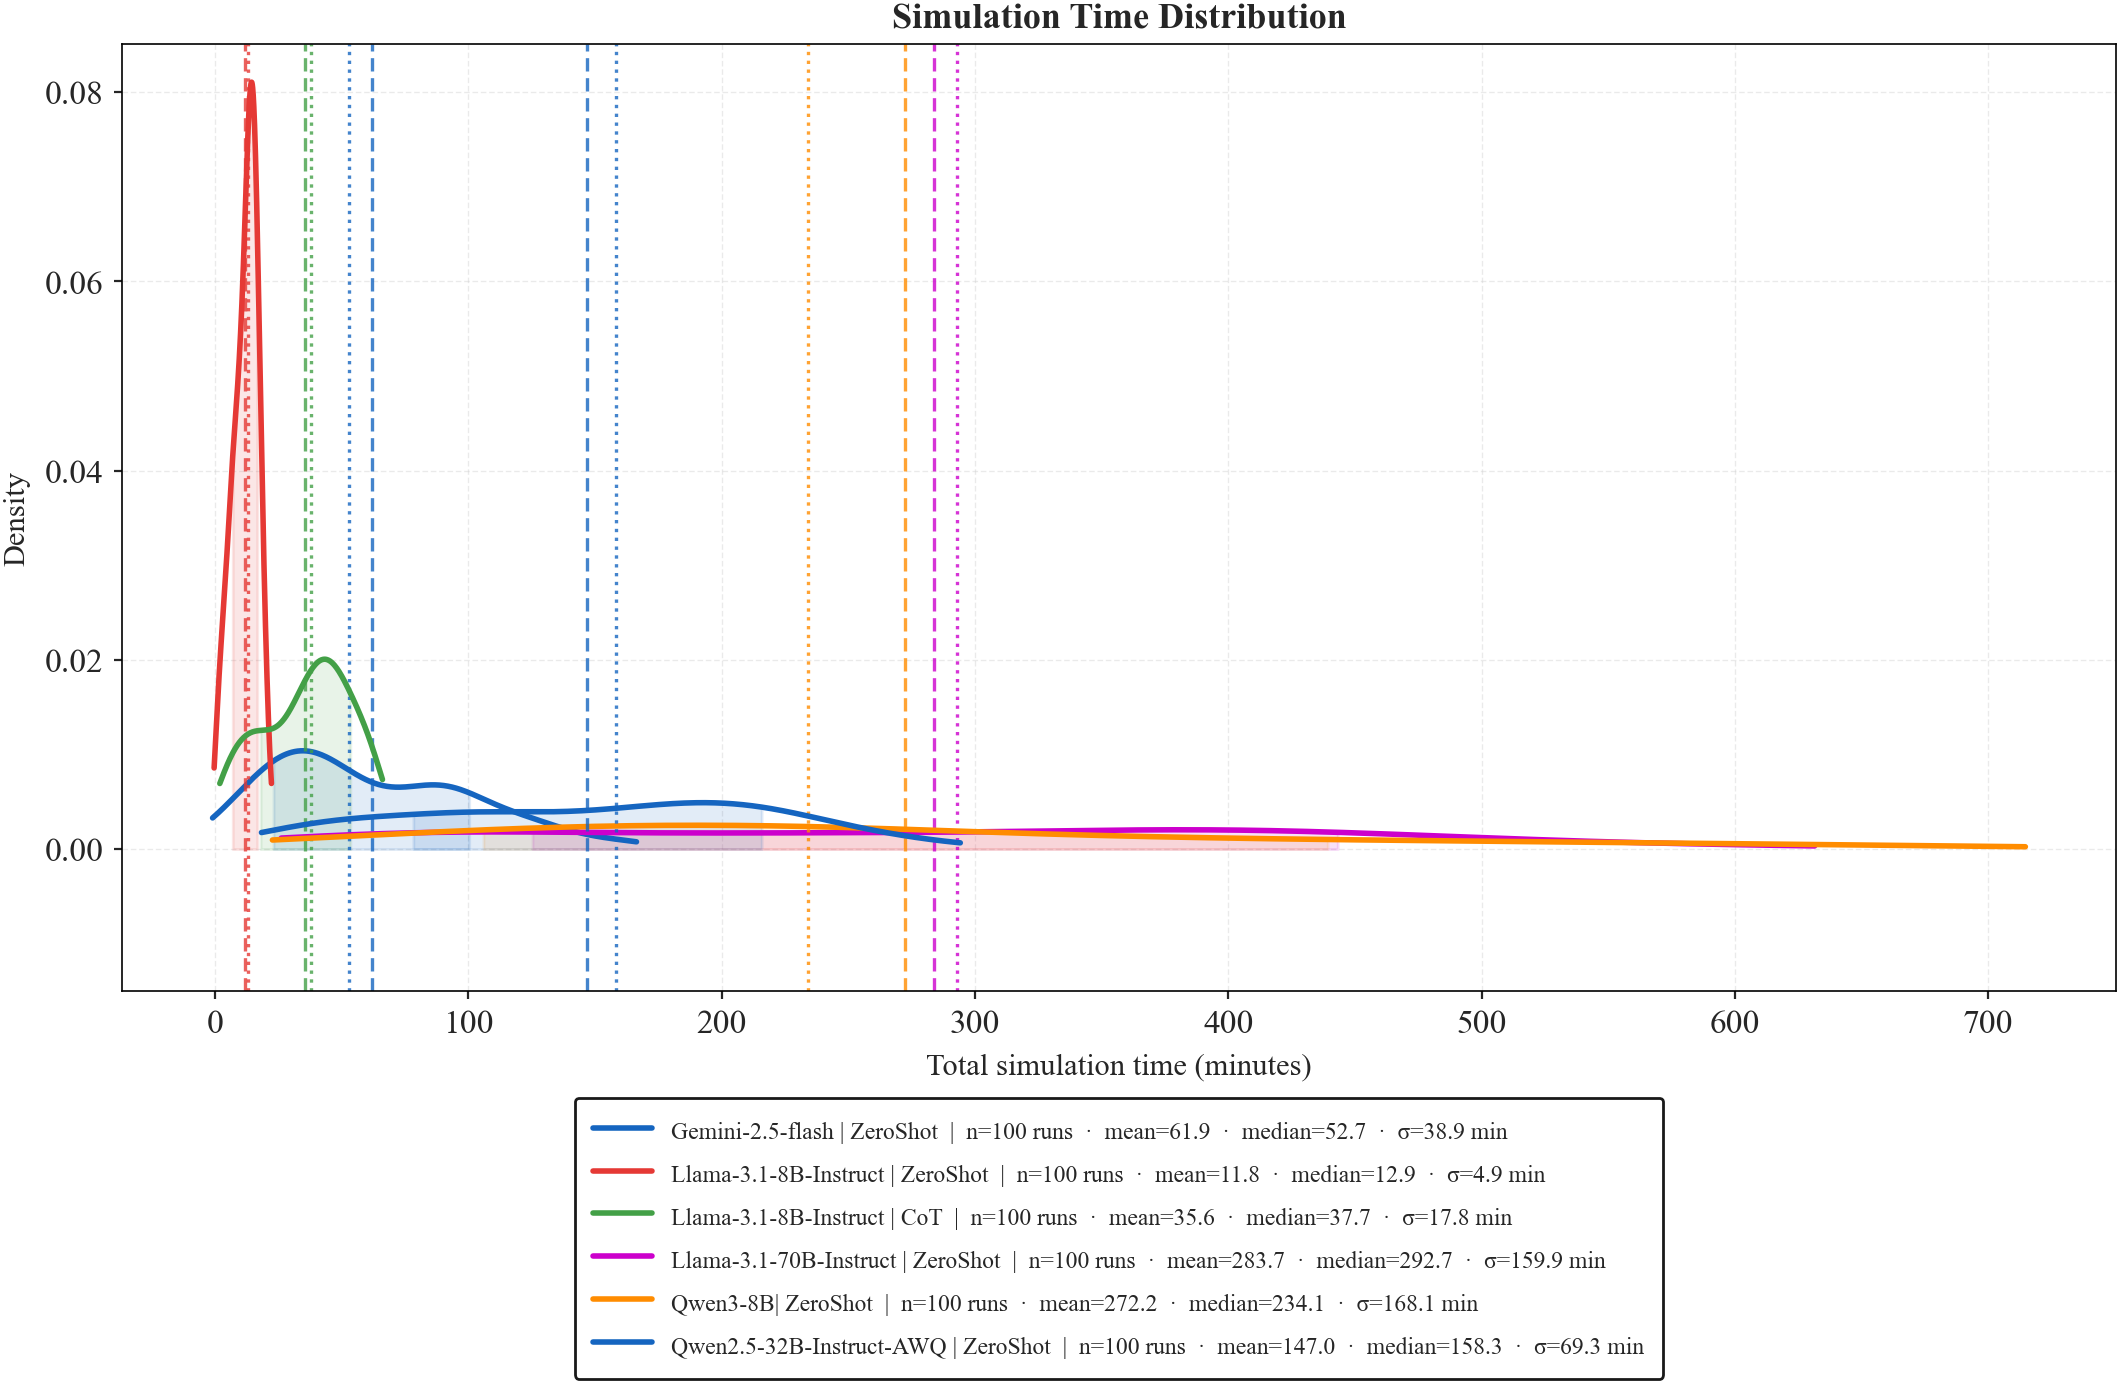

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
from pathlib import Path
from scipy.stats import gaussian_kde
import numpy as np

PROJECT_ROOT = Path.cwd().parent
CONFIGS = [
    {
        "label":   "Gemini-2.5-flash | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | CoT",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT-v1" / "CoT"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-70B-Instruct | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Qwen3-8B| ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Qwen2.5-32B-Instruct-AWQ | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
]

SIM_COLORS = ["#1565C0", "#E53935", "#43A047", "#CC00CC", "#FF8C00"]

fig, ax = plt.subplots()

for i, cfg in enumerate(CONFIGS):
    color   = SIM_COLORS[i % len(SIM_COLORS)]
    pattern = str(cfg["csv_dir"] / "model_state_v*.csv")
    files   = sorted(glob.glob(pattern))

    total_mins = []
    for path_str in files:
        df = pd.read_csv(path_str)
        if not df.empty and "elapsed_s" in df.columns:
            total_mins.append(df["elapsed_s"].sum() / 60)

    if len(total_mins) < 2:
        continue

    data       = np.array(total_mins)
    kde        = gaussian_kde(data, bw_method="scott")
    x          = np.linspace(data.min() - 1, data.max() + 1, 300)
    y          = kde(x)
    mean_val   = data.mean()
    median_val = np.median(data)
    std_val    = data.std()

    # KDE curve
    ax.plot(x, y, color=color, linewidth=2,
            label=f"{cfg['label']}  |  n=100 runs  ·  mean={mean_val:.1f}  ·  median={median_val:.1f}  ·  σ={std_val:.1f} min")

    # Shaded ±1 std band
    ax.fill_between(x, y,
                    where=(x >= mean_val - std_val) & (x <= mean_val + std_val),
                    color=color, alpha=0.12)

    # Mean & median verticals (no extra legend entries — color ties them to config)
    ax.axvline(mean_val,   color=color, linestyle="--", linewidth=1.2, alpha=0.8)
    ax.axvline(median_val, color=color, linestyle=":",  linewidth=1.2, alpha=0.8)

    # Rug plot offset by config index so they don't overlap
    rug_y = -0.003 * (i + 1)
    # ax.plot(data, np.full_like(data, rug_y), ".", color=color, alpha=0.7, markersize=8)

ax.set_xlabel("Total simulation time (minutes)", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.set_title("Simulation Time Distribution", fontsize=13, fontweight="bold")
ax.grid(axis='both', linestyle='--', alpha=0.4)
ax.set_ylim(bottom=-0.015)

# Legend below the plot so it doesn't crowd the curves
ax.legend(fontsize=8.5, framealpha=0.9, loc="upper center",
          bbox_to_anchor=(0.5, -0.1), ncol=1)

plt.tight_layout()
plt.show()

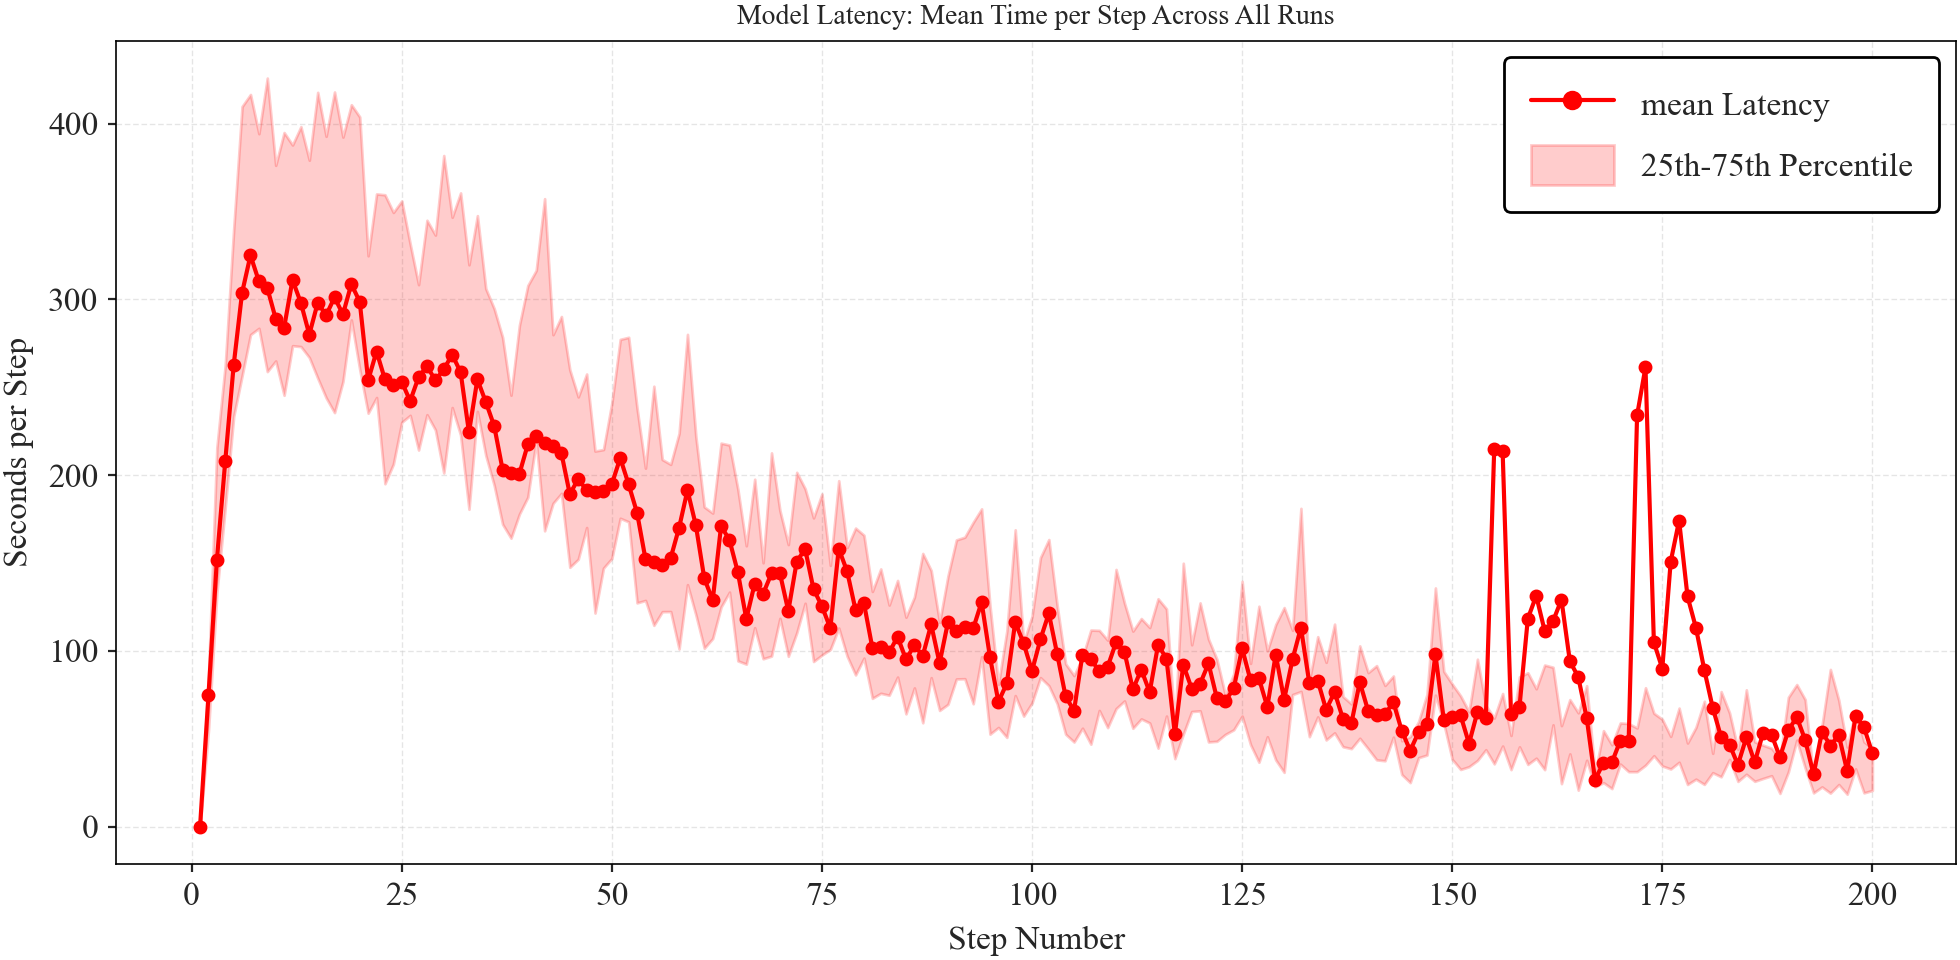

Analysis complete. Overall Mean step time: 164.94 seconds.


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import re
from pathlib import Path

# 1. Setup Paths
PROJECT_ROOT = Path.cwd().parent
PROVIDER ="llama3.1-8B-Instruct_ZeroShot"
PROMPT_TYPE = "ZeroShot"
PROVIDER = "qwen3-8B_ZeroShot"

PROMPT_TYPE = "ZeroShot"
_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / PROVIDER / PROMPT_TYPE
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

INPUT_PATTERN = str(_STRUCTURED / "ModelLogs" / "model_state_v*.csv")
files = glob.glob(INPUT_PATTERN)

all_data = []

if not files:
    print(f"No files found matching: {INPUT_PATTERN}")
else:
    # 2. Collect all steps from all runs
    for path_str in files:
        df = pd.read_csv(path_str)
        if not df.empty and "elapsed_s" in df.columns:
            # Ensure we have a 'step' column (fallback to index)
            if 'step' not in df.columns:
                df['step'] = df.index
            
            # We only need these two columns for this specific plot
            all_data.append(df[['step', 'elapsed_s']])

    # 3. Combine and Aggregate
    # Concatenate all runs into one big DataFrame
    combined_df = pd.concat(all_data)

    # Calculate mean, 25th, and 75th percentiles per step
    stats_per_step = combined_df.groupby('step')['elapsed_s'].agg(['mean', 'quantile', lambda x: x.quantile(0.75)]).reset_index()
    # Cleaning up column names from the quantile calls
    stats_per_step.columns = ['step', 'mean', 'q25', 'q75']

    # 4. Plotting
    plt.figure(figsize=(10, 5))

    # Plot the mean line
    plt.plot(stats_per_step['step'], stats_per_step['mean'], 
             color='red', marker='o', markersize=4, label='mean Latency')

    # Add shaded area for Interquartile Range (IQR) - shows the consistency
    plt.fill_between(stats_per_step['step'], stats_per_step['q25'], stats_per_step['q75'], 
                     color='red', alpha=0.2, label='25th-75th Percentile')

    # Overall mean (horizontal line for reference)
    overall_mean = combined_df['elapsed_s'].mean()
    # plt.axhline(y=overall_mean, color='red', linestyle='--', alpha=0.6, 
    #             label=f'Overall mean: {overall_mean:.2f}s')

    # Formatting
    plt.xlabel("Step Number")
    plt.ylabel("Seconds per Step")
    plt.title("Model Latency: Mean Time per Step Across All Runs")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    print(f"Analysis complete. Overall Mean step time: {overall_mean:.2f} seconds.")

Multi-model analysis complete. Plot saved as 'model_latency_comparison.png'.


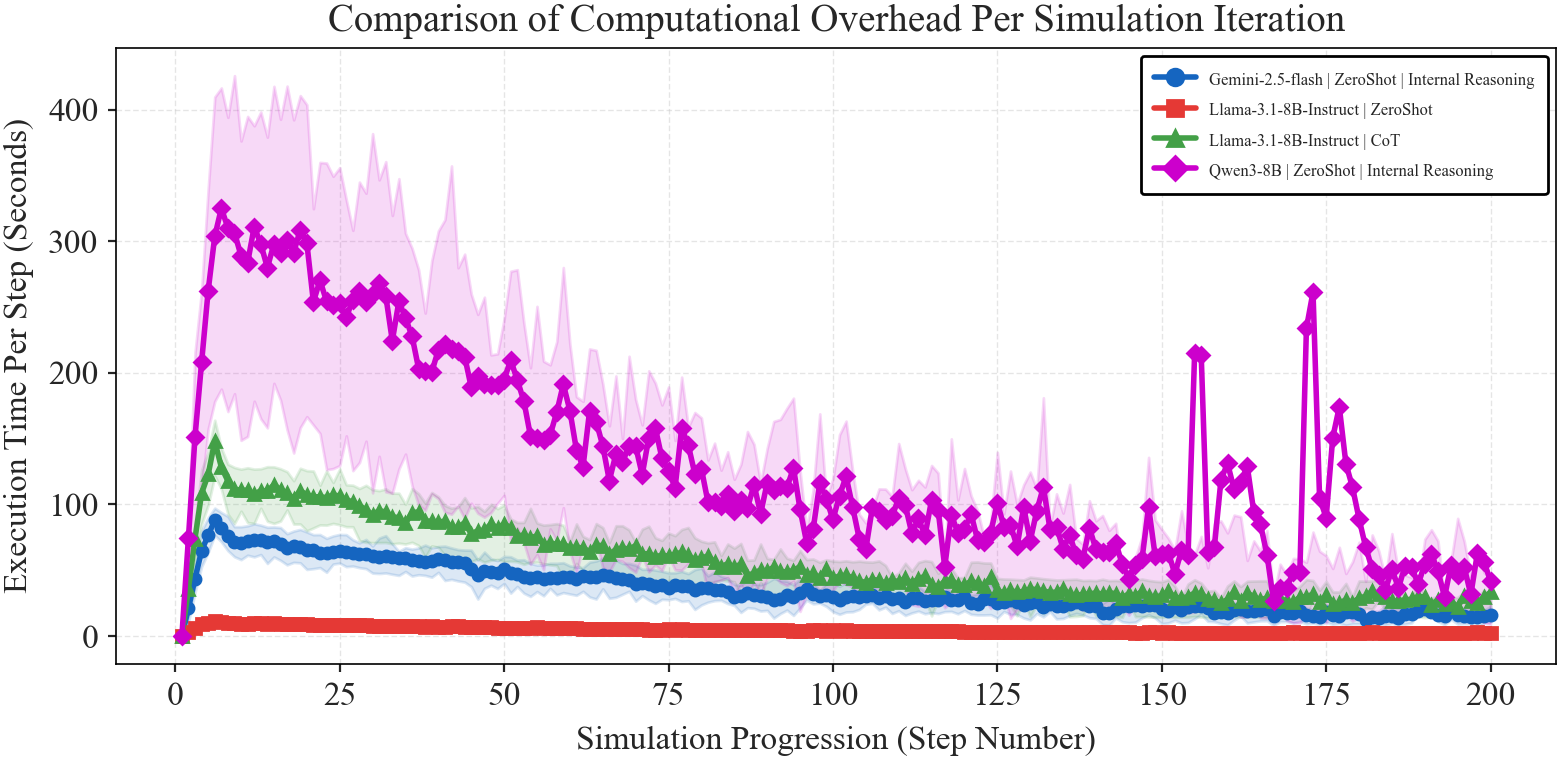

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
from pathlib import Path

# =============================================================================
# CONFIGURATION & STYLING
# =============================================================================
PROJECT_ROOT = Path.cwd().parent
PROVIDER = "vllm"
CONFIGS = [
    {
        "label":   "Gemini-2.5-flash | ZeroShot | Internal Reasoning",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | CoT",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    # {
    #     "label":   "Llama-3.1-70B-Instruct-AWQ-INT4 | ZeroShot",
    #     "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
    #                / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    # },
    {
        "label":   "Qwen3-8B | ZeroShot | Internal Reasoning",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    # {
    #     "label":   "Qwen2.5-32B-Instruct-AWQ-INT4 | ZeroShot",
    #     "csv_dir": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
    #                / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    # },
]


SIM_COLORS  = ["#1565C0", "#E53935", "#43A047", "#CC00CC", "#FF8C00", "#008080"]
SIM_MARKERS = ["o", "s", "^", "D", "v"]

# Set plot size without using plt.figure()
plt.rcParams["figure.figsize"] = (8, 4)

# =============================================================================
# DATA PROCESSING & PLOTTING
# =============================================================================
found_any_data = False

for i, cfg in enumerate(CONFIGS):
    label = cfg["label"]
    csv_dir = cfg["csv_dir"]
    color = SIM_COLORS[i % len(SIM_COLORS)]
    marker = SIM_MARKERS[i % len(SIM_MARKERS)]
    
    # Find files for this specific configuration
    input_pattern = str(csv_dir / "model_state_v*.csv")
    files = glob.glob(input_pattern)
    
    if not files:
        print(f"Warning: No files found for {label} in {csv_dir}")
        continue
    
    found_any_data = True
    all_runs_data = []

    # 1. Collect all steps from all runs for this model
    for path_str in files:
        try:
            df = pd.read_csv(path_str)
            if not df.empty and "elapsed_s" in df.columns:
                if 'step' not in df.columns:
                    df['step'] = df.index
                all_runs_data.append(df[['step', 'elapsed_s']])
        except Exception as e:
            print(f"Error reading {path_str}: {e}")

    if not all_runs_data:
        continue

    # 2. Combine and Aggregate stats for this model
    combined_df = pd.concat(all_runs_data)
    stats = combined_df.groupby('step')['elapsed_s'].agg(
        mean='mean',
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    ).reset_index()

    # 3. Add to Plot
    # Plot the mean line
    plt.plot(stats['step'], stats['mean'], 
             color=color, marker=marker, markersize=4, 
             linewidth=2, label=label)

    # Shaded area for Interquartile Range (IQR)
    plt.fill_between(stats['step'], stats['q25'], stats['q75'], 
                     color=color, alpha=0.15)

# =============================================================================
# FINAL FORMATTING
# =============================================================================
if found_any_data:
    plt.xlabel("Simulation Progression (Step Number)", fontsize=12)
    plt.ylabel("Execution Time Per Step (Seconds)", fontsize=12)
    plt.title("Comparison of Computational Overhead Per Simulation Iteration", fontsize=14)
    plt.legend(loc='best', fontsize=6, frameon=True, shadow=False)
    # plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    
    # Save the output
    plt.savefig("model_latency_comparison.png")
    print("Multi-model analysis complete. Plot saved as 'model_latency_comparison.png'.")
else:
    print("Analysis failed: No valid data found in any of the configured directories.")

In [7]:
"""
defection_order_analysis.py
===========================
Analyzes the sequence of pillar defections specifically for successful 
movements (Victory 2). Cross-references defection events with model states.
"""

from __future__ import annotations
import os
import csv
import glob
import re
from collections import defaultdict
from pathlib import Path

# --- FIX FOR OPENMP CONFLICT ---
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent
# PROVIDER = "vllm-32B_ZeroShot"
PROVIDER = "llama3.1-70B-Instruct-AWQ_CoT"
PROMPT_TYPE = "CoT"
_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / PROVIDER / PROMPT_TYPE
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

CONFIGS = [
    {
        "label":   "Gemini-2.5-flash | ZeroShot | Internal Reasoning",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | ZeroShot",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | CoT",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    # {
    #     "label":   "Llama-3.1-70B-Instruct-AWQ-INT4 | ZeroShot",
    #     "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
    #                / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    # },
    {
        "label":   "Qwen3-8B | ZeroShot | Internal Reasoning",
        "csv_dir": PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    },
    # {
    #     "label":   "Qwen2.5-32B-Instruct-AWQ-INT4 | ZeroShot",
    #     "csv_dir": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
    #                / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
    # },
]


SIM_COLORS  = ["#1565C0", "#E53935", "#43A047", "#CC00CC", "#FF8C00", "#008080"]
SIM_MARKERS = ["o", "s", "^", "D", "v"]


# Paths for input data
DEFECTION_GLOB = str(_STRUCTURED / "DefectionLogs" / "defection_events_v*.csv")
MODEL_STATE_DIR = _STRUCTURED / "ModelLogs"
total_found = 0

# Paths for output
OUTPUT_DIR = _STRUCTURED / "DefectionAnalysis"
OUTPUT_PLOT = OUTPUT_DIR / "successful_defection_order_breakdown_victory_2.png"
OUTPUT_CSV  = OUTPUT_DIR / "successful_defection_order_breakdown_victory_2.csv"

N_POSITIONS = 3
POSITION_LABELS = {1: "1st Defector", 2: "2nd Defector", 3: "3rd Defector"}

UNIQUE_PILLAR_TYPES = [
    "Educational System", "Trade Unions", "Religious Institutions",
    "Professional Associations", "Independent Media", "Business Community",
    "Civil Service", "Local Government", "Parliament", "Supreme Court", "State Media",
]

# ─────────────────────────────────────────────────────────────────────────────
# DATA LOADING & FILTERING
# ─────────────────────────────────────────────────────────────────────────────

def _get_v_num(p: str) -> int:
    m = re.search(r"_v(\d+)\.csv$", p, re.IGNORECASE)
    return int(m.group(1)) if m else 0

def load_successful_runs(glob_pattern: str) -> dict[str, list[dict]]:
    global total_found
    """Filters for runs where the final state is Victory 2."""
    files = sorted(glob.glob(glob_pattern), key=_get_v_num)
    if not files:
        raise FileNotFoundError(f"No files matched pattern: {glob_pattern}")

    successful_runs = {}
    # total_found = 0

    for fp in files:
        v_num = _get_v_num(fp)
        label = f"v{v_num}"
        total_found += 1
        
        # Check corresponding model state for Victory 2
        state_file = MODEL_STATE_DIR / f"model_state_v{v_num}.csv"
        if not state_file.exists():
            continue
            
        try:
            state_df = pd.read_csv(state_file)
            if state_df.empty or state_df["victory"].iloc[-1] != 2:
                continue # Only care about Victory 2
        except Exception:
            continue

        # Load defection sequence
        with open(fp, newline="", encoding="utf-8") as fh:
            rows = list(csv.DictReader(fh))
            rows.sort(key=lambda r: int(r.get("step", 0)))
            successful_runs[label] = rows

    print(f"Total files found: {total_found}")
    print(f"Successful runs (Victory 2) included: {len(successful_runs)}")
    return successful_runs

# ─────────────────────────────────────────────────────────────────────────────
# PROCESSING
# ─────────────────────────────────────────────────────────────────────────────

def process_stats(runs: dict[str, list[dict]]):
    total_n = len(runs)
    if total_n == 0:
        return None, 0

    # Count occurrences per position
    pos_counts = {pos: defaultdict(int) for pos in range(1, N_POSITIONS + 1)}
    for rows in runs.values():
        for pos in range(1, N_POSITIONS + 1):
            idx = pos - 1
            if idx < len(rows):
                inst = rows[idx].get("institution", "").strip()
                if inst:
                    pos_counts[pos][inst] += 1

    # Convert to percentages
    pct_results = {
        pos: {inst: round(cnt / total_n * 100, 1) for inst, cnt in inst_counts.items()}
        for pos, inst_counts in pos_counts.items()
    }
    return pct_results, total_n

# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZATION & EXPORT
# ─────────────────────────────────────────────────────────────────────────────

def run_analysis():
    # 1. Load and Process
    runs = load_successful_runs(DEFECTION_GLOB)
    pct, n = process_stats(runs)
    
    if not pct:
        print("No successful runs found to analyze.")
        return

    # 2. Save CSV
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        header = ["institution"] + [f"pos_{p}_pct" for p in range(1, N_POSITIONS + 1)]
        writer.writerow(header)
        for inst in UNIQUE_PILLAR_TYPES:
            row = [inst] + [pct[p].get(inst, 0.0) for p in range(1, N_POSITIONS + 1)]
            writer.writerow(row)

    # 3. Plotting
    plt.style.use("seaborn-v0_8-whitegrid")
    fig, ax = plt.subplots(figsize=(14, 7), facecolor="white")
    
    x = np.arange(len(UNIQUE_PILLAR_TYPES))
    width = 0.25
    colors = {1: "#2166ac", 2: "#f4a261", 3: "#e63946"}

    for i, pos in enumerate(range(1, N_POSITIONS + 1)):
        vals = [pct[pos].get(inst, 0.0) for inst in UNIQUE_PILLAR_TYPES]
        offset = (i - 1) * width
        rects = ax.bar(x + offset, vals, width, label=POSITION_LABELS[pos], color=colors[pos], alpha=0.85)
        
        # Add text labels on top of bars
        for rect in rects:
            height = rect.get_height()
            if height > 0:
                ax.annotate(f'{height:.0f}%',
                            xy=(rect.get_x() + rect.get_width() / 2, height),
                            xytext=(0, 3), textcoords="offset points",
                            ha='center', va='bottom', fontsize=7.5, fontweight="600", color="#222222",)

    ax.set_xticks(x)
    ax.set_ylim(0, 50)
    ax.set_xticklabels(UNIQUE_PILLAR_TYPES, rotation=35, ha="right")
    ax.set_ylabel("Probability of Defection (%)")
    ax.set_title(f"Defection Order in Successful Resistance (Victory 2, n={n}/{total_found} runs)", fontweight="bold")
    ax.legend(title="Defection Sequence")
    
    plt.tight_layout()
    plt.savefig(OUTPUT_PLOT, dpi=150)
    plt.show()
    print(f"Success! Plot saved to: {OUTPUT_PLOT}")

if __name__ == "__main__":
    run_analysis()

FileNotFoundError: No files matched pattern: c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\llama3.1-70B-Instruct-AWQ_CoT\CoT\stateful\vision-4\ModelLogging\structured\DefectionLogs\defection_events_v*.csv

In [ ]:

def load_pivot(cfg: dict) -> tuple[pd.DataFrame, int, int]:
    """
    Returns (pivot_df, n_victory2_runs, total_files).
    pivot_df: index=institution, columns=position (1..MAX_POSITIONS), values=% of runs.
    """
    files = sorted(glob.glob(cfg["def_glob"]), key=_v_num)
    total = len(files)
    model_log_dir = Path(cfg["csv_dir"])

    pos_counts: dict[int, dict[str, int]] = defaultdict(lambda: defaultdict(int))
    n_runs = 0

    for fp in files:
        v = _v_num(fp)
        state_file = model_log_dir / f"model_state_v{v}.csv"
        if not state_file.exists():
            continue
        try:
            sdf = pd.read_csv(state_file)
            if sdf.empty or sdf["victory"].iloc[-1] != 2:
                continue
        except Exception:
            continue

        with open(fp, newline="", encoding="utf-8") as fh:
            rows = sorted(csv.DictReader(fh), key=lambda r: int(r.get("step", 0)))

        n_runs += 1
        for pos_idx, row in enumerate(rows[:MAX_POSITIONS], start=1):
            inst = row.get("institution", "").strip()
            if inst:
                pos_counts[pos_idx][inst] += 1

    if n_runs == 0:
        return pd.DataFrame(), 0, total

    # Convert to % of runs
    records = []
    for pos in range(1, MAX_POSITIONS + 1):
        for inst in PILLAR_TYPES:
            records.append({
                "institution": inst,
                "position":    pos,
                "pct":         round(pos_counts[pos].get(inst, 0) / n_runs * 100, 1),
            })
    df = pd.DataFrame(records)
    pivot = df.pivot(index="institution", columns="position", values="pct")
    pivot = pivot.reindex(PILLAR_TYPES).fillna(0)
    # Drop all-zero position columns
    pivot = pivot.loc[:, (pivot > 0).any(axis=0)]
    return pivot, n_runs, total


  Institutional Defection Depth Analysis  (Victory 2)

[1/3] Inferring institution sizes …
  Auto-inferring institution sizes from data …
  Inferred totals: {'Religious Institutions': 1, 'Professional Associations': 1, 'Trade Unions': 1, 'Local Government': 1, 'Educational System': 1, 'State Media': 1, 'Independent Media': 1, 'Business Community': 1, 'Civil Service': 1, 'Parliament': 1, 'Supreme Court': 1}

[2/3] Computing defection depth per config …
  Gemini-2.5f … 76/107 Victory-2 runs
  Llama-8B-ZS … 42/101 Victory-2 runs
  Llama-8B-CoT … 53/101 Victory-2 runs
  Qwen-8B-ZS … 60/100 Victory-2 runs
  Qwen-32B-ZS … 56/100 Victory-2 runs

[3/3] Plotting …


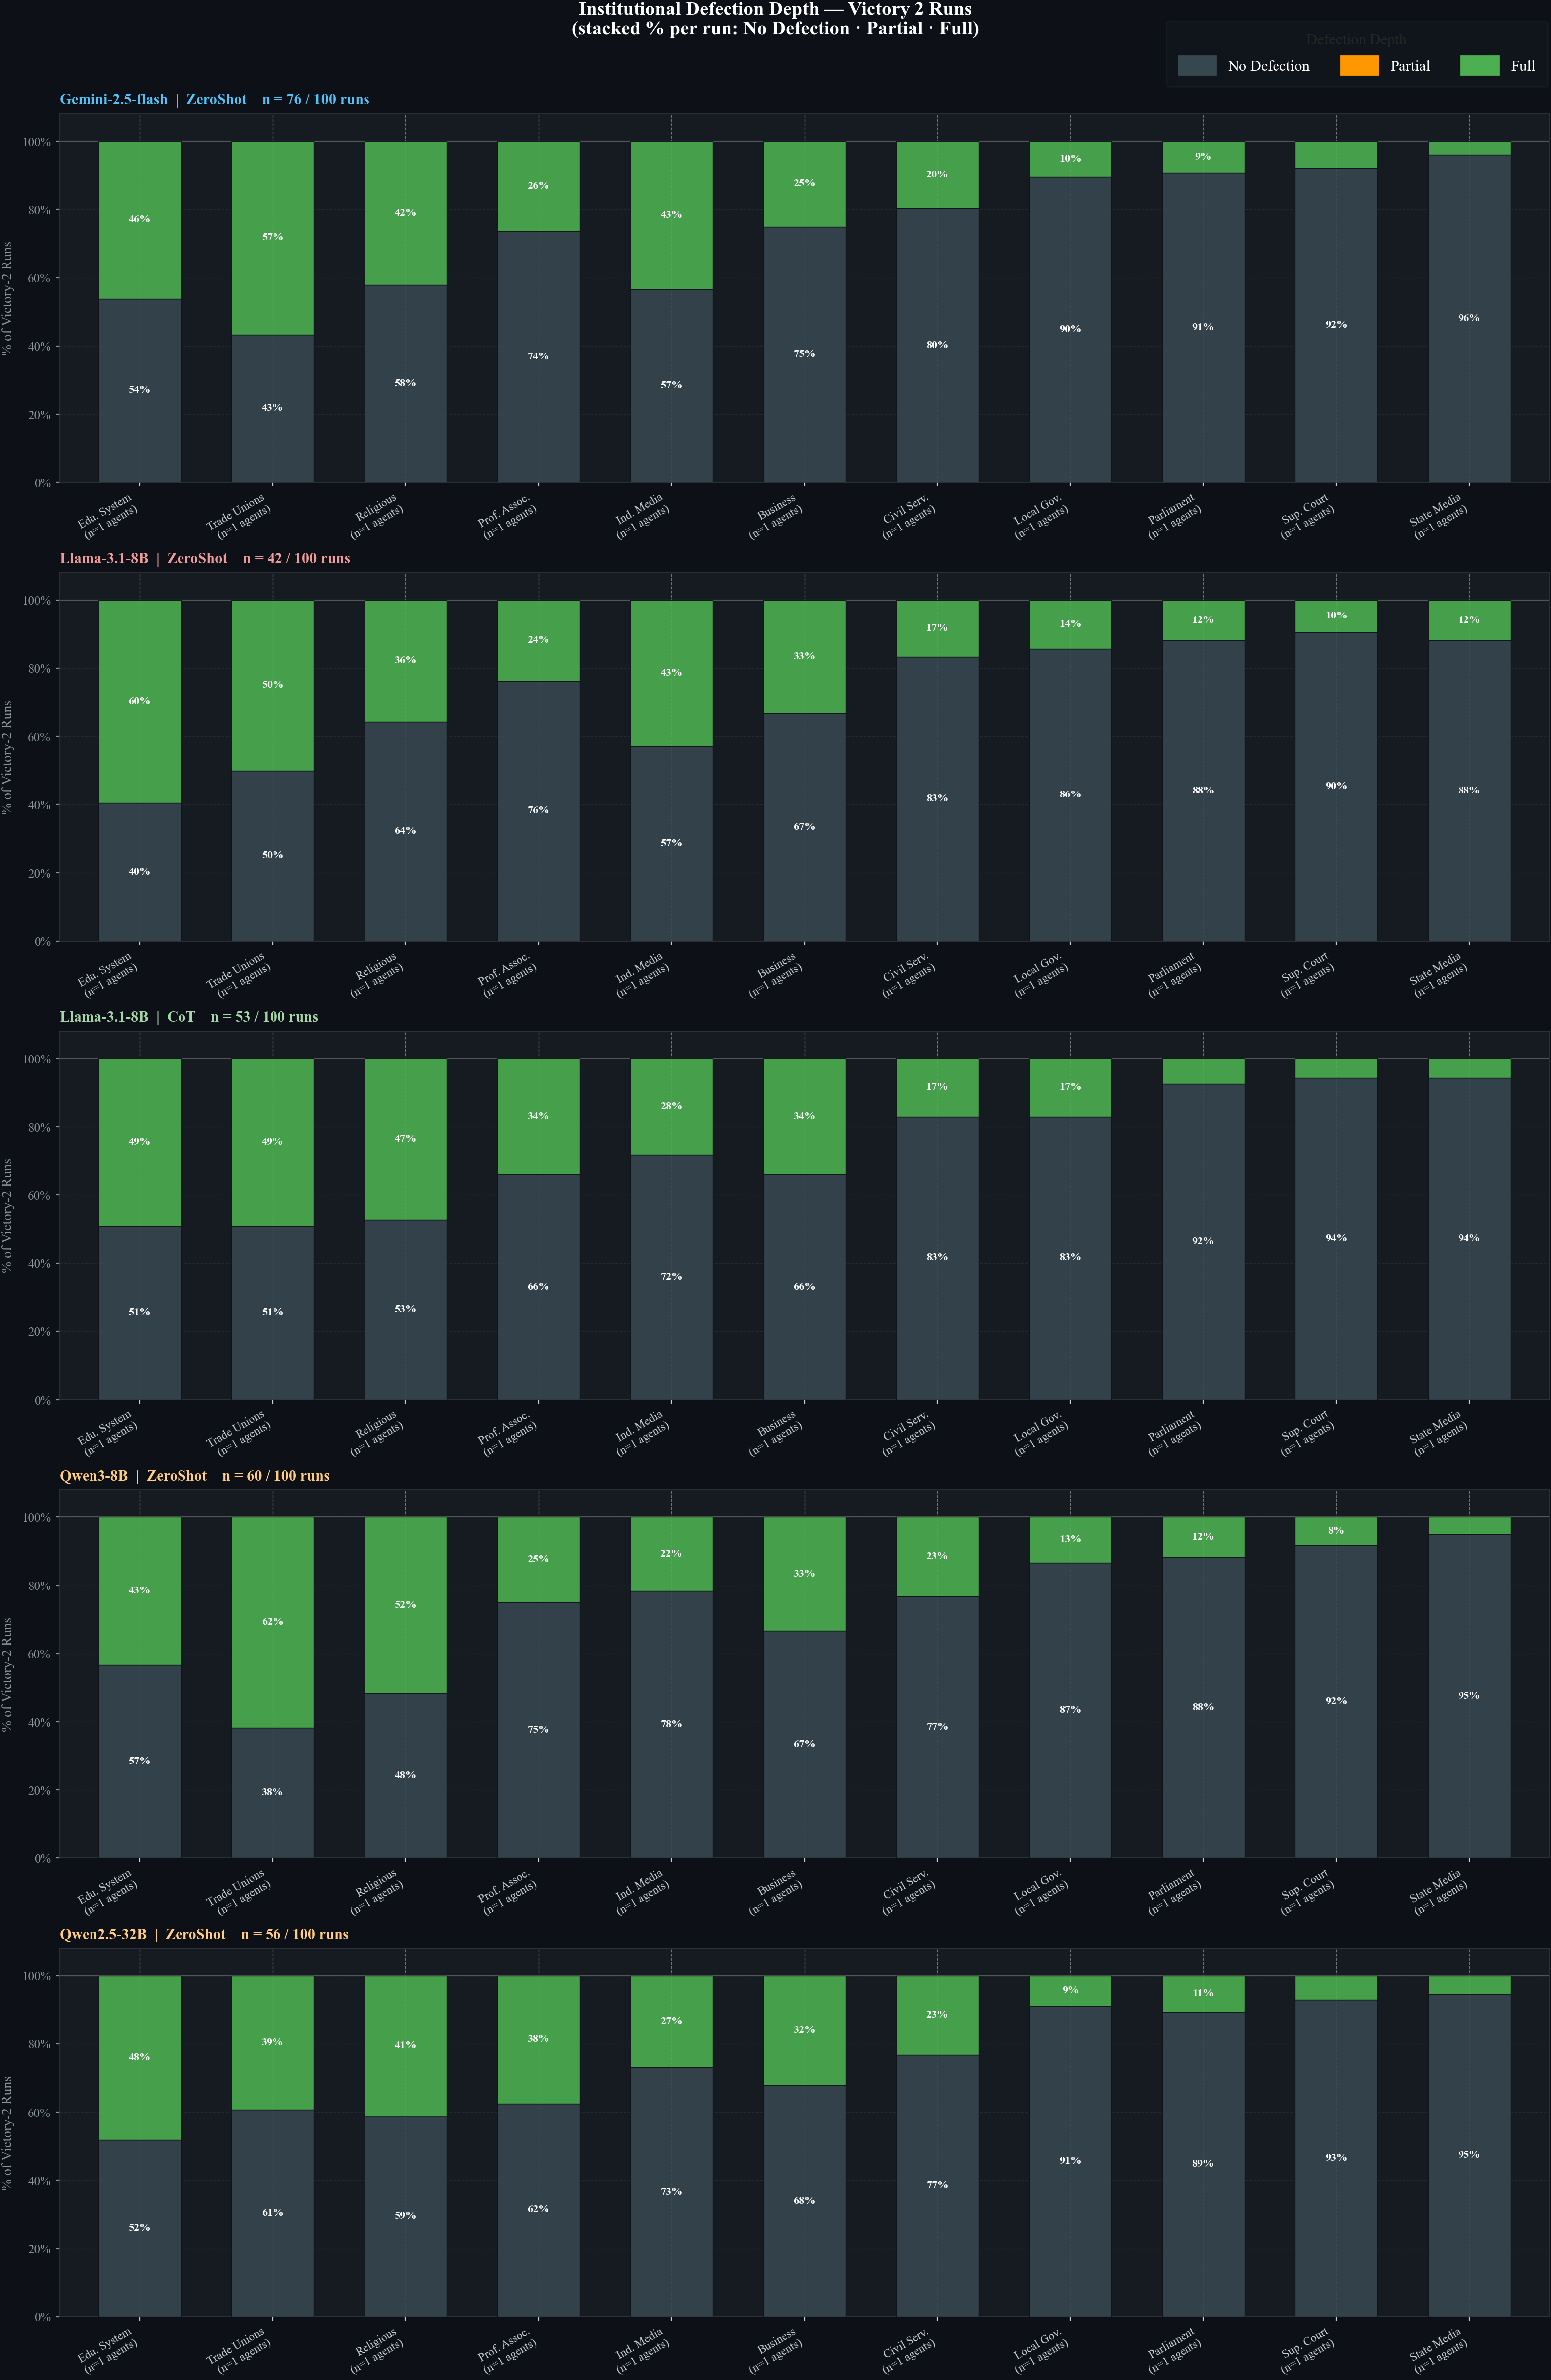


✓ Plot saved → defection_analysis_output\defection_depth_per_model.png

Exporting CSV summary …
✓ CSV  saved → defection_analysis_output\defection_depth_summary.csv

✓ Done. All outputs in: C:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\Analysis\defection_analysis_output


In [37]:
"""
institutional_defection_depth.py
==================================
For each Victory-2 run, checks every institution and classifies it as:
    • No Defection   – 0 agents defected
    • Partial        – some agents defected, but not all
    • Full           – every agent in that institution defected

Outputs:
    • One stacked horizontal bar chart per model  (% of runs in each category)
    • A summary CSV with raw numbers

How "total agents per institution" is resolved (in order of priority):
    1. INSTITUTION_TOTALS dict below  ← fill this in if you know the exact counts
    2. Auto-inferred from the data    ← takes the max defectors ever seen for
                                         that institution across all runs & configs
"""

from __future__ import annotations
import os, csv, glob, re
from collections import defaultdict
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent

CONFIGS = [
    {
        "label":    "Gemini-2.5-flash  |  ZeroShot",
        "short":    "Gemini-2.5f",
        "color":    "#4FC3F7",
        "csv_dir":  PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
        "def_glob": str(PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured"
                    / "DefectionLogs" / "defection_events_v*.csv"),
    },
    {
        "label":    "Llama-3.1-8B  |  ZeroShot",
        "short":    "Llama-8B-ZS",
        "color":    "#EF9A9A",
        "csv_dir":  PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
        "def_glob": str(PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured"
                    / "DefectionLogs" / "defection_events_v*.csv"),
    },
    {
        "label":    "Llama-3.1-8B  |  CoT",
        "short":    "Llama-8B-CoT",
        "color":    "#A5D6A7",
        "csv_dir":  PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
        "def_glob": str(PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured"
                    / "DefectionLogs" / "defection_events_v*.csv"),
    },
    {
        "label":    "Qwen3-8B  |  ZeroShot",
        "short":    "Qwen-8B-ZS",
        "color":    "#FFCC80",
        "csv_dir":  PROJECT_ROOT / "SimulationLogs" / "Qwen3-8B_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
        "def_glob": str(PROJECT_ROOT / "SimulationLogs" / "Qwen3-8B_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured"
                    / "DefectionLogs" / "defection_events_v*.csv"),
    },
    {
        "label":    "Qwen2.5-32B  |  ZeroShot",
        "short":    "Qwen-32B-ZS",
        "color":    "#FFCC80",
        "csv_dir":  PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
        "def_glob": str(PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "ModelLogging" / "structured"
                    / "DefectionLogs" / "defection_events_v*.csv"),
    },
]

PILLAR_TYPES = [
    "Educational System", "Trade Unions", "Religious Institutions",
    "Professional Associations", "Independent Media", "Business Community",
    "Civil Service", "Local Government", "Parliament", "Supreme Court", "State Media",
]

PILLAR_SHORT = {
    "Educational System":        "Edu. System",
    "Trade Unions":              "Trade Unions",
    "Religious Institutions":    "Religious",
    "Professional Associations": "Prof. Assoc.",
    "Independent Media":         "Ind. Media",
    "Business Community":        "Business",
    "Civil Service":             "Civil Serv.",
    "Local Government":          "Local Gov.",
    "Parliament":                "Parliament",
    "Supreme Court":             "Sup. Court",
    "State Media":               "State Media",
}

# ── Fill in exact agent counts per institution if you know them ──────────────
# Leave as {} to auto-infer from the data (max agents ever seen defecting)
INSTITUTION_TOTALS: dict[str, int] = {
    # "Educational System": 3,
    # "Trade Unions": 4,
    # ...
}

OUTPUT_ROOT = Path("defection_analysis_output")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Stacked bar colours
CAT_COLORS = {
    "No Defection": "#37474F",   # dark grey
    "Partial":      "#FF9800",   # amber
    "Full":         "#4CAF50",   # green
}
CATEGORIES = ["No Defection", "Partial", "Full"]

# ─────────────────────────────────────────────────────────────────────────────
# HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def _v_num(path: str) -> int:
    m = re.search(r"_v(\d+)\.csv$", path, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def _unique_agent_id(row: dict) -> str:
    """Build a unique agent key from whatever identifiers exist in the CSV."""
    candidates = ["agent_id", "rank", "agent", "id"]
    for c in candidates:
        v = row.get(c, "").strip()
        if v and v.lower() not in ("", "n/a", "nan"):
            return v
    # fallback: concatenate institution + step as a proxy
    return f"{row.get('institution','?')}_{row.get('step','?')}"


# ─────────────────────────────────────────────────────────────────────────────
# PASS 1  –  infer total agents per institution across ALL configs
# ─────────────────────────────────────────────────────────────────────────────

def infer_institution_totals(configs: list[dict]) -> dict[str, int]:
    """
    If INSTITUTION_TOTALS is not fully specified, scan every defection log
    (Victory-2 runs) and take the maximum unique-agent count seen per institution.
    This is a safe lower-bound for the true total.
    """
    if set(PILLAR_TYPES).issubset(set(INSTITUTION_TOTALS.keys())):
        print("  Using hardcoded INSTITUTION_TOTALS.")
        return dict(INSTITUTION_TOTALS)

    print("  Auto-inferring institution sizes from data …")
    max_seen: dict[str, int] = defaultdict(int)

    for cfg in configs:
        files = sorted(glob.glob(cfg["def_glob"]), key=_v_num)
        model_log_dir = Path(cfg["csv_dir"])

        for fp in files:
            v = _v_num(fp)
            state_file = model_log_dir / f"model_state_v{v}.csv"
            if not state_file.exists():
                continue
            try:
                sdf = pd.read_csv(state_file)
                if sdf.empty or sdf["victory"].iloc[-1] != 2:
                    continue
            except Exception:
                continue

            with open(fp, newline="", encoding="utf-8") as fh:
                rows = list(csv.DictReader(fh))

            per_inst: dict[str, set] = defaultdict(set)
            for row in rows:
                inst = row.get("institution", "").strip()
                if inst in PILLAR_TYPES:
                    per_inst[inst].add(_unique_agent_id(row))

            for inst, agents in per_inst.items():
                max_seen[inst] = max(max_seen[inst], len(agents))

    # Merge with any manually specified values
    totals = dict(max_seen)
    totals.update(INSTITUTION_TOTALS)   # manual entries win
    for p in PILLAR_TYPES:
        if p not in totals:
            totals[p] = 1   # safe fallback
            print(f"  WARNING: no agents ever seen for '{p}' – defaulting to 1")

    print("  Inferred totals:", {k: v for k, v in totals.items()})
    return totals


# ─────────────────────────────────────────────────────────────────────────────
# PASS 2  –  compute per-run defection depth for one config
# ─────────────────────────────────────────────────────────────────────────────

def compute_defection_depth(
    cfg: dict,
    inst_totals: dict[str, int],
) -> tuple[pd.DataFrame, int, int]:
    """
    Returns (depth_df, n_victory2_runs, total_files).

    depth_df has columns: institution | No Defection | Partial | Full
    Values = % of Victory-2 runs in that category.
    """
    files = sorted(glob.glob(cfg["def_glob"]), key=_v_num)
    total = len(files)
    model_log_dir = Path(cfg["csv_dir"])

    # category_counts[institution][category] = number of runs
    cat_counts: dict[str, dict[str, int]] = {
        inst: {cat: 0 for cat in CATEGORIES}
        for inst in PILLAR_TYPES
    }
    n_runs = 0

    for fp in files:
        v = _v_num(fp)
        state_file = model_log_dir / f"model_state_v{v}.csv"
        if not state_file.exists():
            continue
        try:
            sdf = pd.read_csv(state_file)
            if sdf.empty or sdf["victory"].iloc[-1] != 2:
                continue
        except Exception:
            continue

        with open(fp, newline="", encoding="utf-8") as fh:
            rows = list(csv.DictReader(fh))

        # Count unique defecting agents per institution for this run
        per_inst: dict[str, set] = defaultdict(set)
        for row in rows:
            inst = row.get("institution", "").strip()
            if inst in PILLAR_TYPES:
                per_inst[inst].add(_unique_agent_id(row))

        n_runs += 1

        for inst in PILLAR_TYPES:
            defected = len(per_inst.get(inst, set()))
            total_agents = inst_totals.get(inst, 1)
            if defected == 0:
                cat_counts[inst]["No Defection"] += 1
            elif defected >= total_agents:
                cat_counts[inst]["Full"] += 1
            else:
                cat_counts[inst]["Partial"] += 1

    if n_runs == 0:
        return pd.DataFrame(), 0, total

    # Convert to %
    records = []
    for inst in PILLAR_TYPES:
        row = {"institution": inst}
        for cat in CATEGORIES:
            row[cat] = round(cat_counts[inst][cat] / n_runs * 100, 1)
        records.append(row)

    df = pd.DataFrame(records).set_index("institution")
    return df, n_runs, total


# ─────────────────────────────────────────────────────────────────────────────
# VISUALISATION  –  one row per model, stacked horizontal bars per pillar
# ─────────────────────────────────────────────────────────────────────────────

def plot_defection_depth(
    all_data: list[tuple[dict, pd.DataFrame, int, int]],
    inst_totals: dict[str, int],
):
    n_models = len(all_data)
    fig_w    = 16
    row_h    = 4.6

    fig, axes = plt.subplots(
        n_models, 1,
        figsize=(fig_w, row_h * n_models + 1.0),
        facecolor="#0d1117",
    )
    if n_models == 1:
        axes = [axes]

    x        = np.arange(len(PILLAR_TYPES))
    x_labels = [PILLAR_SHORT[p] for p in PILLAR_TYPES]

    for ax, (cfg, df, n_runs, total) in zip(axes, all_data):
        ax.set_facecolor("#161b22")
        for spine in ax.spines.values():
            spine.set_color("#30363d")

        if df.empty:
            ax.text(0.5, 0.5, "No Victory-2 data found",
                    ha="center", va="center", color="#8b949e",
                    fontsize=12, transform=ax.transAxes)
            _style(ax, cfg, n_runs, total, x, x_labels, inst_totals)
            continue

        bar_w   = 0.62
        bottoms = np.zeros(len(PILLAR_TYPES))

        for cat in CATEGORIES:
            vals = np.array([df.loc[inst, cat] for inst in PILLAR_TYPES])
            bars = ax.bar(
                x, vals, bar_w,
                bottom=bottoms,
                color=CAT_COLORS[cat],
                alpha=0.90,
                edgecolor="#0d1117",
                linewidth=0.5,
                label=cat,
                zorder=3,
            )
            # Label segments that are wide enough to read
            for bar, v, bot in zip(bars, vals, bottoms):
                if v >= 8:
                    ax.text(
                        bar.get_x() + bar.get_width() / 2,
                        bot + v / 2,
                        f"{v:.0f}%",
                        ha="center", va="center",
                        fontsize=8, color="white", fontweight="bold",
                        zorder=5,
                    )
            bottoms += vals

        _style(ax, cfg, n_runs, total, x, x_labels, inst_totals)

    # ── Shared legend ─────────────────────────────────────────────────────────
    legend_patches = [
        mpatches.Patch(color=CAT_COLORS[c], label=c) for c in CATEGORIES
    ]
    fig.legend(
        handles=legend_patches,
        loc="upper right",
        bbox_to_anchor=(0.99, 1.00),
        framealpha=0.2,
        facecolor="#21262d",
        edgecolor="#30363d",
        labelcolor="white",
        fontsize=11,
        title="Defection Depth",
        title_fontsize=11,
        ncol=3,
    )

    fig.suptitle(
        "Institutional Defection Depth — Victory 2 Runs\n"
        "(stacked % per run: No Defection · Partial · Full)",
        color="white", fontsize=14, fontweight="bold", y=1.005,
    )

    plt.tight_layout(pad=2.0, h_pad=0.8)
    out = OUTPUT_ROOT / "defection_depth_per_model.png"
    plt.savefig(out, dpi=160, bbox_inches="tight", facecolor="#0d1117")
    plt.show()
    print(f"\n✓ Plot saved → {out}")


def _style(ax, cfg, n_runs, total, x, x_labels, inst_totals):
    ax.set_xlim(-0.6, len(x) - 0.4)
    ax.set_ylim(0, 108)
    ax.set_xticks(x)

    # Add (n=X) under each pillar label so viewer knows institution size
    labels_with_n = [
        f"{PILLAR_SHORT[p]}\n(n={inst_totals.get(p,'?')} agents)"
        for p in PILLAR_TYPES
    ]
    ax.set_xticklabels(labels_with_n, rotation=30, ha="right",
                       fontsize=8.5, color="#c9d1d9")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.set_ylabel("% of Victory-2 Runs", color="#8b949e", fontsize=10)
    ax.yaxis.label.set_color("#8b949e")
    ax.tick_params(axis="y", colors="#8b949e", labelsize=9)
    ax.tick_params(axis="x", colors="#c9d1d9")
    ax.grid(axis="y", color="#30363d", linewidth=0.5, linestyle="--", zorder=0)
    ax.axhline(100, color="#555", linewidth=0.8, linestyle="-", zorder=1)
    ax.set_axisbelow(True)

    ax.set_title(
        f"{cfg['label']}    n = {n_runs} / {100} runs",
        loc="left", color=cfg["color"],
        fontsize=11, fontweight="bold", pad=7,
    )


# ─────────────────────────────────────────────────────────────────────────────
# CSV EXPORT
# ─────────────────────────────────────────────────────────────────────────────

def export_csv(all_data: list[tuple[dict, pd.DataFrame, int, int]]):
    rows = []
    for cfg, df, n_runs, total in all_data:
        if df.empty:
            continue
        for inst in PILLAR_TYPES:
            rows.append({
                "config":        cfg["short"],
                "institution":   inst,
                "n_runs":        n_runs,
                "total_files":   total,
                "no_defection%": df.loc[inst, "No Defection"],
                "partial%":      df.loc[inst, "Partial"],
                "full%":         df.loc[inst, "Full"],
            })

    out_df  = pd.DataFrame(rows)
    out_csv = OUTPUT_ROOT / "defection_depth_summary.csv"
    out_df.to_csv(out_csv, index=False)
    print(f"✓ CSV  saved → {out_csv}")
    return out_df


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────

def main():
    print("=" * 62)
    print("  Institutional Defection Depth Analysis  (Victory 2)")
    print("=" * 62)

    print("\n[1/3] Inferring institution sizes …")
    inst_totals = infer_institution_totals(CONFIGS)

    print("\n[2/3] Computing defection depth per config …")
    all_data = []
    for cfg in CONFIGS:
        print(f"  {cfg['short']} …", end=" ", flush=True)
        df, n, total = compute_defection_depth(cfg, inst_totals)
        all_data.append((cfg, df, n, total))
        print(f"{n}/{total} Victory-2 runs")

    print("\n[3/3] Plotting …")
    plot_defection_depth(all_data, inst_totals)

    print("\nExporting CSV summary …")
    export_csv(all_data)

    print("\n✓ Done. All outputs in:", OUTPUT_ROOT.resolve())
    print("=" * 62)


if __name__ == "__main__":
    main()

### **Defection Order in Successful Simulations**

In [6]:
# """
# defection_order_analysis.py
# ===========================
# Analyzes the sequence of pillar defections specifically for successful 
# movements (Victory 2). Cross-references defection events with model states.
# """

# from __future__ import annotations
# import os
# import csv
# import glob
# import re
# from collections import defaultdict
# from pathlib import Path

# # --- FIX FOR OPENMP CONFLICT ---
# os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.ticker as ticker

# # ─────────────────────────────────────────────────────────────────────────────
# # CONFIGURATION
# # ─────────────────────────────────────────────────────────────────────────────

# PROJECT_ROOT = Path.cwd().parent
# PROVIDER = "qwen3-8B_ZeroShot"
# # PROVIDER = "llama3.1-8B-Instruct_CoT"
# # PROVIDER = "gemini-2.5-flash"
# PROMPT_TYPE = "ZeroShot"
# _STRUCTURED = (
#     PROJECT_ROOT
#     / "SimulationLogs" / PROVIDER / PROMPT_TYPE
#     / "stateful"       / "vision-4"
#     / "ModelLogging"   / "structured"
# )


# CONFIGS = [
#     {
#         "label":   "Gemini-2.5-flash | ZeroShot",
#         "csv_dir": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
#                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     },
#     {
#         "label":   "Llama-3.1-8B-Instruct | ZeroShot",
#         "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
#                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     },
#     {
#         "label":   "Llama-3.1-8B-Instruct | CoT",
#         "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
#                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     },
#     {
#         "label":   "Llama-3.1-70B-Instruct | CoT",
#         "csv_dir": PROJECT_ROOT / "SimulationLogs" / "llama3.1-70B-Instruct-AWQ_CoT" / "CoT"
#                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     },
#     {
#         "label":   "Qwen2.5-32B-Instruct-AWQ | ZeroShot",
#         "csv_dir": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
#                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     },
#     {
#         "label":   "Qwen3-8B | ZeroShot",
#         "csv_dir": PROJECT_ROOT / "SimulationLogs" / "Qwen3-8B_ZeroShot" / "ZeroShot"
#                    / "stateful" / "vision-4" / "ModelLogging" / "structured" / "ModelLogs",
#     },
# ]



# SIM_COLORS  = ["#1565C0", "#E53935", "#43A047", "#CC00CC", "#FF8C00"]
# SIM_MARKERS = ["o", "s", "^", "D", "v"]

# # Paths for input data
# DEFECTION_GLOB = str(_STRUCTURED / "DefectionLogs" / "defection_events_v*.csv")
# MODEL_STATE_DIR = _STRUCTURED / "ModelLogs"
# total_found = 0

# # Paths for output
# OUTPUT_DIR = _STRUCTURED / "DefectionAnalysis"
# OUTPUT_PLOT = OUTPUT_DIR / "successful_defection_order_breakdown_victory_2.png"
# OUTPUT_CSV  = OUTPUT_DIR / "successful_defection_order_breakdown_victory_2.csv"

# N_POSITIONS = 3
# POSITION_LABELS = {1: "1st Defector", 2: "2nd Defector", 3: "3rd Defector"}

# UNIQUE_PILLAR_TYPES = [
#     "Educational System", "Trade Unions", "Religious Institutions",
#     "Professional Associations", "Independent Media", "Business Community",
#     "Civil Service", "Local Government", "Parliament", "Supreme Court", "State Media",
# ]

# # ─────────────────────────────────────────────────────────────────────────────
# # DATA LOADING & FILTERING
# # ─────────────────────────────────────────────────────────────────────────────

# def _get_v_num(p: str) -> int:
#     m = re.search(r"_v(\d+)\.csv$", p, re.IGNORECASE)
#     return int(m.group(1)) if m else 0

# def load_successful_runs(glob_pattern: str) -> dict[str, list[dict]]:
#     global total_found
#     """Filters for runs where the final state is Victory 2."""
#     files = sorted(glob.glob(glob_pattern), key=_get_v_num)
#     if not files:
#         raise FileNotFoundError(f"No files matched pattern: {glob_pattern}")

#     successful_runs = {}
#     # total_found = 0

#     for fp in files:
#         v_num = _get_v_num(fp)
#         label = f"v{v_num}"
#         total_found += 1
        
#         # Check corresponding model state for Victory 2
#         state_file = MODEL_STATE_DIR / f"model_state_v{v_num}.csv"
#         if not state_file.exists():
#             continue
            
#         try:
#             state_df = pd.read_csv(state_file)
#             if state_df.empty or state_df["victory"].iloc[-1] != 2:
#                 continue # Only care about Victory 2
#         except Exception:
#             continue

#         # Load defection sequence
#         with open(fp, newline="", encoding="utf-8") as fh:
#             rows = list(csv.DictReader(fh))
#             rows.sort(key=lambda r: int(r.get("step", 0)))
#             successful_runs[label] = rows

#     print(f"Total files found: {total_found}")
#     print(f"Successful runs (Victory 2) included: {len(successful_runs)}")
#     return successful_runs

# # ─────────────────────────────────────────────────────────────────────────────
# # PROCESSING
# # ─────────────────────────────────────────────────────────────────────────────

# def process_stats(runs: dict[str, list[dict]]):
#     total_n = len(runs)
#     if total_n == 0:
#         return None, 0

#     # Count occurrences per position
#     pos_counts = {pos: defaultdict(int) for pos in range(1, N_POSITIONS + 1)}
#     for rows in runs.values():
#         for pos in range(1, N_POSITIONS + 1):
#             idx = pos - 1
#             if idx < len(rows):
#                 inst = rows[idx].get("institution", "").strip()
#                 if inst:
#                     pos_counts[pos][inst] += 1

#     # Convert to percentages
#     pct_results = {
#         pos: {inst: round(cnt / total_n * 100, 1) for inst, cnt in inst_counts.items()}
#         for pos, inst_counts in pos_counts.items()
#     }
#     return pct_results, total_n

# # ─────────────────────────────────────────────────────────────────────────────
# # VISUALIZATION & EXPORT
# # ─────────────────────────────────────────────────────────────────────────────

# def run_analysis():
#     # 1. Load and Process
#     runs = load_successful_runs(DEFECTION_GLOB)
#     pct, n = process_stats(runs)
    
#     if not pct:
#         print("No successful runs found to analyze.")
#         return

#     # 2. Save CSV
#     OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
#     with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
#         writer = csv.writer(f)
#         header = ["institution"] + [f"pos_{p}_pct" for p in range(1, N_POSITIONS + 1)]
#         writer.writerow(header)
#         for inst in UNIQUE_PILLAR_TYPES:
#             row = [inst] + [pct[p].get(inst, 0.0) for p in range(1, N_POSITIONS + 1)]
#             writer.writerow(row)

#     # 3. Plotting
#     plt.style.use("seaborn-v0_8-whitegrid")
#     fig, ax = plt.subplots(figsize=(14, 7), facecolor="white")
    
#     x = np.arange(len(UNIQUE_PILLAR_TYPES))
#     width = 0.25
#     colors = {1: "#2166ac", 2: "#f4a261", 3: "#e63946"}

#     for i, pos in enumerate(range(1, N_POSITIONS + 1)):
#         vals = [pct[pos].get(inst, 0.0) for inst in UNIQUE_PILLAR_TYPES]
#         offset = (i - 1) * width
#         rects = ax.bar(x + offset, vals, width, label=POSITION_LABELS[pos], color=colors[pos], alpha=0.85)
        
#         # Add text labels on top of bars
#         for rect in rects:
#             height = rect.get_height()
#             if height > 0:
#                 ax.annotate(f'{height:.0f}%',
#                             xy=(rect.get_x() + rect.get_width() / 2, height),
#                             xytext=(0, 3), textcoords="offset points",
#                             ha='center', va='bottom', fontsize=7.5, fontweight="600", color="#222222",)

#     ax.set_xticks(x)
#     ax.set_ylim(0, 50)
#     ax.set_xticklabels(UNIQUE_PILLAR_TYPES, rotation=35, ha="right")
#     ax.set_ylabel("Probability of Defection (%)")
#     ax.set_title(f"Defection Order in Successful Resistance (Victory 2, n={n}/{100} runs)", fontweight="bold")
#     ax.legend(title="Defection Sequence")
    
#     plt.tight_layout()
#     plt.savefig(OUTPUT_PLOT, dpi=150)
#     plt.show()
#     print(f"Success! Plot saved to: {OUTPUT_PLOT}")

# if __name__ == "__main__":
#     run_analysis()

Total files found:                    107
Successful runs (Victory 2) included: 76


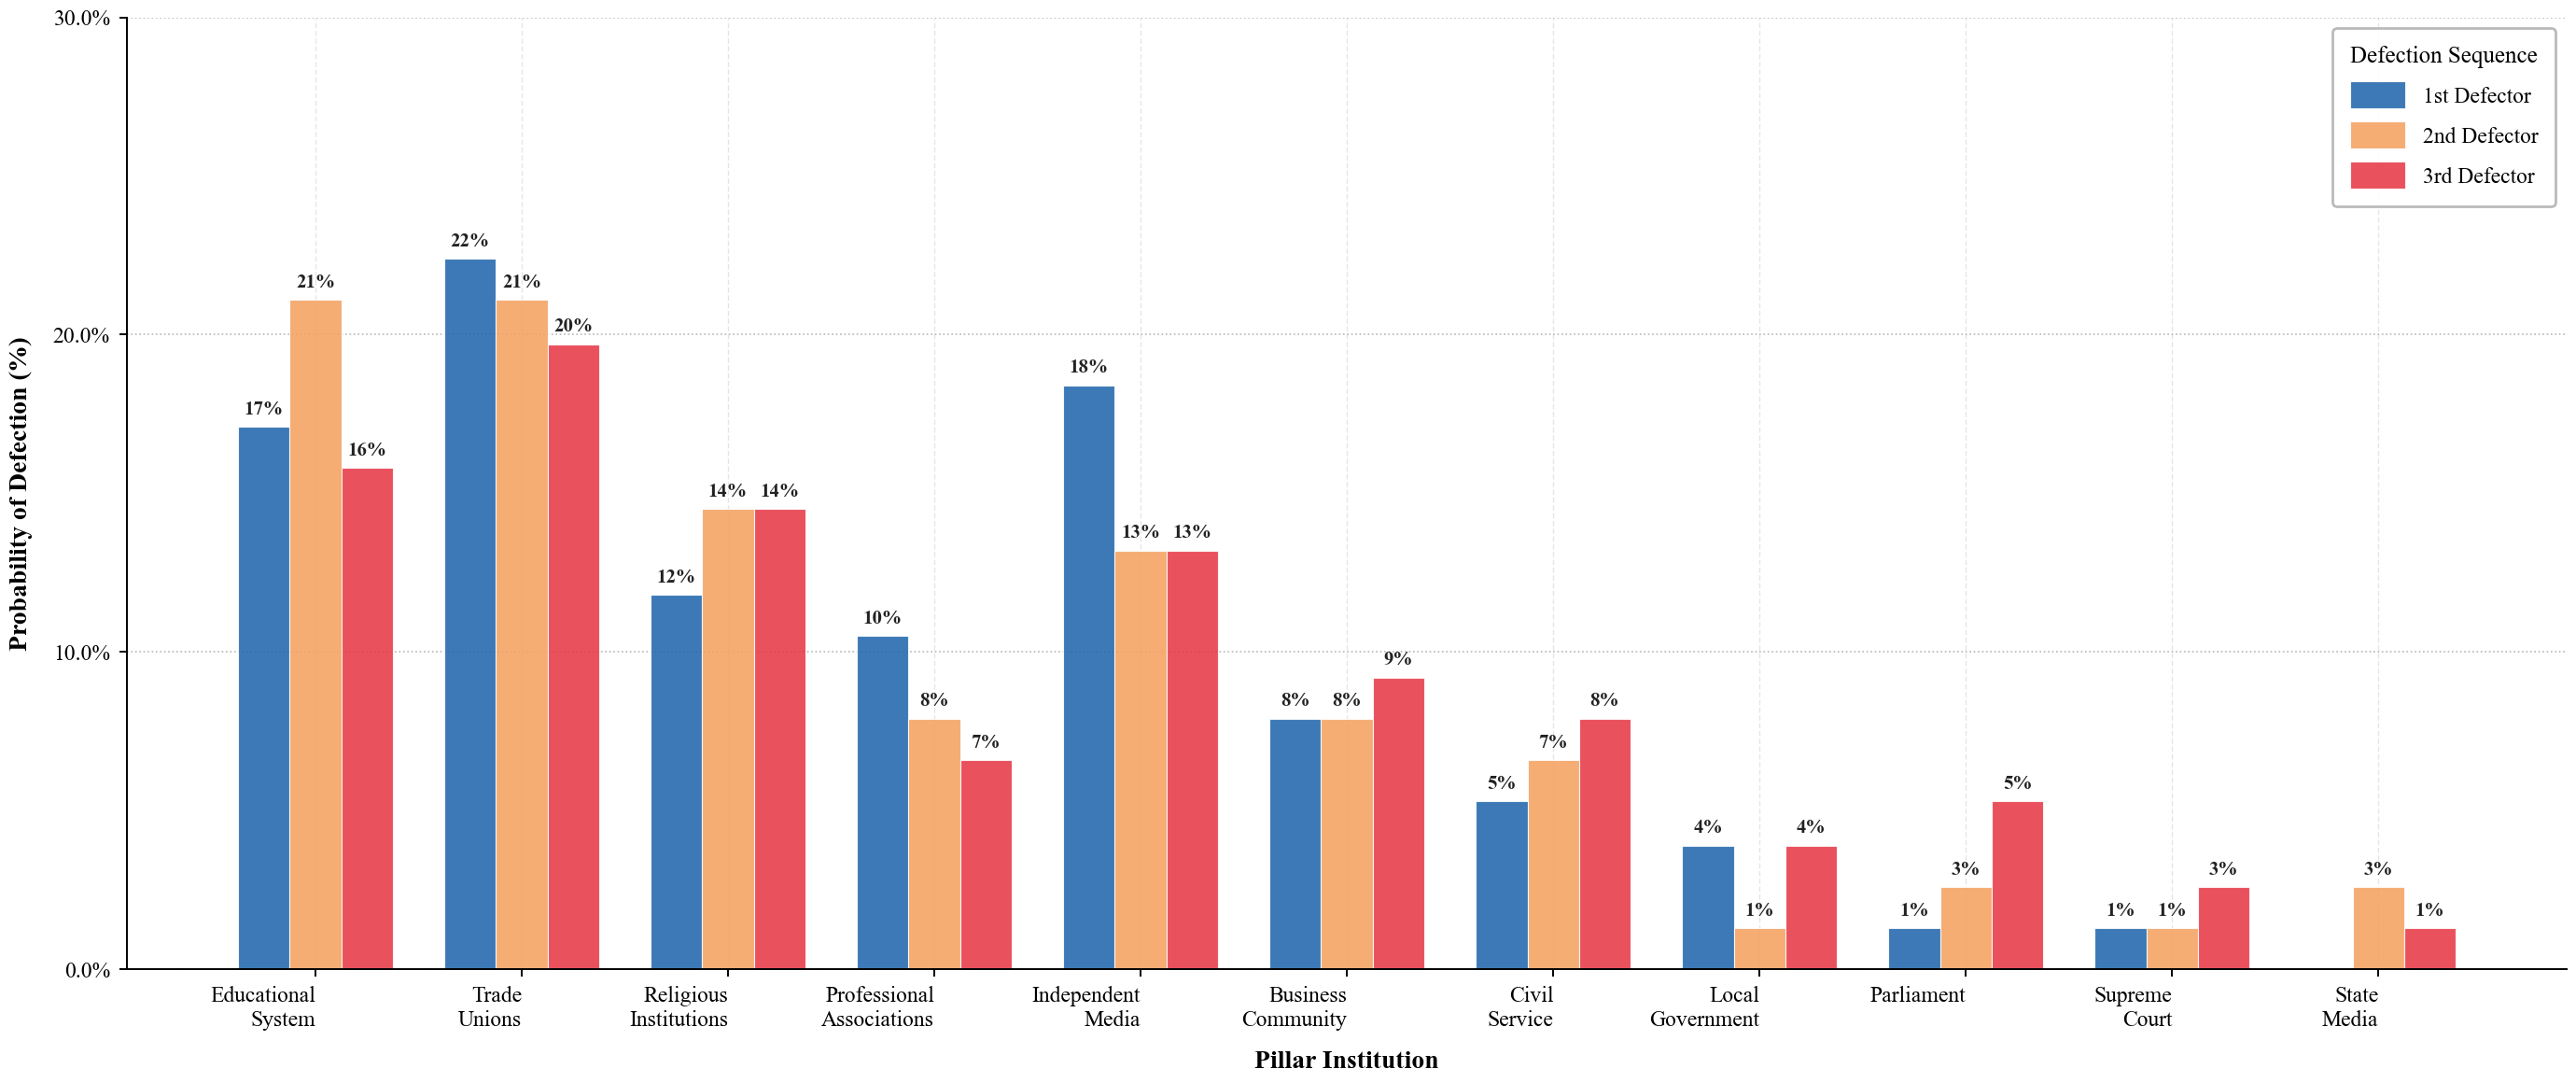


Saved:
  PNG → c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini-2.5-flash\ZeroShot\stateful\vision-4\ModelLogging\structured\DefectionAnalysis\successful_defection_order_breakdown_victory_2.png
  PDF → c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini-2.5-flash\ZeroShot\stateful\vision-4\ModelLogging\structured\DefectionAnalysis\successful_defection_order_breakdown_victory_2.pdf
  CSV → c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini-2.5-flash\ZeroShot\stateful\vision-4\ModelLogging\structured\DefectionAnalysis\successful_defection_order_breakdown_victory_2.csv


In [12]:
"""
defection_order_analysis.py
===========================
Analyzes the sequence of pillar defections specifically for successful
movements (Victory 2). Cross-references defection events with model states.

Formatting: publication-ready (Times New Roman, bold axes, 300 DPI).
"""

from __future__ import annotations
import os
import csv
import glob
import re
from collections import defaultdict
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib import rcParams

# ── Publication style ─────────────────────────────────────────────────────────
rcParams.update({
    "font.family":        "serif",
    "font.serif":         ["Times New Roman", "DejaVu Serif"],
    "font.size":          10,
    "axes.titlesize":     11,
    "axes.labelsize":     10,
    "axes.titleweight":   "bold",
    "axes.labelweight":   "bold",
    "xtick.labelsize":    8.5,
    "ytick.labelsize":    8.5,
    "legend.fontsize":    8.5,
    "legend.title_fontsize": 9,
    "axes.linewidth":     0.8,
    "grid.linewidth":     0.5,
    "lines.linewidth":    1.0,
    "figure.dpi":         200,
    "savefig.dpi":        200,
    "savefig.bbox":       "tight",
    "text.usetex":        False,
})

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent
PROVIDER     = "gemini-2.5-flash"
PROMPT_TYPE  = "ZeroShot"
_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / PROVIDER / PROMPT_TYPE
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

DEFECTION_GLOB  = str(_STRUCTURED / "DefectionLogs" / "defection_events_v*.csv")
MODEL_STATE_DIR = _STRUCTURED / "ModelLogs"
OUTPUT_DIR      = _STRUCTURED / "DefectionAnalysis"
OUTPUT_PLOT     = OUTPUT_DIR / "successful_defection_order_breakdown_victory_2.png"
OUTPUT_PDF      = OUTPUT_DIR / "successful_defection_order_breakdown_victory_2.pdf"
OUTPUT_CSV      = OUTPUT_DIR / "successful_defection_order_breakdown_victory_2.csv"

N_POSITIONS     = 3
POSITION_LABELS = {1: "1st Defector", 2: "2nd Defector", 3: "3rd Defector"}

# Bar colors — colorblind-safe, works in greyscale print
POSITION_COLORS = {1: "#2166AC", 2: "#F4A261", 3: "#E63946"}

UNIQUE_PILLAR_TYPES = [
    "Educational System", "Trade Unions", "Religious Institutions",
    "Professional Associations", "Independent Media", "Business Community",
    "Civil Service", "Local Government", "Parliament", "Supreme Court", "State Media",
]
total_found = 0

# ─────────────────────────────────────────────────────────────────────────────
# DATA LOADING
# ─────────────────────────────────────────────────────────────────────────────

def _get_v_num(p: str) -> int:
    m = re.search(r"_v(\d+)\.csv$", p, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def load_successful_runs(glob_pattern: str) -> dict[str, list[dict]]:
    global total_found
    files = sorted(glob.glob(glob_pattern), key=_get_v_num)
    if not files:
        raise FileNotFoundError(f"No files matched: {glob_pattern}")

    successful_runs: dict[str, list[dict]] = {}

    for fp in files:
        v_num  = _get_v_num(fp)
        label  = f"v{v_num}"
        total_found += 1

        state_file = MODEL_STATE_DIR / f"model_state_v{v_num}.csv"
        if not state_file.exists():
            continue
        try:
            state_df = pd.read_csv(state_file)
            if state_df.empty or state_df["victory"].iloc[-1] != 2:
                continue
        except Exception:
            continue

        with open(fp, newline="", encoding="utf-8") as fh:
            rows = list(csv.DictReader(fh))
            rows.sort(key=lambda r: int(r.get("step", 0)))
            successful_runs[label] = rows

    print(f"Total files found:                    {total_found}")
    print(f"Successful runs (Victory 2) included: {len(successful_runs)}")
    return successful_runs

# ─────────────────────────────────────────────────────────────────────────────
# PROCESSING
# ─────────────────────────────────────────────────────────────────────────────

def process_stats(
    runs: dict[str, list[dict]],
) -> tuple[dict[int, dict[str, float]] | None, int]:

    total_n = len(runs)
    if total_n == 0:
        return None, 0

    pos_counts: dict[int, dict[str, int]] = {
        pos: defaultdict(int) for pos in range(1, N_POSITIONS + 1)
    }

    for rows in runs.values():
        for pos in range(1, N_POSITIONS + 1):
            idx = pos - 1
            if idx < len(rows):
                inst = rows[idx].get("institution", "").strip()
                if inst:
                    pos_counts[pos][inst] += 1

    pct_results = {
        pos: {
            inst: round(cnt / total_n * 100, 1)
            for inst, cnt in inst_counts.items()
        }
        for pos, inst_counts in pos_counts.items()
    }
    return pct_results, total_n

# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZATION
# ─────────────────────────────────────────────────────────────────────────────

def run_analysis() -> None:
    # 1. Load
    runs = load_successful_runs(DEFECTION_GLOB)
    pct, n = process_stats(runs)
    if not pct:
        print("No successful runs found to analyze.")
        return

    # 2. Export CSV
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(
            ["institution"] + [f"pos_{p}_pct" for p in range(1, N_POSITIONS + 1)]
        )
        for inst in UNIQUE_PILLAR_TYPES:
            writer.writerow(
                [inst] + [pct[p].get(inst, 0.0) for p in range(1, N_POSITIONS + 1)]
            )

    # 3. Plot
    fig, ax = plt.subplots(figsize=(14, 6), facecolor="white")
    ax.set_facecolor("white")

    x      = np.arange(len(UNIQUE_PILLAR_TYPES))
    width  = 0.25

    for i, pos in enumerate(range(1, N_POSITIONS + 1)):
        vals   = [pct[pos].get(inst, 0.0) for inst in UNIQUE_PILLAR_TYPES]
        offset = (i - 1) * width
        rects  = ax.bar(
            x + offset, vals, width,
            label=POSITION_LABELS[pos],
            color=POSITION_COLORS[pos],
            alpha=0.88,
            edgecolor="white",
            linewidth=0.4,
        )

        # Bold percentage labels on each bar
        for rect in rects:
            height = rect.get_height()
            if height > 0:
                ax.annotate(
                    f"{height:.0f}%",
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center", va="bottom",
                    fontsize=7.5, fontweight="bold",
                    color="#222222",
                )

    # ── Axes formatting ───────────────────────────────────────────────────────
    # ── Axes formatting ───────────────────────────────────────────────────────
    # ax.set_xticks(x)
    # ax.set_xticklabels(
    #     UNIQUE_PILLAR_TYPES,
    #     rotation=0,            # Remove the tilt
    #     ha="center",           # Center the two-layer text
    #     va="top",              # Align top so multi-line text hangs down correctly
    #     fontsize=8.5, 
    #     fontweight="bold",
    # )

    # Optional: Increase the bottom margin to fit the extra layer of text
    # plt.subplots_adjust(bottom=0.2)

    ax.set_xticks(x)
    # Create the two-layer labels dynamically
    two_layer_labels = [format_label(inst) for inst in UNIQUE_PILLAR_TYPES]

    ax.set_xticklabels(
        two_layer_labels,
        rotation=0, ha="right",
        fontsize=8.5, fontweight="normal",
    )
    ax.set_ylim(0, 30)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.yaxis.set_major_formatter(ticker.PercentFormatter())

    ax.set_ylabel(
        "Probability of Defection (%)",
        fontsize=10, fontweight="bold", labelpad=8,
    )
    ax.set_xlabel(
        "Pillar Institution",
        fontsize=10, fontweight="bold", labelpad=8,
    )
    # ax.set_title(
    #     f"Defection Order in Successful Resistance  Movement ",
    #     # f"(Victory 2 — n\u2009=\u2009{n} / {total_found} runs)",
    #     fontsize=11, fontweight="normal", pad=12,
    # )

    # Grid — horizontal only, subtle
    ax.grid(axis="y", linestyle=":", linewidth=0.6, alpha=0.7, color="0.6")
    ax.set_axisbelow(True)

    # Spine cleanup
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.7)
    ax.spines["bottom"].set_linewidth(0.7)
    ax.tick_params(axis="both", length=3, width=0.7)

    # Legend
    legend = ax.legend(
        title="Defection Sequence",
        title_fontsize=9,
        fontsize=8.5,
        frameon=True,
        framealpha=0.9,
        edgecolor="0.7",
        loc="upper right",
    )
    legend.get_title()
    # .set_fontweight("bold")

    plt.tight_layout()

    # Save both PNG and PDF
    plt.savefig(OUTPUT_PLOT, dpi=300, bbox_inches="tight")
    plt.savefig(OUTPUT_PDF,  format="pdf", bbox_inches="tight")
    plt.show()

    print(f"\nSaved:\n  PNG → {OUTPUT_PLOT}\n  PDF → {OUTPUT_PDF}\n  CSV → {OUTPUT_CSV}")

def format_label(label):
    """Replaces the first space with a newline for two-layer display."""
    if " " in label:
        return label.replace(" ", "\n", 1)
    return label

if __name__ == "__main__":
    run_analysis()

In [9]:
"""
defection_set_bubbles.py
========================
For each successful run (Victory 2), collects the full multiset of pillar
defections, groups runs by identical defection set, and plots one bubble per
unique set.  Bubble size ∝ percentage of runs that produced that set.
"""

from __future__ import annotations
import os, csv, glob, re
from collections import Counter
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import rcParams

rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Times New Roman", "DejaVu Serif"],
    "font.size":        10,
    "text.usetex":      False,
    "figure.dpi":       200,
    "savefig.dpi":      300,
    "savefig.bbox":     "tight",
})

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURATION  — edit these paths to match your project
# ─────────────────────────────────────────────────────────────────────────────
PROJECT_ROOT    = Path.cwd().parent
PROVIDER        = "gemini-2.5-flash"
PROMPT_TYPE     = "ZeroShot"

_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / PROVIDER / PROMPT_TYPE
    / "stateful" / "vision-4"
    / "ModelLogging" / "structured"
)

DEFECTION_GLOB  = str(_STRUCTURED / "DefectionLogs" / "defection_events_v*.csv")
MODEL_STATE_DIR = _STRUCTURED / "ModelLogs"
OUTPUT_DIR      = _STRUCTURED / "DefectionAnalysis"
OUTPUT_PLOT     = OUTPUT_DIR / "defection_set_bubbles.png"
OUTPUT_PDF      = OUTPUT_DIR / "defection_set_bubbles.pdf"
OUTPUT_CSV      = OUTPUT_DIR / "defection_set_bubbles.csv"

# ─────────────────────────────────────────────────────────────────────────────
# SHORT NAMES  — keep bubbles readable; edit as needed
# ─────────────────────────────────────────────────────────────────────────────
SHORT = {
    "Educational System":       "Edu",
    "Trade Unions":             "Unions",
    "Religious Institutions":   "Religion",
    "Professional Associations":"Prof Assoc",
    "Independent Media":        "Ind Media",
    "Business Community":       "Business",
    "Civil Service":            "Civil Svc",
    "Local Government":         "Local Gov",
    "Parliament":               "Parliament",
    "Supreme Court":            "Sup Court",
    "State Media":              "State Med",
}

def shorten(name: str) -> str:
    return SHORT.get(name.strip(), name.strip())

# ─────────────────────────────────────────────────────────────────────────────
# DATA LOADING
# ─────────────────────────────────────────────────────────────────────────────

def _get_v_num(p: str) -> int:
    m = re.search(r"_v(\d+)\.csv$", p, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def load_defection_sets() -> tuple[list[tuple[str, ...]], int]:
    """
    Returns (list_of_defection_tuples, total_files_found).
    Each tuple is the SORTED multiset of pillar names that defected in one run.
    """
    files = sorted(glob.glob(DEFECTION_GLOB), key=_get_v_num)
    total_found = len(files)
    sets = []

    for fp in files:
        v_num      = _get_v_num(fp)
        state_file = MODEL_STATE_DIR / f"model_state_v{v_num}.csv"
        if not state_file.exists():
            continue
        try:
            state_df = pd.read_csv(state_file)
            if state_df.empty or state_df["victory"].iloc[-1] != 2:
                continue
        except Exception:
            continue

        with open(fp, newline="", encoding="utf-8") as fh:
            rows   = list(csv.DictReader(fh))
            rows.sort(key=lambda r: int(r.get("step", 0)))
            pillars = tuple(sorted(
                r["institution"].strip()
                for r in rows if r.get("institution", "").strip()
            ))
            if pillars:
                sets.append(pillars)

    print(f"Files found:          {total_found}")
    print(f"Successful runs used: {len(sets)}")
    return sets, total_found


# ─────────────────────────────────────────────────────────────────────────────
# BUBBLE LAYOUT  — simple row-wrap grid
# ─────────────────────────────────────────────────────────────────────────────

def _layout_positions(n: int, cols: int = 4) -> list[tuple[float, float]]:
    """Left-to-right, top-to-bottom grid positions."""
    positions = []
    for i in range(n):
        col = i % cols
        row = i // cols
        positions.append((col * 3.5, -row * 3.5))   # spacing in data units
    return positions


# ─────────────────────────────────────────────────────────────────────────────
# PLOT
# ─────────────────────────────────────────────────────────────────────────────

# Palette — one colour per distinct bubble, cycling if needed
BUBBLE_COLORS = [
    "#2166AC", "#F4A261", "#E63946", "#6A994E", "#9B5DE5",
    "#F77F00", "#48CAE4", "#E76F51", "#457B9D", "#A8DADC",
    "#C77DFF", "#FFB703", "#06D6A0", "#EF476F", "#118AB2",
]


def plot_defection_sets(
    sets: list[tuple[str, ...]],
    total_runs: int,
    cols: int = 4,
) -> None:

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # ── 1. Count unique sets ──────────────────────────────────────────────────
    counter = Counter(sets)
    # Sort by frequency descending
    ranked = counter.most_common()          # [(set_tuple, count), …]
    n_bubbles = len(ranked)

    # ── 2. Export CSV ─────────────────────────────────────────────────────────
    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["pillars", "count", "pct"])
        for s, cnt in ranked:
            w.writerow([" | ".join(s), cnt, round(cnt / total_runs * 100, 1)])

    # ── 3. Bubble sizing ──────────────────────────────────────────────────────
    pcts     = np.array([cnt / total_runs * 100 for _, cnt in ranked])
    min_r, max_r = 0.55, 1.35          # radius in data units
    r_vals   = min_r + (pcts - pcts.min()) / max(pcts.max() - pcts.min(), 1) * (max_r - min_r)

    # ── 4. Grid layout ────────────────────────────────────────────────────────
    positions = _layout_positions(n_bubbles, cols=cols)
    n_rows    = (n_bubbles + cols - 1) // cols

    fig_w = cols * 3.8
    fig_h = n_rows * 3.8
    fig, ax = plt.subplots(figsize=(fig_w, fig_h), facecolor="white")
    ax.set_facecolor("white")
    ax.set_aspect("equal")
    ax.axis("off")

    # ── 5. Draw bubbles ───────────────────────────────────────────────────────
    for idx, ((pillar_set, cnt), (cx, cy), r) in enumerate(
        zip(ranked, positions, r_vals)
    ):
        color = BUBBLE_COLORS[idx % len(BUBBLE_COLORS)]
        pct   = cnt / total_runs * 100

        # Circle
        circle = mpatches.Circle(
            (cx, cy), r,
            facecolor=color, alpha=0.22,
            edgecolor=color, linewidth=1.8,
            zorder=2,
        )
        ax.add_patch(circle)

        # Percentage badge at top of circle
        ax.text(
            cx, cy + r * 0.72,
            f"{pct:.1f}%",
            ha="center", va="center",
            fontsize=9.5, fontweight="bold",
            color=color, zorder=3,
        )

        # Count badge just below percentage
        ax.text(
            cx, cy + r * 0.42,
            f"({cnt} run{'s' if cnt != 1 else ''})",
            ha="center", va="center",
            fontsize=7.5, color="#555555", zorder=3,
        )

        # Divider line
        ax.plot(
            [cx - r * 0.55, cx + r * 0.55],
            [cy + r * 0.22, cy + r * 0.22],
            color=color, linewidth=0.8, alpha=0.6, zorder=3,
        )

        # Pillar list — one per line, centred
        short_names = [shorten(p) for p in pillar_set]
        label_text  = "\n".join(short_names)
        # Shrink font if many pillars
        fs = max(5.5, 8.0 - 0.4 * max(0, len(short_names) - 3))
        ax.text(
            cx, cy - r * 0.10,
            label_text,
            ha="center", va="center",
            fontsize=fs, color="#1a1a1a",
            linespacing=1.45, zorder=3,
        )

    # ── 6. Axis limits with padding ───────────────────────────────────────────
    pad = max_r + 0.4
    xs  = [p[0] for p in positions]
    ys  = [p[1] for p in positions]
    ax.set_xlim(min(xs) - pad, max(xs) + pad)
    ax.set_ylim(min(ys) - pad, max(ys) + pad)

    # ── 7. Title & caption ────────────────────────────────────────────────────
    fig.text(
        0.5, 1.0,
        "Pillar Defection Sets in Successful Resistance Movements",
        ha="center", va="bottom",
        fontsize=13, fontweight="bold",
    )
    fig.text(
        0.5, -0.005,
        f"Each bubble = one unique defection set observed across {total_runs} successful runs.  "
        "Bubble size and percentage reflect how often that set occurred.",
        ha="center", va="top",
        fontsize=8.5, color="#444444",
    )

    plt.tight_layout()
    fig.savefig(OUTPUT_PLOT, dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT_PDF,  format="pdf", bbox_inches="tight")
    print(f"\nSaved:\n  PNG → {OUTPUT_PLOT}\n  PDF → {OUTPUT_PDF}\n  CSV → {OUTPUT_CSV}")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# ENTRY POINT
# ─────────────────────────────────────────────────────────────────────────────

def run_analysis() -> None:
    sets, total_found = load_defection_sets()
    if not sets:
        print("No successful runs found.")
        return
    plot_defection_sets(sets, total_runs=len(sets), cols=4)


if __name__ == "__main__":
    run_analysis()

Files found:          107
Successful runs used: 76

Saved:
  PNG → c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini-2.5-flash\ZeroShot\stateful\vision-4\ModelLogging\structured\DefectionAnalysis\defection_set_bubbles.png
  PDF → c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini-2.5-flash\ZeroShot\stateful\vision-4\ModelLogging\structured\DefectionAnalysis\defection_set_bubbles.pdf
  CSV → c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini-2.5-flash\ZeroShot\stateful\vision-4\ModelLogging\structured\DefectionAnalysis\defection_set_bubbles.csv


C:\Users\fmahnoor1\AppData\Local\Temp\ipykernel_15384\3598419548.py:260: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [10]:
"""
defection_analysis_v2.py
========================
Two-panel figure for successful runs (Victory 2):

  TOP PANEL    — Horizontal bar chart: how often each individual pillar
                 appears across all successful runs (pillar frequency).

  BOTTOM PANEL — Bubble chart: runs grouped by the NUMBER of pillars that
                 defected (1-pillar sets, 2-pillar sets, …).  Each bubble
                 shows the count & percentage, and lists the most common
                 pillar combination within that group.
"""

from __future__ import annotations
import os, csv, glob, re
from collections import Counter
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import rcParams

rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Times New Roman", "DejaVu Serif"],
    "font.size":        10,
    "text.usetex":      False,
    "figure.dpi":       200,
    "savefig.dpi":      300,
    "savefig.bbox":     "tight",
})

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────
PROJECT_ROOT    = Path.cwd().parent
PROVIDER        = "gemini-2.5-flash"
PROMPT_TYPE     = "ZeroShot"

_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / PROVIDER / PROMPT_TYPE
    / "stateful" / "vision-4"
    / "ModelLogging" / "structured"
)

DEFECTION_GLOB  = str(_STRUCTURED / "DefectionLogs" / "defection_events_v*.csv")
MODEL_STATE_DIR = _STRUCTURED / "ModelLogs"
OUTPUT_DIR      = _STRUCTURED / "DefectionAnalysis"
OUTPUT_PLOT     = OUTPUT_DIR / "defection_analysis_v2.png"
OUTPUT_PDF      = OUTPUT_DIR / "defection_analysis_v2.pdf"

# ─────────────────────────────────────────────────────────────────────────────
# SHORT NAMES
# ─────────────────────────────────────────────────────────────────────────────
SHORT = {
    "Educational System":        "Edu System",
    "Trade Unions":              "Trade Unions",
    "Religious Institutions":    "Religion",
    "Professional Associations": "Prof Assoc",
    "Independent Media":         "Ind Media",
    "Business Community":        "Business",
    "Civil Service":             "Civil Svc",
    "Local Government":          "Local Gov",
    "Parliament":                "Parliament",
    "Supreme Court":             "Sup Court",
    "State Media":               "State Media",
}

def shorten(name: str) -> str:
    return SHORT.get(name.strip(), name.strip())

# Colour palette — one per bubble group
GROUP_COLORS = [
    "#2166AC", "#F4A261", "#6A994E", "#9B5DE5",
    "#E63946", "#F77F00", "#48CAE4", "#EF476F",
    "#118AB2", "#FFB703",
]

# Bar chart accent colour
BAR_COLOR = "#2166AC"

# ─────────────────────────────────────────────────────────────────────────────
# DATA LOADING
# ─────────────────────────────────────────────────────────────────────────────

def _get_v_num(p: str) -> int:
    m = re.search(r"_v(\d+)\.csv$", p, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def load_defection_sets() -> tuple[list[tuple[str, ...]], int]:
    files = sorted(glob.glob(DEFECTION_GLOB), key=_get_v_num)
    total_found = len(files)
    sets = []

    for fp in files:
        v_num      = _get_v_num(fp)
        state_file = MODEL_STATE_DIR / f"model_state_v{v_num}.csv"
        if not state_file.exists():
            continue
        try:
            state_df = pd.read_csv(state_file)
            if state_df.empty or state_df["victory"].iloc[-1] != 2:
                continue
        except Exception:
            continue

        with open(fp, newline="", encoding="utf-8") as fh:
            rows = list(csv.DictReader(fh))
            rows.sort(key=lambda r: int(r.get("step", 0)))
            pillars = tuple(sorted(
                r["institution"].strip()
                for r in rows if r.get("institution", "").strip()
            ))
            if pillars:
                sets.append(pillars)

    print(f"Files found:          {total_found}")
    print(f"Successful runs used: {len(sets)}")
    return sets, total_found


# ─────────────────────────────────────────────────────────────────────────────
# DERIVED STATS
# ─────────────────────────────────────────────────────────────────────────────

def pillar_frequencies(sets: list[tuple[str, ...]]) -> Counter:
    """Count how many runs each individual pillar appears in."""
    freq: Counter = Counter()
    for s in sets:
        for p in set(s):           # deduplicate within a run
            freq[p] += 1
    return freq


def group_by_count(sets: list[tuple[str, ...]]) -> dict[int, list[tuple[str, ...]]]:
    """Group runs by the number of pillars that defected."""
    groups: dict[int, list] = {}
    for s in sets:
        k = len(s)
        groups.setdefault(k, []).append(s)
    return dict(sorted(groups.items()))


# ─────────────────────────────────────────────────────────────────────────────
# PLOT
# ─────────────────────────────────────────────────────────────────────────────

def plot(sets: list[tuple[str, ...]], total_runs: int) -> None:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    freq   = pillar_frequencies(sets)
    groups = group_by_count(sets)

    # ── Sort pillars by frequency descending for bar chart ────────────────────
    pillars_sorted = sorted(freq, key=freq.get, reverse=True)
    bar_vals  = [freq[p] / total_runs * 100 for p in pillars_sorted]
    bar_names = [shorten(p) for p in pillars_sorted]

    # ── Bubble data ───────────────────────────────────────────────────────────
    group_keys   = sorted(groups)
    bubble_pcts  = [len(groups[k]) / total_runs * 100 for k in group_keys]
    bubble_cnts  = [len(groups[k])                    for k in group_keys]

    # Most common set within each group (for annotation)
    def top_combo(k: int) -> str:
        most_common_set, _ = Counter(groups[k]).most_common(1)[0]
        return "\n".join(shorten(p) for p in most_common_set)

    # ── Figure layout ─────────────────────────────────────────────────────────
    n_bubbles = len(group_keys)
    fig = plt.figure(figsize=(14, 12), facecolor="white")

    # Two rows: bar chart top, bubble chart bottom
    gs = fig.add_gridspec(
        2, 1,
        height_ratios=[1, 1.6],
        hspace=0.55,
    )

    ax_bar    = fig.add_subplot(gs[0])
    ax_bubble = fig.add_subplot(gs[1])

    # ── PANEL A: Horizontal bar chart ────────────────────────────────────────
    y_pos = np.arange(len(bar_names))
    bars  = ax_bar.barh(
        y_pos, bar_vals,
        color=BAR_COLOR, alpha=0.80,
        edgecolor="white", linewidth=0.6,
        height=0.65,
    )

    # Value labels
    for bar, val in zip(bars, bar_vals):
        ax_bar.text(
            bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{val:.0f}%",
            va="center", ha="left",
            fontsize=8.5, color="#333333",
        )

    ax_bar.set_yticks(y_pos)
    ax_bar.set_yticklabels(bar_names, fontsize=9)
    ax_bar.invert_yaxis()
    ax_bar.set_xlabel("% of successful runs in which pillar defected", fontsize=9)
    ax_bar.set_title(
        "A  —  Which pillars defect most often?",
        fontsize=11, fontweight="bold", loc="left", pad=8,
    )
    ax_bar.set_xlim(0, max(bar_vals) * 1.18)
    ax_bar.spines[["top", "right"]].set_visible(False)
    ax_bar.tick_params(axis="x", labelsize=8.5)
    ax_bar.grid(axis="x", linestyle="--", alpha=0.35, linewidth=0.7)

    # ── PANEL B: Bubble chart grouped by defection count ─────────────────────
    ax_bubble.set_facecolor("white")
    ax_bubble.set_aspect("equal")
    ax_bubble.axis("off")

    # Radius: proportional to percentage
    min_r, max_r = 0.70, 1.55
    pct_arr = np.array(bubble_pcts)
    if pct_arr.max() > pct_arr.min():
        r_vals = min_r + (pct_arr - pct_arr.min()) / (pct_arr.max() - pct_arr.min()) * (max_r - min_r)
    else:
        r_vals = np.full(len(pct_arr), (min_r + max_r) / 2)

    # Evenly spaced along x-axis
    spacing = 3.8
    x_positions = [i * spacing for i in range(n_bubbles)]
    y_center    = 0.0

    for idx, (k, cx, r) in enumerate(zip(group_keys, x_positions, r_vals)):
        pct   = bubble_pcts[idx]
        cnt   = bubble_cnts[idx]
        color = GROUP_COLORS[idx % len(GROUP_COLORS)]
        combo = top_combo(k)

        # Bubble
        circle = mpatches.Circle(
            (cx, y_center), r,
            facecolor=color, alpha=0.20,
            edgecolor=color, linewidth=2.0,
            zorder=2,
        )
        ax_bubble.add_patch(circle)

        # Header: N-pillar label
        ax_bubble.text(
            cx, y_center + r * 0.78,
            f"{k}-pillar",
            ha="center", va="center",
            fontsize=9, fontweight="bold",
            color=color, zorder=3,
        )

        # Percentage
        ax_bubble.text(
            cx, y_center + r * 0.48,
            f"{pct:.1f}%",
            ha="center", va="center",
            fontsize=11, fontweight="bold",
            color=color, zorder=3,
        )

        # Run count
        ax_bubble.text(
            cx, y_center + r * 0.18,
            f"({cnt} run{'s' if cnt != 1 else ''})",
            ha="center", va="center",
            fontsize=7.5, color="#666666", zorder=3,
        )

        # Divider
        ax_bubble.plot(
            [cx - r * 0.60, cx + r * 0.60],
            [y_center - r * 0.05, y_center - r * 0.05],
            color=color, linewidth=0.9, alpha=0.55, zorder=3,
        )

        # Most common combo label
        fs = max(5.5, 8.0 - 0.35 * max(0, k - 3))
        ax_bubble.text(
            cx, y_center - r * 0.42,
            combo,
            ha="center", va="center",
            fontsize=fs, color="#1a1a1a",
            linespacing=1.4, zorder=3,
            style="italic",
        )

    pad = max_r + 0.5
    ax_bubble.set_xlim(min(x_positions) - pad, max(x_positions) + pad)
    ax_bubble.set_ylim(y_center - max_r - pad, y_center + max_r + pad)

    ax_bubble.set_title(
        "B  —  How many pillars typically defect?",
        fontsize=11, fontweight="bold", loc="left",
        x=0.02, y=0.97,              # positioned in axes fraction
        transform=ax_bubble.transAxes,
    )

    # Caption inside bubble panel
    ax_bubble.text(
        np.mean(x_positions),
        y_center - max_r - pad + 0.25,
        "Each bubble = runs grouped by defection count.  "
        "Italic text = most common pillar combination in that group.",
        ha="center", va="bottom",
        fontsize=8, color="#555555",
    )

    # ── Super-title ───────────────────────────────────────────────────────────
    fig.suptitle(
        "Pillar Defections in Successful Resistance Movements",
        fontsize=14, fontweight="bold", y=1.01,
    )
    fig.text(
        0.5, 0.995,
        f"Based on {total_runs} successful runs  ·  {PROVIDER}  ·  {PROMPT_TYPE}",
        ha="center", va="top",
        fontsize=8.5, color="#666666",
    )

    plt.savefig(OUTPUT_PLOT, dpi=300, bbox_inches="tight")
    plt.savefig(OUTPUT_PDF,  format="pdf", bbox_inches="tight")
    print(f"\nSaved:\n  PNG → {OUTPUT_PLOT}\n  PDF → {OUTPUT_PDF}")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# ENTRY POINT
# ─────────────────────────────────────────────────────────────────────────────

def run_analysis() -> None:
    sets, total_found = load_defection_sets()
    if not sets:
        print("No successful runs found.")
        return
    plot(sets, total_runs=len(sets))


if __name__ == "__main__":
    run_analysis()

Files found:          107
Successful runs used: 76

Saved:
  PNG → c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini-2.5-flash\ZeroShot\stateful\vision-4\ModelLogging\structured\DefectionAnalysis\defection_analysis_v2.png
  PDF → c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini-2.5-flash\ZeroShot\stateful\vision-4\ModelLogging\structured\DefectionAnalysis\defection_analysis_v2.pdf


C:\Users\fmahnoor1\AppData\Local\Temp\ipykernel_15384\3890536547.py:334: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [ ]:
SimulationLogs\llama3.1-8B-Instruct_ZeroShot\ZeroShot\stateful\vision-4\AgentsLogging\simulation_log\structured\activists_logs

In [6]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, Circle
import matplotlib.patheffects as pe
import numpy as np

fig, ax = plt.subplots(figsize=(13, 9))
ax.set_xlim(0, 13)
ax.set_ylim(0, 9)
ax.axis('off')
fig.patch.set_facecolor('white')

# ── Palette ────────────────────────────────────────────────────
PU   = '#5C6BC0'; PUL  = '#EEF0FB'; PUD  = '#3949AB'
TE   = '#00897B'; TEL  = '#E0F2F1'; TED  = '#00695C'
AM   = '#F59C00'; AML  = '#FFF8E1'; AMD  = '#E65100'
IN   = '#3949AB'; INS  = '#283593'
GR   = '#43A047'; GRL  = '#E8F5E9'; GRD  = '#2E7D32'
GY   = '#78909C'; GYL  = '#ECEFF1'; GYD  = '#37474F'
WH   = '#FFFFFF'; DK   = '#1A237E'; MED  = '#37474F'; LT = '#78909C'

# ── Helpers ───────────────────────────────────────────────────
def B(ax, x, y, w, h, fc, ec, lw=1.2, ls='-', rad=0.22, z=2, al=1.0):
    ax.add_patch(FancyBboxPatch((x, y), w, h,
        boxstyle=f'round,pad={rad}', facecolor=fc, edgecolor=ec,
        linewidth=lw, linestyle=ls, alpha=al, zorder=z))

def T(ax, x, y, s, sz=10, c=DK, w='normal', ha='center', va='center', z=6, sty='normal'):
    ax.text(x, y, s, fontsize=sz, color=c, fontweight=w, fontstyle=sty,
            ha=ha, va=va, zorder=z, fontfamily='DejaVu Sans')

def DL(ax, x1, x2, y, c='#CCCCCC', lw=0.7):
    ax.plot([x1, x2], [y, y], color=c, linewidth=lw, zorder=4)

def AR(ax, x1, y1, x2, y2, c='#546E7A', lw=1.8, conn='arc3,rad=0'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle='->', color=c, lw=lw,
                        mutation_scale=14, connectionstyle=conn), zorder=7)

def PA(ax, pts, c='#546E7A', lw=1.8):
    for i in range(len(pts)-2):
        ax.plot([pts[i][0],pts[i+1][0]],[pts[i][1],pts[i+1][1]],
                color=c, linewidth=lw, zorder=6, solid_capstyle='round')
    ax.annotate('', xy=pts[-1], xytext=pts[-2],
        arrowprops=dict(arrowstyle='->', color=c, lw=lw, mutation_scale=14), zorder=6)

def pill(ax, cx, cy, label, fc, ec, tsz=8):
    pw, ph = 1.7, 0.32
    B(ax, cx-pw/2, cy-ph/2, pw, ph, fc=fc, ec=ec, lw=0.7, rad=0.13, z=5)
    T(ax, cx, cy, label, sz=tsz, c=ec, w='bold', z=7)

# ═══════════════════════════════════════════════════════════════
# OUTER FRAME
# ═══════════════════════════════════════════════════════════════
B(ax, 0.2, 0.2, 12.6, 8.6, fc='#F8F9FF', ec='#BFC9E8', lw=1.8, rad=0.4, z=0)

# ═══════════════════════════════════════════════════════════════
# A — SYSTEM PROMPT (top, full-width, dashed purple)
# ═══════════════════════════════════════════════════════════════
B(ax, 0.5, 6.9, 12.0, 1.85, fc=PUL, ec=PU, lw=1.5, ls='--', rad=0.22)
T(ax, 2.15, 8.60, 'SYSTEM PROMPT', sz=8.5, c=PU, w='bold')
T(ax, 2.15, 8.38, 'static  ·  shared', sz=7.8, c=PU, sty='italic')

# static badge
B(ax, 11.35, 8.45, 0.95, 0.32, fc=PUD, ec=PUD, lw=0, rad=0.14, z=5)
T(ax, 11.82, 8.61, 'static', sz=8, c=WH, w='bold', z=7)

# ── Role sub-box ──
B(ax, 0.72, 7.05, 2.6, 1.50, fc=WH, ec=PU, lw=0.9, rad=0.12)
T(ax, 2.02, 8.12, 'Role', sz=12, c=PUD, w='bold')
DL(ax, 0.85, 3.20, 7.95, c=PU, lw=0.6)
T(ax, 2.02, 7.65, 'Activist leader', sz=9.5, c=MED)
T(ax, 2.02, 7.28, 'Non-violent', sz=9.5, c=MED)

# ── Persona sub-box ──
B(ax, 3.62, 7.05, 4.8, 1.50, fc=WH, ec=PU, lw=0.9, rad=0.12)
T(ax, 6.02, 8.12, 'Persona', sz=12, c=PUD, w='bold')
DL(ax, 3.75, 8.30, 7.95, c=PU, lw=0.6)
T(ax, 6.02, 7.65, 'Ahimsa  ·  Satyagraha  ·  Courage', sz=9.5, c=MED)
T(ax, 6.02, 7.28, 'Empathy  ·  Patience  ·  Sacrifice  · ...', sz=9.5, c=MED)

# ── Scenario sub-box ──
B(ax, 8.72, 7.05, 3.55, 1.50, fc=WH, ec=PU, lw=0.9, rad=0.12)
T(ax, 10.50, 8.12, 'Scenario', sz=12, c=PUD, w='bold')
DL(ax, 8.85, 12.15, 7.95, c=PU, lw=0.6)
T(ax, 10.50, 7.65, 'Agent types in environment', sz=9.5, c=MED)
T(ax, 10.50, 7.28, 'Neighborhood format', sz=9.5, c=MED)

# ═══════════════════════════════════════════════════════════════
# B — MEMORY (left middle)
# ═══════════════════════════════════════════════════════════════
B(ax, 0.5, 3.55, 3.65, 3.10, fc=TEL, ec=TE, lw=1.5, ls='--', rad=0.2)
T(ax, 2.32, 6.40, 'MEMORY', sz=10, c=TED, w='bold')
T(ax, 2.32, 6.12, '( t−1 )', sz=10, c=TED)

B(ax, 0.72, 3.73, 3.20, 1.10, fc=WH, ec=TE, lw=0.9, rad=0.12)
T(ax, 2.32, 4.52, 'Self-Reflection', sz=10.5, c=TED, w='bold')
DL(ax, 0.85, 3.80, 4.38, c=TE, lw=0.6)
T(ax, 2.32, 4.07, 'Own action  ·  rationale  ·  consequence', sz=8.5, c=MED)

B(ax, 0.72, 4.97, 3.20, 1.10, fc=WH, ec=TE, lw=0.9, rad=0.12)
T(ax, 2.32, 5.76, 'Recent Events', sz=10.5, c=TED, w='bold')
DL(ax, 0.85, 3.80, 5.62, c=TE, lw=0.6)
T(ax, 2.32, 5.21, 'Police  ·  pillars  ·  citizens  ·  activists', sz=8.5, c=MED)

# ═══════════════════════════════════════════════════════════════
# C — CONTEXT (right middle)
# ═══════════════════════════════════════════════════════════════
B(ax, 8.85, 3.55, 3.65, 3.10, fc=AML, ec=AM, lw=1.5, ls='--', rad=0.2)
T(ax, 10.67, 6.40, 'CONTEXT', sz=10, c=AMD, w='bold')
T(ax, 10.67, 6.12, '( t )', sz=10, c=AMD)

B(ax, 9.07, 3.73, 3.20, 2.28, fc=WH, ec=AM, lw=0.9, rad=0.12)
T(ax, 10.67, 5.64, 'Neighborhood', sz=10.5, c=AMD, w='bold')
T(ax, 10.67, 5.38, 'Context', sz=10.5, c=AMD, w='bold')
DL(ax, 9.20, 12.15, 5.24, c=AM, lw=0.6)
T(ax, 10.67, 4.95, '8 directional zones', sz=8.8, c=MED)
T(ax, 10.67, 4.64, 'can_move_to  ·  agent counts', sz=8.8, c=MED)
T(ax, 10.67, 4.33, 'Named institution pillars', sz=8.8, c=MED)
T(ax, 10.67, 4.02, 'Loyalty status', sz=8.8, c=MED)

# ═══════════════════════════════════════════════════════════════
# D — LLM INFERENCE (center, prominent)
# ═══════════════════════════════════════════════════════════════
B(ax, 4.45, 3.20, 4.10, 3.60, fc=IN, ec=INS, lw=2.0, rad=0.3, z=3)
T(ax, 6.50, 6.05, 'LLM', sz=26, c=WH, w='bold')
T(ax, 6.50, 5.45, 'Inference', sz=17, c='#C5CAE9', w='bold')
DL(ax, 4.75, 8.25, 5.18, c='#7986CB', lw=0.9)
T(ax, 6.50, 4.90, 'Prompt Assembly', sz=9, c='#9FA8DA')
T(ax, 6.50, 4.60, 'Contextual Reasoning', sz=9, c='#9FA8DA')
T(ax, 6.50, 4.30, 'JSON Output', sz=9, c='#9FA8DA')
DL(ax, 4.75, 8.25, 4.10, c='#5C6BC0', lw=0.6)
T(ax, 6.50, 3.72, '{ position · target · tactic }', sz=8.5, c='#7986CB', sty='italic')

# ═══════════════════════════════════════════════════════════════
# ARROWS — inputs → LLM
# ═══════════════════════════════════════════════════════════════
# System prompt → LLM (center top)
PA(ax, [(6.50, 6.90), (6.50, 6.80)], c=PU, lw=1.8)

# Memory right → LLM left
AR(ax, 4.15, 5.10, 4.45, 5.10, c=TE, lw=1.8)

# Context left → LLM right
AR(ax, 8.85, 5.10, 8.55, 5.10, c=AM, lw=1.8)

# ═══════════════════════════════════════════════════════════════
# LLM → Output arrows
# ═══════════════════════════════════════════════════════════════
PA(ax, [(6.50, 3.20), (6.50, 3.00), (3.00, 3.00), (3.00, 2.72)],
   c='#546E7A', lw=1.8)
PA(ax, [(6.50, 3.20), (6.50, 3.00), (10.00, 3.00), (10.00, 2.72)],
   c='#546E7A', lw=1.8)

# ═══════════════════════════════════════════════════════════════
# E — MECHANICAL OUTPUT (bottom left)
# ═══════════════════════════════════════════════════════════════
B(ax, 0.50, 0.40, 5.50, 2.32, fc=GRL, ec=GR, lw=1.5, rad=0.2)
T(ax, 3.25, 2.52, 'MECHANICAL OUTPUT', sz=9, c=GRD, w='bold')

B(ax, 0.70, 0.58, 5.10, 1.70, fc=WH, ec=GR, lw=0.9, rad=0.12)
T(ax, 3.25, 1.85, 'chosen_position', sz=12, c=GRD, w='bold')
DL(ax, 0.83, 5.68, 1.65, c=GR, lw=0.7)
T(ax, 3.25, 1.36, 'Validated against can_move_to', sz=9, c=MED)
T(ax, 3.25, 1.05, 'Retry ×3   →   moves agent on 40×40 torus grid', sz=9, c=MED)

# ═══════════════════════════════════════════════════════════════
# F — BEHAVIORAL SIGNAL (bottom right)
# ═══════════════════════════════════════════════════════════════
B(ax, 7.00, 0.40, 5.50, 2.32, fc=GYL, ec=GY, lw=1.5, ls='--', rad=0.2)
T(ax, 9.75, 2.58, 'BEHAVIORAL SIGNAL', sz=9, c=GYD, w='bold')
T(ax, 9.75, 2.35, 'analysis only  ·  no mechanical effect', sz=7.8, c=GY, sty='italic')

B(ax, 7.18, 0.58, 5.14, 1.70, fc=WH, ec=GY, lw=0.7, rad=0.12)
fields = [
    ('target_agent_group  ·  target_pillar_institution', 'Strategic targeting'),
    ('primary_attribute',                                'Gandhian principle invoked'),
    ('call_to_action_type',                             'Resistance tactic expressed'),
]
for i, (field, desc) in enumerate(fields):
    fy = 1.88 - i * 0.50
    T(ax, 7.38, fy,        f'• {field}', sz=8.8, c=MED, ha='left', z=6)
    T(ax, 7.38, fy-0.21,   f'  → {desc}', sz=7.8, c=LT, ha='left', sty='italic', z=6)

# ═══════════════════════════════════════════════════════════════
# LEGEND
# ═══════════════════════════════════════════════════════════════
items = [
    (PUL, PU, '--', 'Identity (static)'),
    (TEL, TE, '--', 'Memory (t−1)'),
    (AML, AM, '--', 'Context (t)'),
    (IN,  INS, '-', 'LLM Inference'),
    (GRL, GR,  '-', 'Mechanical output'),
    (GYL, GY, '--', 'Behavioral signal'),
]
hlist = [mpatches.Patch(facecolor=fc, edgecolor=ec, linewidth=0.8,
                         linestyle=ls, label=lb)
         for fc, ec, ls, lb in items]
ax.legend(handles=hlist, loc='lower center', bbox_to_anchor=(0.5, -0.01),
          ncol=6, fontsize=8.5, frameon=True, framealpha=0.95,
          edgecolor='#D0D0D0')

plt.tight_layout(pad=0.1)
plt.savefig('agent_framework_clean.pdf',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('agent_framework_clean.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.close()
print("Done")

Done


In [7]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, Arc, Circle, FancyArrowPatch
from matplotlib.path import Path
import matplotlib.patheffects as pe
import numpy as np

fig, ax = plt.subplots(figsize=(14, 10))
ax.set_xlim(0, 14); ax.set_ylim(0, 10)
ax.axis('off')
fig.patch.set_facecolor('#FFFEF8')

# ── palette ──────────────────────────────────────────────────
BG    = '#FFFEF8'
PU_L  = '#EDE7F6'; PU    = '#5E35B1'; PU_D  = '#311B92'
TE_L  = '#E0F7FA'; TE    = '#00838F'; TE_D  = '#004D54'
AM_L  = '#FFF8E1'; AM    = '#E65100'; AM_D  = '#BF360C'
GR_L  = '#E8F5E9'; GR    = '#2E7D32'; GR_D  = '#1B5E20'
GY_L  = '#ECEFF1'; GY    = '#546E7A'; GY_D  = '#263238'
IN    = '#1A237E'; IN_L  = '#3949AB'
WH    = '#FFFFFF'; DK    = '#212121'; MD    = '#424242'

def box(x, y, w, h, fc, ec, lw=1.4, ls='-', rad=0.3, z=2):
    ax.add_patch(FancyBboxPatch((x, y), w, h,
        boxstyle=f'round,pad={rad}', facecolor=fc, edgecolor=ec,
        linewidth=lw, linestyle=ls, zorder=z))

def txt(x, y, s, sz=11, c=DK, w='normal', ha='center', va='center',
        z=8, sty='normal', lh=1.0):
    ax.text(x, y, s, fontsize=sz, color=c, fontweight=w, fontstyle=sty,
            ha=ha, va=va, zorder=z, fontfamily='DejaVu Sans',
            linespacing=lh)

def hline(x1, x2, y, c='#CCCCCC', lw=0.8):
    ax.plot([x1, x2], [y, y], color=c, linewidth=lw, zorder=5)

def arrow(x1, y1, x2, y2, c='#455A64', lw=2.2, conn='arc3,rad=0'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle='->', color=c, lw=lw, mutation_scale=16,
                        connectionstyle=conn), zorder=9)

def parrow(pts, c='#455A64', lw=2.2):
    for i in range(len(pts)-2):
        ax.plot([pts[i][0],pts[i+1][0]],[pts[i][1],pts[i+1][1]],
                color=c, lw=lw, zorder=8, solid_capstyle='round',
                solid_joinstyle='round')
    ax.annotate('', xy=pts[-1], xytext=pts[-2],
        arrowprops=dict(arrowstyle='->', color=c, lw=lw, mutation_scale=16), zorder=9)

def smallpill(cx, cy, label, fc, tc, w=1.55, h=0.30):
    box(cx-w/2, cy-h/2, w, h, fc=fc, ec=tc, lw=0.8, rad=0.12, z=7)
    txt(cx, cy, label, sz=8, c=tc, w='bold', z=9)

# ── simple icons ──────────────────────────────────────────────

def clock_icon(cx, cy, r=0.28, c=TE):
    """Minimal clock: circle + two hands."""
    circ = Circle((cx, cy), r, fc='none', ec=c, lw=1.5, zorder=7)
    ax.add_patch(circ)
    ax.plot([cx, cx], [cy, cy+r*0.8], color=c, lw=1.5, zorder=8)
    ax.plot([cx, cx+r*0.55], [cy, cy+r*0.55], color=c, lw=1.5, zorder=8)

def eye_icon(cx, cy, c=AM):
    """Minimal eye: arc pair + pupil."""
    theta = np.linspace(-np.pi/3, np.pi/3, 40)
    rx, ry = 0.38, 0.22
    ax.plot(cx + rx*np.cos(theta), cy + ry*np.sin(theta), color=c, lw=1.5, zorder=7)
    ax.plot(cx + rx*np.cos(theta), cy - ry*np.sin(theta), color=c, lw=1.5, zorder=7)
    ax.add_patch(Circle((cx, cy), 0.09, fc=c, ec=c, zorder=8))

def grid_icon(cx, cy, c=GR, n=3, cell=0.15):
    """Tiny n×n grid."""
    ox = cx - (n-1)*cell/2; oy = cy - (n-1)*cell/2
    for i in range(n):
        for j in range(n):
            ax.add_patch(FancyBboxPatch((ox+i*cell-cell*0.42, oy+j*cell-cell*0.42),
                cell*0.84, cell*0.84, boxstyle='round,pad=0.01',
                fc=GR_L, ec=c, lw=0.7, zorder=7))

def wave_icon(cx, cy, c=GY):
    """Signal wave."""
    x = np.linspace(cx-0.35, cx+0.35, 60)
    y = cy + 0.15*np.sin(14*(x-cx))
    ax.plot(x, y, color=c, lw=1.8, zorder=7)

def neural_icon(cx, cy, c=WH):
    """Mini neural net: 3 layers of dots + edges."""
    layers = [[cy-0.3, cy, cy+0.3], [cy-0.22, cy+0.22], [cy]]
    xs = [cx-0.40, cx, cx+0.40]
    for li, (lx, ys) in enumerate(zip(xs, layers)):
        for y_n in ys:
            ax.add_patch(Circle((lx, y_n), 0.07, fc=WH, ec=c, lw=1.2, zorder=8, alpha=0.85))
    for y0 in layers[0]:
        for y1 in layers[1]:
            ax.plot([xs[0], xs[1]], [y0, y1], color=c, lw=0.6, alpha=0.5, zorder=7)
    for y0 in layers[1]:
        for y1 in layers[2]:
            ax.plot([xs[1], xs[2]], [y0, y1], color=c, lw=0.6, alpha=0.5, zorder=7)

def doc_icon(cx, cy, c=PU):
    """Tiny document with lines."""
    bw, bh = 0.34, 0.42
    box(cx-bw/2, cy-bh/2, bw, bh, fc=PU_L, ec=c, lw=1.0, rad=0.05, z=7)
    for k in range(3):
        y_l = cy - bh/2 + 0.09 + k*0.10
        ax.plot([cx-bw/2+0.05, cx+bw/2-0.05], [y_l, y_l], color=c, lw=0.9, zorder=8, alpha=0.7)

# ═══════════════════════════════════════════════════════════
# 1 ── OUTER FRAME
# ═══════════════════════════════════════════════════════════
box(0.18, 0.18, 13.64, 9.64, fc='#FFFEF8', ec='#C5C6E0', lw=1.8, rad=0.45, z=0)
txt(7.0, 9.70, 'LLM-Based Activist Agent Framework', sz=14, c=DK, w='bold')

# ═══════════════════════════════════════════════════════════
# 2 ── SYSTEM PROMPT  (top band)
# ═══════════════════════════════════════════════════════════
box(0.55, 7.40, 12.90, 2.02, fc=PU_L, ec=PU, lw=1.6, ls='--', rad=0.28)
txt(1.80, 9.25, 'System Prompt', sz=10, c=PU, w='bold')
txt(1.80, 9.00, 'static · shared', sz=8.5, c=PU, sty='italic')

doc_icon(1.60, 8.25, c=PU)

# Role
box(2.45, 7.58, 2.65, 1.65, fc=WH, ec=PU, lw=1.0, rad=0.15)
txt(3.77, 8.64, 'Role', sz=13, c=PU_D, w='bold')
hline(2.58, 4.98, 8.48, c=PU, lw=0.7)
txt(3.77, 8.20, 'Activist leader', sz=9.5, c=MD)
txt(3.77, 7.92, 'Non-violent', sz=9.5, c=MD)

# Persona
box(5.40, 7.58, 3.90, 1.65, fc=WH, ec=PU, lw=1.0, rad=0.15)
txt(7.35, 8.64, 'Persona', sz=13, c=PU_D, w='bold')
hline(5.53, 9.18, 8.48, c=PU, lw=0.7)
txt(7.35, 8.18, 'Ahimsa · Satyagraha · Courage\nEmpathy · Patience · Sacrifice · ...',
    sz=9, c=MD, lh=1.5)

# Scenario
box(9.55, 7.58, 3.55, 1.65, fc=WH, ec=PU, lw=1.0, rad=0.15)
txt(11.32, 8.64, 'Scenario', sz=13, c=PU_D, w='bold')
hline(9.68, 12.98, 8.48, c=PU, lw=0.7)
txt(11.32, 8.18, 'Agent types\n& neighborhood format', sz=9.5, c=MD, lh=1.55)

# ═══════════════════════════════════════════════════════════
# 3 ── MEMORY  (left)
# ═══════════════════════════════════════════════════════════
box(0.55, 3.62, 3.80, 3.55, fc=TE_L, ec=TE, lw=1.6, ls='--', rad=0.28)
clock_icon(2.45, 6.72, c=TE)
txt(2.45, 6.20, 'Memory', sz=14, c=TE_D, w='bold')
txt(2.45, 5.82, '( t−1 )', sz=11.5, c=TE_D)
hline(0.80, 4.20, 5.58, c=TE, lw=0.9)
smallpill(2.00, 5.18, 'Self-Reflection', TE_L, TE, w=1.9, h=0.36)
smallpill(2.90, 4.64, 'Recent Events',   TE_L, TE, w=1.9, h=0.36)
smallpill(2.00, 4.10, 'Notable Absences',TE_L, TE, w=1.9, h=0.36)

# ═══════════════════════════════════════════════════════════
# 4 ── CONTEXT  (right)
# ═══════════════════════════════════════════════════════════
box(9.65, 3.62, 3.80, 3.55, fc=AM_L, ec=AM, lw=1.6, ls='--', rad=0.28)
eye_icon(11.55, 6.72, c=AM)
txt(11.55, 6.20, 'Context', sz=14, c=AM_D, w='bold')
txt(11.55, 5.82, '( t )', sz=11.5, c=AM_D)
hline(9.90, 13.30, 5.58, c=AM, lw=0.9)
smallpill(11.55, 5.22, 'Neighborhood', AM_L, AM, w=1.85, h=0.36)
txt(11.55, 4.75, '8 directions · vision r=4', sz=8.8, c=MD)
txt(11.55, 4.40, 'can_move_to · agents', sz=8.8, c=MD)
txt(11.55, 4.05, 'named institutions', sz=8.8, c=MD)

# ═══════════════════════════════════════════════════════════
# 5 ── LLM INFERENCE  (center, dominant)
# ═══════════════════════════════════════════════════════════
box(4.65, 3.20, 4.70, 4.20, fc=IN, ec=IN_L, lw=2.2, rad=0.36, z=3)
neural_icon(7.00, 6.58, c='#7986CB')
txt(7.00, 5.90, 'LLM', sz=30, c=WH, w='bold')
txt(7.00, 5.28, 'Inference Engine', sz=13, c='#9FA8DA', w='bold')
hline(5.00, 9.10, 4.90, c='#5C6BC0', lw=0.9)
txt(7.00, 4.60, 'Prompt Assembly', sz=9.5, c='#9FA8DA')
txt(7.00, 4.32, 'Contextual Reasoning', sz=9.5, c='#9FA8DA')
txt(7.00, 4.04, 'Structured JSON Output', sz=9.5, c='#9FA8DA')
hline(5.00, 9.10, 3.72, c='#5C6BC0', lw=0.7)
txt(7.00, 3.48, '{ position  ·  target  ·  tactic }', sz=9, c='#7986CB', sty='italic')

# ═══════════════════════════════════════════════════════════
# 6 ── MECHANICAL OUTPUT  (bottom left)
# ═══════════════════════════════════════════════════════════
box(0.55, 0.42, 6.00, 2.56, fc=GR_L, ec=GR, lw=1.6, rad=0.28)
grid_icon(1.70, 1.95, c=GR)
txt(3.80, 2.72, 'Mechanical Output', sz=12, c=GR_D, w='bold')
hline(0.78, 6.32, 2.45, c=GR, lw=0.9)
txt(3.80, 2.12, 'chosen_position', sz=11.5, c=GR_D, w='bold')
txt(3.80, 1.75, 'Validates → moves agent on grid', sz=9, c=MD)
txt(3.80, 1.42, 'Retry ×3  ·  stay on fail', sz=9, c=MD)

# ═══════════════════════════════════════════════════════════
# 7 ── BEHAVIORAL SIGNAL  (bottom right)
# ═══════════════════════════════════════════════════════════
box(7.45, 0.42, 6.10, 2.56, fc=GY_L, ec=GY, lw=1.6, ls='--', rad=0.28)
wave_icon(8.62, 1.98, c=GY)
txt(10.85, 2.72, 'Behavioral Signal', sz=12, c=GY_D, w='bold')
txt(10.85, 2.44, 'analysis only  ·  no mechanical effect', sz=8.5, c=GY, sty='italic')
hline(7.68, 13.32, 2.28, c=GY, lw=0.9)
smallpill(10.15, 1.92, 'target_agent_group', GY_L, GY, w=2.3, h=0.30)
smallpill(10.10, 1.55, 'primary_attribute',  GY_L, GY, w=2.2, h=0.30)
smallpill(10.20, 1.18, 'call_to_action_type',GY_L, GY, w=2.4, h=0.30)

# ═══════════════════════════════════════════════════════════
# 8 ── ARROWS
# ═══════════════════════════════════════════════════════════
# System prompt → LLM top
parrow([(7.0, 7.40), (7.0, 7.40)], c=PU, lw=0)  # dummy
arrow(7.0, 7.40, 7.0, 7.40, c=PU)
parrow([(7.00, 7.40), (7.00, 7.10)], c=PU, lw=2.2)

# Memory → LLM
arrow(4.35, 5.40, 4.65, 5.40, c=TE, lw=2.2)

# Context → LLM
arrow(9.65, 5.40, 9.35, 5.40, c=AM, lw=2.2)

# LLM → Mechanical
parrow([(7.00, 3.20), (7.00, 3.00), (3.55, 3.00), (3.55, 2.98)], c=GR_D, lw=2.2)

# LLM → Behavioral
parrow([(7.00, 3.20), (7.00, 3.00),(10.50, 3.00),(10.50, 2.98)], c=GY_D, lw=2.2)

# ═══════════════════════════════════════════════════════════
# LEGEND
# ═══════════════════════════════════════════════════════════
items = [
    (PU_L, PU, '--', 'System Prompt (static)'),
    (TE_L, TE,  '--', 'Memory (t−1)'),
    (AM_L, AM,  '--', 'Context (t)'),
    (IN,  IN_L, '-',  'LLM Inference'),
    (GR_L, GR,  '-',  'Mechanical Output'),
    (GY_L, GY,  '--', 'Behavioral Signal'),
]
handles = [mpatches.Patch(fc=f, ec=e, linewidth=0.9, linestyle=l, label=lb)
           for f, e, l, lb in items]
ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.005),
          ncol=6, fontsize=8.5, frameon=True, framealpha=0.96,
          edgecolor='#D0D0D0', columnspacing=1.0)

plt.tight_layout(pad=0.0)
plt.savefig('agent_fw.pdf', dpi=300, bbox_inches='tight', facecolor='#FFFEF8')
plt.savefig('agent_fw.png', dpi=300, bbox_inches='tight', facecolor='#FFFEF8')
plt.close()
print("Done")

Done


In [8]:
# import matplotlib
# matplotlib.use('Agg')
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# from matplotlib.patches import FancyBboxPatch, Arc, Circle, FancyArrowPatch
# from matplotlib.path import Path
# import matplotlib.patheffects as pe
# import numpy as np

# fig, ax = plt.subplots(figsize=(14, 10))
# ax.set_xlim(0, 14); ax.set_ylim(0, 10)
# ax.axis('off')
# fig.patch.set_facecolor('#FFFEF8')

# # ── palette ──────────────────────────────────────────────────
# BG    = '#FFFEF8'
# PU_L  = '#EDE7F6'; PU    = '#5E35B1'; PU_D  = '#311B92'
# TE_L  = '#E0F7FA'; TE    = '#00838F'; TE_D  = '#004D54'
# AM_L  = '#FFF8E1'; AM    = '#E65100'; AM_D  = '#BF360C'
# GR_L  = '#E8F5E9'; GR    = '#2E7D32'; GR_D  = '#1B5E20'
# GY_L  = '#ECEFF1'; GY    = '#546E7A'; GY_D  = '#263238'
# IN    = '#1A237E'; IN_L  = '#3949AB'
# WH    = '#FFFFFF'; DK    = '#212121'; MD    = '#424242'

# def box(x, y, w, h, fc, ec, lw=1.4, ls='-', rad=0.3, z=2):
#     ax.add_patch(FancyBboxPatch((x, y), w, h,
#         boxstyle=f'round,pad={rad}', facecolor=fc, edgecolor=ec,
#         linewidth=lw, linestyle=ls, zorder=z))

# def txt(x, y, s, sz=11, c=DK, w='normal', ha='center', va='center',
#         z=8, sty='normal', lh=1.0):
#     ax.text(x, y, s, fontsize=sz, color=c, fontweight=w, fontstyle=sty,
#             ha=ha, va=va, zorder=z, fontfamily='DejaVu Sans',
#             linespacing=lh)

# def hline(x1, x2, y, c='#CCCCCC', lw=0.8):
#     ax.plot([x1, x2], [y, y], color=c, linewidth=lw, zorder=5)

# def arrow(x1, y1, x2, y2, c='#455A64', lw=2.2, conn='arc3,rad=0'):
#     ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
#         arrowprops=dict(arrowstyle='->', color=c, lw=lw, mutation_scale=16,
#                         connectionstyle=conn), zorder=9)

# def parrow(pts, c='#455A64', lw=2.2):
#     for i in range(len(pts)-2):
#         ax.plot([pts[i][0],pts[i+1][0]],[pts[i][1],pts[i+1][1]],
#                 color=c, lw=lw, zorder=8, solid_capstyle='round',
#                 solid_joinstyle='round')
#     ax.annotate('', xy=pts[-1], xytext=pts[-2],
#         arrowprops=dict(arrowstyle='->', color=c, lw=lw, mutation_scale=16), zorder=9)

# def smallpill(cx, cy, label, fc, tc, w=1.55, h=0.30):
#     box(cx-w/2, cy-h/2, w, h, fc=fc, ec=tc, lw=0.8, rad=0.12, z=7)
#     txt(cx, cy, label, sz=8, c=tc, w='bold', z=9)

# # ── simple icons ──────────────────────────────────────────────

# def clock_icon(cx, cy, r=0.28, c=TE):
#     """Minimal clock: circle + two hands."""
#     circ = Circle((cx, cy), r, fc='none', ec=c, lw=1.5, zorder=7)
#     ax.add_patch(circ)
#     ax.plot([cx, cx], [cy, cy+r*0.8], color=c, lw=1.5, zorder=8)
#     ax.plot([cx, cx+r*0.55], [cy, cy+r*0.55], color=c, lw=1.5, zorder=8)

# def eye_icon(cx, cy, c=AM):
#     """Minimal eye: arc pair + pupil."""
#     theta = np.linspace(-np.pi/3, np.pi/3, 40)
#     rx, ry = 0.38, 0.22
#     ax.plot(cx + rx*np.cos(theta), cy + ry*np.sin(theta), color=c, lw=1.5, zorder=7)
#     ax.plot(cx + rx*np.cos(theta), cy - ry*np.sin(theta), color=c, lw=1.5, zorder=7)
#     ax.add_patch(Circle((cx, cy), 0.09, fc=c, ec=c, zorder=8))

# def grid_icon(cx, cy, c=GR, n=3, cell=0.15):
#     """Tiny n×n grid."""
#     ox = cx - (n-1)*cell/2; oy = cy - (n-1)*cell/2
#     for i in range(n):
#         for j in range(n):
#             ax.add_patch(FancyBboxPatch((ox+i*cell-cell*0.42, oy+j*cell-cell*0.42),
#                 cell*0.84, cell*0.84, boxstyle='round,pad=0.01',
#                 fc=GR_L, ec=c, lw=0.7, zorder=7))

# def wave_icon(cx, cy, c=GY):
#     """Signal wave."""
#     x = np.linspace(cx-0.35, cx+0.35, 60)
#     y = cy + 0.15*np.sin(14*(x-cx))
#     ax.plot(x, y, color=c, lw=1.8, zorder=7)

# def neural_icon(cx, cy, c=WH):
#     """Mini neural net: 3 layers of dots + edges."""
#     layers = [[cy-0.3, cy, cy+0.3], [cy-0.22, cy+0.22], [cy]]
#     xs = [cx-0.40, cx, cx+0.40]
#     for li, (lx, ys) in enumerate(zip(xs, layers)):
#         for y_n in ys:
#             ax.add_patch(Circle((lx, y_n), 0.07, fc=WH, ec=c, lw=1.2, zorder=8, alpha=0.85))
#     for y0 in layers[0]:
#         for y1 in layers[1]:
#             ax.plot([xs[0], xs[1]], [y0, y1], color=c, lw=0.6, alpha=0.5, zorder=7)
#     for y0 in layers[1]:
#         for y1 in layers[2]:
#             ax.plot([xs[1], xs[2]], [y0, y1], color=c, lw=0.6, alpha=0.5, zorder=7)

# def doc_icon(cx, cy, c=PU):
#     """Tiny document with lines."""
#     bw, bh = 0.34, 0.42
#     box(cx-bw/2, cy-bh/2, bw, bh, fc=PU_L, ec=c, lw=1.0, rad=0.05, z=7)
#     for k in range(3):
#         y_l = cy - bh/2 + 0.09 + k*0.10
#         ax.plot([cx-bw/2+0.05, cx+bw/2-0.05], [y_l, y_l], color=c, lw=0.9, zorder=8, alpha=0.7)

# # ═══════════════════════════════════════════════════════════
# # 1 ── OUTER FRAME
# # ═══════════════════════════════════════════════════════════
# box(0.18, 0.18, 13.64, 9.64, fc='#FFFEF8', ec='#C5C6E0', lw=1.8, rad=0.45, z=0)
# txt(7.0, 9.70, 'LLM-Based Activist Agent Framework', sz=14, c=DK, w='bold')

# # ═══════════════════════════════════════════════════════════
# # 2 ── SYSTEM PROMPT  (top band)
# # ═══════════════════════════════════════════════════════════
# box(0.55, 7.40, 12.90, 2.02, fc=PU_L, ec=PU, lw=1.6, ls='--', rad=0.28)
# txt(1.80, 9.25, 'System Prompt', sz=10, c=PU, w='bold')
# txt(1.80, 9.00, 'static · shared', sz=8.5, c=PU, sty='italic')

# doc_icon(1.60, 8.25, c=PU)

# # Role
# box(2.45, 7.58, 2.65, 1.65, fc=WH, ec=PU, lw=1.0, rad=0.15)
# txt(3.77, 8.64, 'Role', sz=13, c=PU_D, w='bold')
# hline(2.58, 4.98, 8.48, c=PU, lw=0.7)
# txt(3.77, 8.20, 'Activist leader', sz=9.5, c=MD)
# txt(3.77, 7.92, 'Non-violent', sz=9.5, c=MD)

# # Persona
# box(5.40, 7.58, 3.90, 1.65, fc=WH, ec=PU, lw=1.0, rad=0.15)
# txt(7.35, 8.64, 'Persona', sz=13, c=PU_D, w='bold')
# hline(5.53, 9.18, 8.48, c=PU, lw=0.7)
# txt(7.35, 8.18, 'Ahimsa · Satyagraha · Courage\nEmpathy · Patience · Sacrifice · ...',
#     sz=9, c=MD, lh=1.5)

# # Scenario
# box(9.55, 7.58, 3.55, 1.65, fc=WH, ec=PU, lw=1.0, rad=0.15)
# txt(11.32, 8.64, 'Scenario', sz=13, c=PU_D, w='bold')
# hline(9.68, 12.98, 8.48, c=PU, lw=0.7)
# txt(11.32, 8.18, 'Agent types\n& neighborhood format', sz=9.5, c=MD, lh=1.55)

# # ═══════════════════════════════════════════════════════════
# # 3 ── MEMORY  (left)
# # ═══════════════════════════════════════════════════════════
# box(0.55, 3.62, 3.80, 3.55, fc=TE_L, ec=TE, lw=1.6, ls='--', rad=0.28)
# clock_icon(2.45, 6.72, c=TE)
# txt(2.45, 6.20, 'Memory', sz=14, c=TE_D, w='bold')
# txt(2.45, 5.82, '( t−1 )', sz=11.5, c=TE_D)
# hline(0.80, 4.20, 5.58, c=TE, lw=0.9)
# smallpill(2.00, 5.18, 'Self-Reflection', TE_L, TE, w=1.9, h=0.36)
# smallpill(2.90, 4.64, 'Recent Events',   TE_L, TE, w=1.9, h=0.36)
# smallpill(2.00, 4.10, 'Notable Absences',TE_L, TE, w=1.9, h=0.36)

# # ═══════════════════════════════════════════════════════════
# # 4 ── CONTEXT  (right)
# # ═══════════════════════════════════════════════════════════
# box(9.65, 3.62, 3.80, 3.55, fc=AM_L, ec=AM, lw=1.6, ls='--', rad=0.28)
# eye_icon(11.55, 6.72, c=AM)
# txt(11.55, 6.20, 'Context', sz=14, c=AM_D, w='bold')
# txt(11.55, 5.82, '( t )', sz=11.5, c=AM_D)
# hline(9.90, 13.30, 5.58, c=AM, lw=0.9)
# smallpill(11.55, 5.22, 'Neighborhood', AM_L, AM, w=1.85, h=0.36)
# txt(11.55, 4.75, '8 directions · vision r=4', sz=8.8, c=MD)
# txt(11.55, 4.40, 'can_move_to · agents', sz=8.8, c=MD)
# txt(11.55, 4.05, 'named institutions', sz=8.8, c=MD)

# # ═══════════════════════════════════════════════════════════
# # 5 ── LLM INFERENCE  (center, dominant)
# # ═══════════════════════════════════════════════════════════
# box(4.65, 3.20, 4.70, 4.20, fc=IN, ec=IN_L, lw=2.2, rad=0.36, z=3)
# neural_icon(7.00, 6.58, c='#7986CB')
# txt(7.00, 5.90, 'LLM', sz=30, c=WH, w='bold')
# txt(7.00, 5.28, 'Inference Engine', sz=13, c='#9FA8DA', w='bold')
# hline(5.00, 9.10, 4.90, c='#5C6BC0', lw=0.9)
# txt(7.00, 4.60, 'Prompt Assembly', sz=9.5, c='#9FA8DA')
# txt(7.00, 4.32, 'Contextual Reasoning', sz=9.5, c='#9FA8DA')
# txt(7.00, 4.04, 'Structured JSON Output', sz=9.5, c='#9FA8DA')
# hline(5.00, 9.10, 3.72, c='#5C6BC0', lw=0.7)
# txt(7.00, 3.48, '{ position  ·  target  ·  tactic }', sz=9, c='#7986CB', sty='italic')

# # ═══════════════════════════════════════════════════════════
# # 6 ── MECHANICAL OUTPUT  (bottom left)
# # ═══════════════════════════════════════════════════════════
# box(0.55, 0.42, 6.00, 2.56, fc=GR_L, ec=GR, lw=1.6, rad=0.28)
# grid_icon(1.70, 1.95, c=GR)
# txt(3.80, 2.72, 'Mechanical Output', sz=12, c=GR_D, w='bold')
# hline(0.78, 6.32, 2.45, c=GR, lw=0.9)
# txt(3.80, 2.12, 'chosen_position', sz=11.5, c=GR_D, w='bold')
# txt(3.80, 1.75, 'Validates → moves agent on grid', sz=9, c=MD)
# txt(3.80, 1.42, 'Retry ×3  ·  stay on fail', sz=9, c=MD)

# # ═══════════════════════════════════════════════════════════
# # 7 ── BEHAVIORAL SIGNAL  (bottom right)
# # ═══════════════════════════════════════════════════════════
# box(7.45, 0.42, 6.10, 2.56, fc=GY_L, ec=GY, lw=1.6, ls='--', rad=0.28)
# wave_icon(8.62, 1.98, c=GY)
# txt(10.85, 2.72, 'Behavioral Signal', sz=12, c=GY_D, w='bold')
# txt(10.85, 2.44, 'analysis only  ·  no mechanical effect', sz=8.5, c=GY, sty='italic')
# hline(7.68, 13.32, 2.28, c=GY, lw=0.9)
# smallpill(10.15, 1.92, 'target_agent_group', GY_L, GY, w=2.3, h=0.30)
# smallpill(10.10, 1.55, 'primary_attribute',  GY_L, GY, w=2.2, h=0.30)
# smallpill(10.20, 1.18, 'call_to_action_type',GY_L, GY, w=2.4, h=0.30)

# # ═══════════════════════════════════════════════════════════
# # 8 ── ARROWS
# # ═══════════════════════════════════════════════════════════
# # System prompt → LLM top
# parrow([(7.0, 7.40), (7.0, 7.40)], c=PU, lw=0)  # dummy
# arrow(7.0, 7.40, 7.0, 7.40, c=PU)
# parrow([(7.00, 7.40), (7.00, 7.10)], c=PU, lw=2.2)

# # Memory → LLM
# arrow(4.35, 5.40, 4.65, 5.40, c=TE, lw=2.2)

# # Context → LLM
# arrow(9.65, 5.40, 9.35, 5.40, c=AM, lw=2.2)

# # LLM → Mechanical
# parrow([(7.00, 3.20), (7.00, 3.00), (3.55, 3.00), (3.55, 2.98)], c=GR_D, lw=2.2)

# # LLM → Behavioral
# parrow([(7.00, 3.20), (7.00, 3.00),(10.50, 3.00),(10.50, 2.98)], c=GY_D, lw=2.2)

# # ═══════════════════════════════════════════════════════════
# # LEGEND
# # ═══════════════════════════════════════════════════════════
# items = [
#     (PU_L, PU, '--', 'System Prompt (static)'),
#     (TE_L, TE,  '--', 'Memory (t−1)'),
#     (AM_L, AM,  '--', 'Context (t)'),
#     (IN,  IN_L, '-',  'LLM Inference'),
#     (GR_L, GR,  '-',  'Mechanical Output'),
#     (GY_L, GY,  '--', 'Behavioral Signal'),
# ]
# handles = [mpatches.Patch(fc=f, ec=e, linewidth=0.9, linestyle=l, label=lb)
#            for f, e, l, lb in items]
# ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.005),
#           ncol=6, fontsize=8.5, frameon=True, framealpha=0.96,
#           edgecolor='#D0D0D0', columnspacing=1.0)

# plt.tight_layout(pad=0.0)
# plt.savefig('agent_fw.pdf', dpi=300, bbox_inches='tight', facecolor='#FFFEF8')
# plt.savefig('agent_fw.png', dpi=300, bbox_inches='tight', facecolor='#FFFEF8')
# plt.close()
# print("Done")